In [1]:
"""
===============================================================================
STAGE 1 (v2) - DATA INGESTION + FEATURE ENGINEERING
Binance USDT-M perpetual futures, 30-minute bars
===============================================================================

What this script does
---------------------
  A. INGEST (saved to data/raw, cached so re-runs resume instead of restarting)
       1. Trade klines          -> OHLCV, quote volume, n_trades, taker volumes
       2. Premium-index klines  -> how far perp trades above/below spot index
       3. Mark-price klines     -> mark price (used for the mark-vs-index gap)
       4. Index-price klines    -> spot index price
       5. Funding rate history  -> one value every 8h (crowded-positioning signal)
       6. Daily "metrics" files from data.binance.vision
            -> open interest + long/short ratios (5-minute snapshots, long history,
               unlike the REST endpoints which only keep ~30 days)

  B. ASSEMBLE one table per symbol, aligned on the BAR CLOSE time.
       Every row only contains information that was already public when the
       30-minute bar closed. This is what keeps the dataset leak-free.

  C. ADD FEATURES (price/volume features + derivatives features)
       Saved to data/processed/{SYMBOL}_30m_features.csv

Alignment rule (important)
--------------------------
A bar opening at 10:00 closes at 10:30. We can only act at 10:30, so:
  * klines-type data (trade/premium/mark/index) is matched on open_time
    (they describe the same bar).
  * funding and metrics are matched with "latest value with timestamp <= bar
    close" (merge_asof, direction='backward'). A funding rate settled at 16:00
    is never visible to a bar that closes at 15:30.

Rows are NOT forward-filled across long gaps: derivative columns stay NaN
where no data existed (e.g. open interest before ~2020). Tree models such as
LightGBM handle NaN natively.
===============================================================================
"""

import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import requests

# =============================================================================
# CONFIGURATION
# =============================================================================
# "USDTUSDT" removed (not a real pair). XMRUSDT may not be listed on futures;
# if it returns no data it is skipped with a warning.
SYMBOLS = [
    "BTCUSDT", "ETHUSDT", "BNBUSDT", "LTCUSDT", "XMRUSDT",
    "XLMUSDT", "ADAUSDT", "DOGEUSDT", "SOLUSDT", "DOTUSDT",
]

START_DATE = "2019-09-01"       # Futures only exist from each coin's listing date;
END_DATE = None                 # Binance simply returns data from listing onwards.
INTERVAL = "30m"
BAR_MINUTES = 30

# data.binance.vision "metrics" (OI / long-short) only exist from roughly 2020+.
METRICS_START_DATE = "2020-07-01"
METRICS_WORKERS = 8             # parallel downloads of the daily zip files

KLINE_LIMIT = 1500              # Binance max per kline request
FUNDING_LIMIT = 1000            # Binance max per funding request
REQUEST_SLEEP = 0.3             # keeps us under the 2400 weight/min IP limit
REFRESH = False                 # True = ignore cached files and re-download
MAX_ROUNDS = 3                  # failed symbols are retried this many times
COOLDOWN_SECONDS = 90           # pause between retry rounds

# Feature windows, in BARS (48 bars = 1 day at 30m)
BARS_PER_DAY = 48
RETURN_HORIZONS = [1, 4, 12, 24, 72]    # 30m, 2h, 6h, 12h, 36h
VOL_WINDOW = BARS_PER_DAY               # volatility / z-score window (1 day)
FUNDING_Z_WINDOW = BARS_PER_DAY * 30    # funding z-score window (30 days)
OI_Z_WINDOW = BARS_PER_DAY * 7          # open-interest z-score window (7 days)
OI_CHANGE_HORIZONS = [2, 8, 48]         # 1h, 4h, 24h

# Same folder convention as your later stages (Path.cwd() / "data")
BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"

BASE_URL = "https://fapi.binance.com"
VISION_URL = "https://data.binance.vision/data/futures/um/daily/metrics"

KLINE_COLUMNS = [
    "open_time", "open", "high", "low", "close", "volume",
    "close_time", "quote_volume", "n_trades",
    "taker_buy_base", "taker_buy_quote", "ignore",
]

# Column names inside the data.binance.vision metrics files -> our names
METRICS_RENAME = {
    "sum_open_interest": "open_interest",
    "sum_open_interest_value": "open_interest_usd",
    "count_toptrader_long_short_ratio": "top_trader_ls_accounts",
    "sum_toptrader_long_short_ratio": "top_trader_ls_positions",
    "count_long_short_ratio": "global_ls_accounts",
    "sum_taker_long_short_vol_ratio": "taker_ls_vol_ratio",
}


# =============================================================================
# SMALL HELPERS
# =============================================================================
def to_ms(date_str: str) -> int:
    return int(pd.Timestamp(date_str, tz="UTC").timestamp() * 1000)


def to_utc(series: pd.Series) -> pd.Series:
    """Force a consistent datetime dtype (merge_asof needs both sides identical)."""
    return pd.to_datetime(series, utc=True).astype("datetime64[ns, UTC]")


def get_json(session: requests.Session, url: str, params: dict, max_retries: int = 8):
    """
    GET with retries that tell you WHY it failed.
      * network errors / timeouts / 5xx  -> exponential backoff (2s, 4s ... max 60s)
      * 418 / 429 (rate limit or temp ban) -> wait for the time Binance asks for
      * 403 / 451 (region block)           -> stop immediately, retrying won't help
      * 400 (bad symbol etc.)              -> stop immediately (ValueError)
    Raises on failure so we never silently save partial data.
    """
    last_error = "unknown"
    target = params.get("symbol") or params.get("pair") or ""
    for attempt in range(1, max_retries + 1):
        try:
            resp = session.get(url, params=params, timeout=30)
        except requests.RequestException as e:
            last_error = f"{type(e).__name__}: {str(e)[:100]}"
            session.close()                      # drop possibly-broken keep-alive connections
            wait = min(60, 2 ** attempt)
            print(f"   network error {target} (try {attempt}/{max_retries}): {last_error} -> retry in {wait}s")
            time.sleep(wait)
            continue

        code = resp.status_code
        if code in (418, 429):                   # rate limited / temporarily banned
            wait = int(resp.headers.get("Retry-After", 60)) + 1
            last_error = f"HTTP {code} rate limit (Retry-After {wait - 1}s)"
            if wait > 600:
                raise RuntimeError(f"{last_error}: IP banned for a long time, wait or switch network.")
            print(f"   {last_error} -> sleeping {wait}s")
            time.sleep(wait)
            continue
        if code in (403, 451):
            raise RuntimeError(f"HTTP {code}: Binance blocked this region/IP. Try another network or VPN.")
        if code == 400:
            raise ValueError(f"HTTP 400 for {target}: {resp.text[:150]}")
        if code >= 500:
            last_error = f"HTTP {code} server error"
            wait = min(60, 2 ** attempt)
            print(f"   {last_error} (try {attempt}/{max_retries}) -> retry in {wait}s")
            time.sleep(wait)
            continue
        resp.raise_for_status()

        # Adaptive throttle: Binance reports how much of the 2400/min weight we've used.
        used = resp.headers.get("X-MBX-USED-WEIGHT-1M")
        if used and int(used) > 1800:
            print(f"   weight used {used}/2400 -> cooling down 20s")
            time.sleep(20)
        return resp.json()

    raise RuntimeError(f"Failed after {max_retries} attempts ({last_error}): {url} {target}")


def check_connection(session: requests.Session) -> bool:
    """Quick pre-flight so you know immediately if Binance futures is unreachable."""
    try:
        r = session.get(BASE_URL + "/fapi/v1/time", timeout=15)
        r.raise_for_status()
        print("Binance futures API reachable.")
        return True
    except Exception as e:
        print(f"!! Cannot reach {BASE_URL}: {type(e).__name__}: {str(e)[:150]}")
        print("   Check internet / VPN / firewall. Region blocks (HTTP 451) also show up here.")
        return False


# =============================================================================
# A. INGESTION
# =============================================================================
def fetch_klines(session, endpoint: str, id_param: str, symbol: str,
                 start_ms: int, end_ms: int, part_path: Path = None) -> pd.DataFrame:
    """
    Generic paginator for all four kline-style endpoints
    (klines, premiumIndexKlines, markPriceKlines, indexPriceKlines).
    They all return the same 12-column layout.

    Every page is appended to `part_path` as it arrives. If the run dies halfway
    (network drop, rate limit), the next run resumes from the last saved bar
    instead of starting from 2019 again.
    """
    rows, cursor = [], start_ms
    if part_path is not None and part_path.exists() and part_path.stat().st_size > 0:
        done = pd.read_csv(part_path, header=None)
        rows = done.values.tolist()
        cursor = int(done.iloc[-1, 0]) + 1
        print(f"   resuming {endpoint.split('/')[-1]} from "
              f"{pd.Timestamp(cursor, unit='ms', tz='UTC'):%Y-%m-%d} ({len(rows):,} bars already saved)")
    while cursor < end_ms:
        batch = get_json(session, BASE_URL + endpoint, {
            id_param: symbol, "interval": INTERVAL,
            "startTime": cursor, "endTime": end_ms, "limit": KLINE_LIMIT,
        })
        if not batch:
            break
        rows.extend(batch)
        if part_path is not None:
            pd.DataFrame(batch).to_csv(part_path, mode="a", header=False, index=False)
        next_cursor = batch[-1][0] + 1
        if next_cursor <= cursor or len(batch) < KLINE_LIMIT:
            break
        cursor = next_cursor
        time.sleep(REQUEST_SLEEP)

    df = pd.DataFrame(rows, columns=KLINE_COLUMNS)
    if df.empty:
        return df
    df["open_time"] = to_utc(pd.to_datetime(df["open_time"], unit="ms", utc=True))
    df["close_time"] = to_utc(pd.to_datetime(df["close_time"], unit="ms", utc=True))
    num_cols = ["open", "high", "low", "close", "volume", "quote_volume",
                "n_trades", "taker_buy_base", "taker_buy_quote"]
    df[num_cols] = df[num_cols].astype(float)

    # The newest candle is still forming - drop it, it would leak the future.
    now = pd.Timestamp.now(tz="UTC")
    df = df[df["close_time"] < now]
    df = df.drop(columns="ignore").drop_duplicates("open_time")
    df = df.sort_values("open_time").reset_index(drop=True)
    if part_path is not None and part_path.exists():
        part_path.unlink()                       # finished cleanly, checkpoint no longer needed
    return df


def fetch_funding(session, symbol: str, start_ms: int, end_ms: int) -> pd.DataFrame:
    """Funding rate history. One row per settlement (every 8h, some coins 4h)."""
    rows, cursor = [], start_ms
    while cursor < end_ms:
        batch = get_json(session, BASE_URL + "/fapi/v1/fundingRate", {
            "symbol": symbol, "startTime": cursor,
            "endTime": end_ms, "limit": FUNDING_LIMIT,
        })
        if not batch:
            break
        rows.extend(batch)
        next_cursor = batch[-1]["fundingTime"] + 1
        if next_cursor <= cursor or len(batch) < FUNDING_LIMIT:
            break
        cursor = next_cursor
        time.sleep(REQUEST_SLEEP)

    df = pd.DataFrame(rows)
    if df.empty:
        return pd.DataFrame(columns=["funding_time", "funding_rate"])
    df["funding_time"] = to_utc(pd.to_datetime(df["fundingTime"], unit="ms", utc=True))
    df["funding_rate"] = df["fundingRate"].astype(float)
    df = df[["funding_time", "funding_rate"]].drop_duplicates("funding_time")
    return df.sort_values("funding_time").reset_index(drop=True)


def _download_metrics_day(args) -> None:
    """Download one daily metrics zip into the cache (skips if already cached)."""
    symbol, day, cache_dir = args
    stem = f"{symbol}-metrics-{day:%Y-%m-%d}"
    zip_path = cache_dir / f"{stem}.zip"
    miss_path = cache_dir / f"{stem}.missing"
    if zip_path.exists() or (miss_path.exists() and not REFRESH):
        return
    try:
        resp = requests.get(f"{VISION_URL}/{symbol}/{stem}.zip", timeout=30)
    except requests.RequestException:
        return                                   # will be retried on the next run
    if resp.status_code == 200:
        zip_path.write_bytes(resp.content)
    elif resp.status_code == 404 and day < pd.Timestamp.now(tz="UTC").normalize() - pd.Timedelta(days=3):
        miss_path.touch()                        # genuinely absent, remember that


def load_metrics(symbol: str, first_bar_time: pd.Timestamp, end_time: pd.Timestamp) -> pd.DataFrame:
    """Open interest + long/short ratios (5-minute snapshots) from data.binance.vision."""
    cache_dir = RAW_DIR / "metrics" / symbol
    cache_dir.mkdir(parents=True, exist_ok=True)

    start_day = max(first_bar_time.normalize(), pd.Timestamp(METRICS_START_DATE, tz="UTC"))
    last_day = end_time.normalize() - pd.Timedelta(days=1)       # today's file isn't published yet
    days = pd.date_range(start_day, last_day, freq="D")
    print(f"   metrics: checking {len(days)} daily files (cached ones are skipped)...")

    with ThreadPoolExecutor(max_workers=METRICS_WORKERS) as pool:
        list(pool.map(_download_metrics_day, [(symbol, d, cache_dir) for d in days]))

    frames = []
    for zp in sorted(cache_dir.glob("*.zip")):
        try:
            frames.append(pd.read_csv(zp))
        except Exception as e:                    # truncated download
            print(f"   corrupt file removed: {zp.name} ({e})")
            zp.unlink()
    if not frames:
        return pd.DataFrame()

    m = pd.concat(frames, ignore_index=True)
    m["create_time"] = to_utc(m["create_time"])
    m = m.rename(columns=METRICS_RENAME)
    keep = ["create_time"] + [c for c in METRICS_RENAME.values() if c in m.columns]
    m = m[keep].drop_duplicates("create_time").sort_values("create_time").reset_index(drop=True)
    for c in keep[1:]:
        m[c] = pd.to_numeric(m[c], errors="coerce")
    return m


def cached_csv(path: Path, fetch_fn, time_cols):
    """Load from disk if present, otherwise fetch and save. Keeps re-runs cheap."""
    if path.exists() and not REFRESH:
        cached = pd.read_csv(path, parse_dates=time_cols)
        if len(cached):
            return cached
    df = fetch_fn()
    if len(df):                                  # never cache an empty result
        df.to_csv(path, index=False)
    return df


# =============================================================================
# B. ASSEMBLE (align everything on the bar close time)
# =============================================================================
def assemble_dataset(klines, premium, mark, index, funding, metrics) -> pd.DataFrame:
    """Join all sources onto the trade klines without leaking future information."""
    for d, cols in ((klines, ["open_time"]), (premium, ["open_time"]),
                    (mark, ["open_time"]), (index, ["open_time"])):
        for c in cols:
            d[c] = to_utc(d[c])

    df = klines[["open_time", "open", "high", "low", "close", "volume",
                 "quote_volume", "n_trades", "taker_buy_base", "taker_buy_quote"]].copy()
    df["bar_close_time"] = df["open_time"] + pd.Timedelta(minutes=BAR_MINUTES)

    # --- same-bar sources: join on open_time -------------------------------
    prem = premium[["open_time", "open", "high", "low", "close"]].rename(
        columns={c: f"premium_{c}" for c in ["open", "high", "low", "close"]})
    df = df.merge(prem, on="open_time", how="left")
    df = df.merge(mark[["open_time", "close"]].rename(columns={"close": "mark_close"}),
                  on="open_time", how="left")
    df = df.merge(index[["open_time", "close"]].rename(columns={"close": "index_close"}),
                  on="open_time", how="left")

    df["bar_close_time"] = to_utc(df["bar_close_time"])
    df = df.sort_values("bar_close_time").reset_index(drop=True)

    # --- funding: latest settlement at or before the bar close --------------
    funding = funding.copy()
    funding["funding_time"] = to_utc(funding["funding_time"])
    df = pd.merge_asof(df, funding.sort_values("funding_time"),
                       left_on="bar_close_time", right_on="funding_time",
                       direction="backward").drop(columns="funding_time")

    # --- metrics: latest 5-min snapshot at or before bar close (max 1h stale)
    metric_cols = list(METRICS_RENAME.values())
    if metrics is not None and len(metrics):
        metrics = metrics.copy()
        metrics["create_time"] = to_utc(metrics["create_time"])
        df = pd.merge_asof(df, metrics.sort_values("create_time"),
                           left_on="bar_close_time", right_on="create_time",
                           direction="backward", tolerance=pd.Timedelta(hours=1)
                           ).drop(columns="create_time")
    for c in metric_cols:                         # ensure columns always exist
        if c not in df.columns:
            df[c] = np.nan
    return df


# =============================================================================
# C. FEATURES
# =============================================================================
def zscore(s: pd.Series, window: int) -> pd.Series:
    mean = s.rolling(window, min_periods=window).mean()
    std = s.rolling(window, min_periods=window).std().replace(0, np.nan)
    return (s - mean) / std


def add_features(df: pd.DataFrame) -> pd.DataFrame:
    """All features use only data up to and including the current bar."""
    o, h, l, c = df["open"], df["high"], df["low"], df["close"]
    f = {}   # collect new columns here, concat once at the end (faster, no fragmentation)

    # ---- returns ----------------------------------------------------------
    f["log_return"] = np.log(c).diff()
    for n in RETURN_HORIZONS:
        f[f"ret_{n}"] = np.log(c) - np.log(c.shift(n))
    f["realized_vol"] = f["log_return"].rolling(VOL_WINDOW, min_periods=VOL_WINDOW).std()

    # ---- ATR % (Wilder, 14) - same definition as your earlier code --------
    prev_c = c.shift(1)
    tr = pd.concat([h - l, (h - prev_c).abs(), (l - prev_c).abs()], axis=1).max(axis=1)
    f["atr_pct"] = tr.ewm(alpha=1 / 14, adjust=False, min_periods=14).mean() / c

    # ---- range-based volatility ------------------------------------------
    log_hl = np.log(h / l)
    log_co = np.log(c / o)
    parkinson = log_hl ** 2 / (4 * np.log(2))
    garman_klass = 0.5 * log_hl ** 2 - (2 * np.log(2) - 1) * log_co ** 2
    f["parkinson_vol"] = np.sqrt(parkinson.rolling(VOL_WINDOW, min_periods=VOL_WINDOW).mean())
    f["garman_klass_vol"] = np.sqrt(
        garman_klass.rolling(VOL_WINDOW, min_periods=VOL_WINDOW).mean().clip(lower=0))
    f["range_close_ratio"] = (h - l) / c

    # ---- candle shape -----------------------------------------------------
    f["upper_wick_pct"] = (h - np.maximum(o, c)) / c
    f["lower_wick_pct"] = (np.minimum(o, c) - l) / c
    f["candle_body_pct"] = (c - o).abs() / (h - l).replace(0, np.nan)

    # ---- volume & order flow ----------------------------------------------
    vol = df["volume"].replace(0, np.nan)
    f["taker_buy_ratio"] = df["taker_buy_base"] / vol                      # 0..1, 0.5 = balanced
    f["taker_imbalance"] = 2 * f["taker_buy_ratio"] - 1                    # -1..+1 (buy - sell) / total
    f["taker_imbalance_ma_12"] = f["taker_imbalance"].rolling(12, min_periods=12).mean()
    f["net_taker_flow_usd"] = 2 * df["taker_buy_quote"] - df["quote_volume"]
    f["avg_trade_size_usd"] = df["quote_volume"] / df["n_trades"].replace(0, np.nan)
    f["volume_zscore"] = zscore(df["volume"], VOL_WINDOW)
    f["n_trades_zscore"] = zscore(df["n_trades"], VOL_WINDOW)

    # ---- derivatives: funding / premium / basis ---------------------------
    f["funding_zscore"] = zscore(df["funding_rate"], FUNDING_Z_WINDOW)
    f["premium_zscore"] = zscore(df["premium_close"], VOL_WINDOW)
    f["mark_index_gap"] = df["mark_close"] / df["index_close"] - 1         # mark vs spot index
    f["basis_pct"] = c / df["index_close"] - 1                             # last trade vs spot index

    # ---- derivatives: open interest ---------------------------------------
    oi = df["open_interest"].replace(0, np.nan)      # 0 would give log(0) = -inf
    for n in OI_CHANGE_HORIZONS:
        f[f"oi_change_{n}"] = np.log(oi) - np.log(oi.shift(n))
    f["oi_zscore"] = zscore(oi, OI_Z_WINDOW)

    out = pd.concat([df, pd.DataFrame(f, index=df.index)], axis=1)
    num_cols = out.select_dtypes("number").columns
    out[num_cols] = out[num_cols].replace([np.inf, -np.inf], np.nan)
    return out


# Rows are dropped only if these price-based features are NaN (warm-up period).
# Derivative columns are allowed to be NaN where history doesn't exist.
CORE_FEATURES = ["log_return", "ret_72", "realized_vol", "atr_pct",
                 "parkinson_vol", "garman_klass_vol", "volume_zscore"]


# =============================================================================
# QUALITY REPORT
# =============================================================================
def quality_report(symbol: str, df: pd.DataFrame) -> dict:
    expected = int((df["open_time"].iloc[-1] - df["open_time"].iloc[0])
                   / pd.Timedelta(minutes=BAR_MINUTES)) + 1
    cov = lambda col: round(100 * df[col].notna().mean(), 1)
    rep = {
        "symbol": symbol,
        "rows": len(df),
        "first_bar": df["open_time"].iloc[0].strftime("%Y-%m-%d"),
        "last_bar": df["open_time"].iloc[-1].strftime("%Y-%m-%d"),
        "missing_bars": expected - len(df),
        "funding_%": cov("funding_rate"),
        "premium_%": cov("premium_close"),
        "mark/index_%": cov("mark_index_gap"),
        "open_interest_%": cov("open_interest"),
        "long_short_%": cov("global_ls_accounts"),
    }
    return rep


# =============================================================================
# MAIN
# =============================================================================
def build_symbol(session, symbol: str, start_ms: int, end_ms: int) -> pd.DataFrame:
    print(f"\n[{symbol}]")
    tag = f"{symbol}_{INTERVAL}"
    kl_time = ["open_time", "close_time"]

    def kline_source(name, endpoint, id_param):
        path = RAW_DIR / f"{tag}_{name}.csv"
        return cached_csv(
            path,
            lambda: fetch_klines(session, endpoint, id_param, symbol, start_ms, end_ms,
                                 part_path=path.with_suffix(".part")),
            kl_time)

    klines = kline_source("klines", "/fapi/v1/klines", "symbol")
    if klines.empty:
        raise ValueError("no kline data returned (symbol not listed on futures?)")
    print(f"   klines: {len(klines):,} bars")

    premium = kline_source("premium", "/fapi/v1/premiumIndexKlines", "symbol")
    mark = kline_source("mark", "/fapi/v1/markPriceKlines", "symbol")
    index = kline_source("index", "/fapi/v1/indexPriceKlines", "pair")
    funding = cached_csv(RAW_DIR / f"{symbol}_funding.csv",
                         lambda: fetch_funding(session, symbol, start_ms, end_ms),
                         ["funding_time"])
    print(f"   premium/mark/index: {len(premium):,}/{len(mark):,}/{len(index):,}   funding: {len(funding):,}")

    klines["open_time"] = to_utc(klines["open_time"])
    metrics = load_metrics(symbol, klines["open_time"].iloc[0], pd.Timestamp(end_ms, unit="ms", tz="UTC"))
    print(f"   metrics snapshots: {len(metrics):,}")

    df = assemble_dataset(klines, premium, mark, index, funding, metrics)
    df.insert(0, "symbol", symbol)
    with np.errstate(divide="ignore", invalid="ignore"):
        df = add_features(df)
    df = df.dropna(subset=CORE_FEATURES).reset_index(drop=True)

    out_path = PROCESSED_DIR / f"{symbol}_{INTERVAL}_features.csv"
    df.to_csv(out_path, index=False)
    print(f"   saved {out_path.name}  ({len(df):,} rows, {df.shape[1]} columns)")
    return df


def main():
    for d in (RAW_DIR, PROCESSED_DIR):
        d.mkdir(parents=True, exist_ok=True)

    assert len(set(SYMBOLS)) == len(SYMBOLS), "duplicate symbols in SYMBOLS"
    start_ms = to_ms(START_DATE)
    end_ms = to_ms(END_DATE) if END_DATE else int(time.time() * 1000)

    session = requests.Session()
    if not check_connection(session):
        return

    reports, skipped = [], []
    pending = list(SYMBOLS)
    for round_no in range(1, MAX_ROUNDS + 1):
        failed = []
        for symbol in pending:
            try:
                df = build_symbol(session, symbol, start_ms, end_ms)
                reports.append(quality_report(symbol, df))
            except ValueError as e:               # permanent (unlisted symbol, bad request)
                print(f"   !! {symbol} skipped permanently: {e}")
                skipped.append(symbol)
            except Exception as e:                # temporary (network / rate limit) -> retry
                print(f"   !! {symbol} failed: {e}")
                failed.append(symbol)
        pending = failed
        if not pending:
            break
        if round_no < MAX_ROUNDS:
            print(f"\nRetrying {pending} in {COOLDOWN_SECONDS}s (round {round_no + 1}/{MAX_ROUNDS}). "
                  "Progress on partly-downloaded coins is saved and will resume.")
            time.sleep(COOLDOWN_SECONDS)

    failures = pending + skipped
    if reports:
        print("\n" + "=" * 80 + "\nDATA QUALITY REPORT\n" + "=" * 80)
        print(pd.DataFrame(reports).to_string(index=False))
    if failures:
        print(f"\nNOT completed: {failures}  -> just run the script again; finished work is cached.")
    print("\nStage 1 complete.")


if __name__ == "__main__":
    main()

Binance futures API reachable.

[BTCUSDT]
   klines: 124,345 bars
   premium/mark/index: 119,235/119,269/119,269   funding: 7,767
   metrics: checking 2294 daily files (cached ones are skipped)...
   metrics snapshots: 641,894
   saved BTCUSDT_30m_features.csv  (124,273 rows, 54 columns)

[ETHUSDT]
   klines: 120,525 bars
   premium/mark/index: 119,235/119,269/119,269   funding: 7,533
   metrics: checking 2294 daily files (cached ones are skipped)...
   metrics snapshots: 511,060
   saved ETHUSDT_30m_features.csv  (120,453 rows, 54 columns)

[BNBUSDT]
   klines: 116,924 bars
   premium/mark/index: 116,921/119,269/119,269   funding: 7,308
   metrics: checking 2294 daily files (cached ones are skipped)...
   metrics snapshots: 511,060
   saved BNBUSDT_30m_features.csv  (116,852 rows, 54 columns)

[LTCUSDT]
   klines: 118,461 bars
   premium/mark/index: 118,458/118,469/119,270   funding: 7,404
   metrics: checking 2294 daily files (cached ones are skipped)...
   metrics snapshots: 511,017

In [3]:
"""
===============================================================================
STAGE 2 (v2) - WALK-FORWARD HMM REGIMES FOR ALL SYMBOLS (causal, leak-free)
===============================================================================

Two regime tables are produced with the SAME machinery:

  A. MARKET regime   : one HMM on the market series built from MARKET_SYMBOLS.
                       ["BTCUSDT"] = just BTC. Several symbols = equal-weight
                       average of their features at each timestamp.
                       Applied to every coin (join on open_time).

  B. PER-COIN regime : ONE HMM whose parameters are learned from ALL coins
                       together (each coin is passed as its own separate
                       sequence), then each coin is filtered on its own data.
                       -> state 0 means "calm" for every coin, but each coin
                          has its own regime path.

How it avoids leakage (same rules as before)
--------------------------------------------
1. ANCHOR      : first fit uses only data before ANCHOR_END (earliest bar + 2y).
2. SCALER      : each series is z-scored with a scaler fitted on its pre-anchor
                 data only, then FROZEN (so warm-started parameters stay valid).
3. FILTERING   : forward algorithm only: P(state_t | data up to t). No smoothing.
4. WALK-FORWARD: each ~quarter is scored by a model fitted only on data BEFORE
                 that quarter; then the model is refitted on the expanding window.
5. WARM START  : each refit starts from the previous parameters (init_params="").
6. STATE ORDER : states sorted by volatility after every fit (0 = calmest).
7. BURN-IN     : forward pass starts 100 bars early at each boundary.

Rows before ANCHOR_END are IN-SAMPLE (flag is_oos = False): do not train or
evaluate downstream models on them.

Input : data/processed/{SYMBOL}_30m_features.csv   (from Stage 1)
Output: data/regimes/market_30m_regimes.csv
        data/regimes/per_coin_30m_regimes.csv      (long format, has `symbol` column)
===============================================================================
"""

import logging
from pathlib import Path

import numpy as np
import pandas as pd
from hmmlearn.hmm import GaussianHMM
from sklearn.preprocessing import StandardScaler

logging.getLogger("hmmlearn").setLevel(logging.ERROR)   # silence "not converging" spam

# =============================================================================
# CONFIGURATION
# =============================================================================
# Which series define the MARKET regime. ["BTCUSDT"] is the cleanest; adding more
# coins averages them (see the notes above for the trade-offs).
MARKET_SYMBOLS = ["BTCUSDT"]

# Coins that get their own regime path (per-coin HMM with shared parameters).
COIN_SYMBOLS = ["BTCUSDT", "ETHUSDT", "BNBUSDT", "LTCUSDT", "XMRUSDT",
                "XLMUSDT", "ADAUSDT", "DOGEUSDT", "SOLUSDT", "DOTUSDT"]

RUN_MARKET = True
RUN_PER_COIN = True

INTERVAL = "30m"
N_STATES = 3                      # calm / trending / high-volatility

# Stationary, gap-free features only. Open interest / funding stay OUT of the
# HMM (they have gaps) and go to the downstream model instead.
HMM_FEATURES = ["log_return", "log_parkinson_vol", "ret_24", "volume_zscore"]
VOL_FEATURE = "log_parkinson_vol"         # states are sorted by this one

BARS_PER_DAY = 48
BAR_HOURS = 24 / BARS_PER_DAY
ANCHOR_DAYS = 365 * 2                     # first fit uses the first 2 years
REFIT_DAYS = 91                           # refit every ~quarter
BURN_IN_BARS = 100                        # forward-pass warm-up at each boundary
MIN_TRAIN_BARS = BARS_PER_DAY * 60        # a series needs >= 60 days before the anchor

N_RESTARTS = 5                            # random restarts for the anchor fit only
N_ITER = 200
TOL = 1e-3
CLIP = 10.0                               # clip scaled features to +-10 sigma
SEED = 42

BASE_DIR = Path.cwd()
PROCESSED_DIR = BASE_DIR / "data" / "processed"
OUTPUT_DIR = BASE_DIR / "data" / "regimes"


# =============================================================================
# 1. LOAD DATA
# =============================================================================
def load_symbol(symbol: str) -> pd.DataFrame:
    path = PROCESSED_DIR / f"{symbol}_{INTERVAL}_features.csv"
    df = pd.read_csv(path, parse_dates=["open_time", "bar_close_time"])
    df = df.sort_values("open_time").reset_index(drop=True)

    # parkinson_vol is >= 0 and skewed -> its log is more Gaussian / stationary
    df["log_parkinson_vol"] = np.log(df["parkinson_vol"].where(df["parkinson_vol"] > 0))
    df = df.replace([np.inf, -np.inf], np.nan).dropna(subset=HMM_FEATURES)
    return df[["open_time", "bar_close_time", "close"] + HMM_FEATURES].reset_index(drop=True)


def build_market_series(symbols: list) -> pd.DataFrame:
    """
    Equal-weight average of the HMM features across `symbols`, per timestamp.
    With one symbol this is just that symbol. With several, the average uses
    whichever coins exist at that time (so the mix changes as coins list).
    """
    frames = [load_symbol(s) for s in symbols]
    if len(frames) == 1:
        return frames[0]
    allf = pd.concat(frames, ignore_index=True)
    mkt = allf.groupby("open_time")[HMM_FEATURES].mean().reset_index()
    mkt["bar_close_time"] = mkt["open_time"] + pd.Timedelta(hours=BAR_HOURS)
    ref = frames[0].set_index("open_time")["close"]          # first symbol's price, for plotting only
    mkt["close"] = mkt["open_time"].map(ref)
    return mkt[["open_time", "bar_close_time", "close"] + HMM_FEATURES]


# =============================================================================
# 2. HMM FITTING HELPERS  (X = stacked sequences, lengths = size of each sequence)
# =============================================================================
def fit_anchor(X: np.ndarray, lengths: list) -> GaussianHMM:
    """First fit: several random restarts, keep the best log-likelihood."""
    best_score, best_model = -np.inf, None
    for r in range(N_RESTARTS):
        model = GaussianHMM(n_components=N_STATES, covariance_type="diag",
                            n_iter=N_ITER, tol=TOL, random_state=SEED + r)
        model.fit(X, lengths)
        score = model.score(X, lengths)
        if score > best_score:
            best_score, best_model = score, model
    return best_model


def diag_covars(model: GaussianHMM) -> np.ndarray:
    """
    Per-state variances as shape (K, F).
    hmmlearn's `covars_` getter returns full (K, F, F) matrices even for
    covariance_type="diag", but its setter wants (K, F) - so always go through here.
    """
    c = np.asarray(model.covars_)
    return np.diagonal(c, axis1=1, axis2=2).copy() if c.ndim == 3 else c.copy()


def _floor_probs(p: np.ndarray) -> np.ndarray:
    """Avoid exact zeros in warm-started probabilities (EM can never revive a 0)."""
    p = np.clip(p, 1e-6, None)
    return p / p.sum(axis=-1, keepdims=True)


def refit_warm(prev: GaussianHMM, X: np.ndarray, lengths: list) -> GaussianHMM:
    """Refit on the expanding window, starting from the previous parameters."""
    model = GaussianHMM(n_components=N_STATES, covariance_type="diag",
                        n_iter=N_ITER, tol=TOL, init_params="",    # <- do NOT re-initialise
                        random_state=SEED)
    model.startprob_ = _floor_probs(prev.startprob_.copy())
    model.transmat_ = _floor_probs(prev.transmat_.copy())
    model.means_ = prev.means_.copy()
    model.covars_ = diag_covars(prev)
    model.fit(X, lengths)
    return model


def sort_states_by_vol(model: GaussianHMM) -> GaussianHMM:
    """Re-order states so 0 = lowest volatility ... last = highest. Done in place."""
    vol_idx = HMM_FEATURES.index(VOL_FEATURE)
    order = np.argsort(model.means_[:, vol_idx])
    model.startprob_ = model.startprob_[order]
    model.transmat_ = model.transmat_[np.ix_(order, order)]
    model.means_ = model.means_[order]
    model.covars_ = diag_covars(model)[order]
    return model


# =============================================================================
# 3. CAUSAL FILTERING  (the key function - read this one carefully)
# =============================================================================
def log_emission(X: np.ndarray, means: np.ndarray, covars: np.ndarray) -> np.ndarray:
    """log P(x_t | state k) for a diagonal Gaussian. Returns shape (T, K)."""
    diff = X[:, None, :] - means[None, :, :]
    return -0.5 * (np.log(2 * np.pi * covars)[None] + diff ** 2 / covars[None]).sum(axis=2)


def filtered_probs(model: GaussianHMM, X: np.ndarray) -> np.ndarray:
    """
    Forward algorithm: P(state_t | x_1 ... x_t).

    For each bar t:
        prior_t     = belief_{t-1} @ transition_matrix     (where could we be now?)
        posterior_t = prior_t * emission(x_t), normalised  (update with this bar)
    Only bars up to t are used, so there is no look-ahead.
    """
    logB = log_emission(X, model.means_, diag_covars(model))
    B = np.exp(logB - logB.max(axis=1, keepdims=True))     # scaled for numerical safety
    A = model.transmat_

    T, K = B.shape
    probs = np.zeros((T, K))
    prior = model.startprob_
    for t in range(T):
        if t > 0:
            prior = probs[t - 1] @ A
        post = prior * B[t] + 1e-12
        probs[t] = post / post.sum()
    return probs


# =============================================================================
# 4. WALK-FORWARD OVER ONE OR MANY SEQUENCES
# =============================================================================
def make_block(name: str, df_part: pd.DataFrame, probs: np.ndarray, model: GaussianHMM,
               segment: int, is_oos: bool) -> pd.DataFrame:
    """Package one (series, segment) into a tidy table."""
    block = df_part[["open_time", "bar_close_time"]].copy()
    block.insert(0, "symbol", name)
    block["segment"] = segment
    block["is_oos"] = is_oos
    for k in range(N_STATES):
        block[f"p_state_{k}"] = probs[:, k]
    # Probability the regime will change on the next bar (uses this segment's model only)
    block["p_leave_regime"] = 1.0 - (probs * np.diag(model.transmat_)).sum(axis=1)
    return block


def stack_training_data(seqs: dict, Xs: dict, cutoff: pd.Timestamp):
    """All rows strictly before `cutoff`, one separate sequence per series."""
    parts, lengths = [], []
    for name, df in seqs.items():
        if name not in Xs:
            continue
        n_train = int(df["open_time"].searchsorted(cutoff))     # rows with open_time < cutoff
        if n_train >= MIN_TRAIN_BARS:
            parts.append(Xs[name][:n_train])
            lengths.append(n_train)
    return np.vstack(parts), lengths


def run_walk_forward(seqs: dict, label: str):
    """
    seqs: {name: DataFrame}. One name -> a single-sequence HMM (market regime).
          Many names -> one HMM fitted on all of them (per-coin regimes).
    """
    anchor_end = min(df["open_time"].iloc[0] for df in seqs.values()) + pd.Timedelta(days=ANCHOR_DAYS)
    last_time = max(df["open_time"].iloc[-1] for df in seqs.values())

    # Scale every series with a scaler fitted on ITS OWN pre-anchor data, then freeze it.
    Xs = {}
    for name, df in seqs.items():
        pre = df[df["open_time"] < anchor_end]
        if len(pre) < MIN_TRAIN_BARS:
            print(f"  [{label}] {name} skipped: only {len(pre)} bars before {anchor_end:%Y-%m-%d}")
            continue
        scaler = StandardScaler().fit(pre[HMM_FEATURES])
        Xs[name] = np.clip(scaler.transform(df[HMM_FEATURES]), -CLIP, CLIP)
    if not Xs:
        raise ValueError("No series had enough pre-anchor history.")

    cutoffs = list(pd.date_range(anchor_end, last_time, freq=f"{REFIT_DAYS}D"))
    print(f"[{label}] {len(Xs)} series | anchor ends {anchor_end:%Y-%m-%d} | "
          f"{len(cutoffs)} out-of-sample segments")

    X, lengths = stack_training_data(seqs, Xs, cutoffs[0])
    print(f"[{label}] anchor fit on {len(X):,} rows from {len(lengths)} series ...")
    model = sort_states_by_vol(fit_anchor(X, lengths))

    blocks = []
    # In-sample block (rows before the anchor end), flagged is_oos = False
    for name, df in seqs.items():
        if name in Xs:
            i1 = int(df["open_time"].searchsorted(anchor_end))
            blocks.append(make_block(name, df.iloc[:i1], filtered_probs(model, Xs[name][:i1]),
                                     model, segment=0, is_oos=False))

    for k, cutoff in enumerate(cutoffs):
        next_cutoff = cutoffs[k + 1] if k + 1 < len(cutoffs) else last_time + pd.Timedelta(days=1)
        # `model` has only ever seen rows before `cutoff`. Score this window with it.
        for name, df in seqs.items():
            if name not in Xs:
                continue
            i0 = int(df["open_time"].searchsorted(cutoff))
            i1 = int(df["open_time"].searchsorted(next_cutoff))
            if i1 <= i0:
                continue
            start = max(i0 - BURN_IN_BARS, 0)                       # burn-in: warm up the belief state
            probs = filtered_probs(model, Xs[name][start:i1])[i0 - start:]   # drop burn-in rows
            blocks.append(make_block(name, df.iloc[i0:i1], probs, model, k + 1, is_oos=True))
        print(f"  [{label}] segment {k + 1:>2}: {cutoff:%Y-%m-%d} -> {next_cutoff:%Y-%m-%d}")

        # Refit on everything before the NEXT cutoff (expanding window) for the next window.
        if k + 1 < len(cutoffs):
            X, lengths = stack_training_data(seqs, Xs, next_cutoff)
            model = sort_states_by_vol(refit_warm(model, X, lengths))

    reg = pd.concat(blocks, ignore_index=True).sort_values(["symbol", "open_time"]).reset_index(drop=True)
    return add_regime_labels(reg), model, Xs


# =============================================================================
# 5. POST-PROCESS, REPORT, SANITY CHECKS
# =============================================================================
def add_regime_labels(reg: pd.DataFrame) -> pd.DataFrame:
    """Hard label + confidence + how long the regime has lasted (all causal, per symbol)."""
    pcols = [f"p_state_{k}" for k in range(N_STATES)]
    reg["regime"] = reg[pcols].values.argmax(axis=1)
    reg["regime_conf"] = reg[pcols].max(axis=1)
    changed = reg["regime"] != reg.groupby("symbol")["regime"].shift()
    run_id = changed.groupby(reg["symbol"]).cumsum()
    reg["regime_age"] = reg.groupby([reg["symbol"], run_id]).cumcount() + 1   # bars since regime began
    return reg


def regime_report(reg: pd.DataFrame, seqs: dict) -> None:
    """Do the states mean something? Out-of-sample rows only, one block per series."""
    bars_per_year = BARS_PER_DAY * 365
    rows = []
    for name, g in reg.groupby("symbol"):
        d = g.merge(seqs[name][["open_time", "log_return"]], on="open_time")
        d = d[d["is_oos"]].reset_index(drop=True)
        if d.empty:
            continue
        run_id = (d["regime"] != d["regime"].shift()).cumsum().rename("run")
        run_len = d.groupby([run_id, "regime"]).size().reset_index(name="len")
        for k in range(N_STATES):
            x = d.loc[d["regime"] == k, "log_return"]
            rows.append({
                "symbol": name, "state": k,
                "share_%": round(100 * len(x) / len(d), 1),
                "mean_ret_bps": round(1e4 * x.mean(), 2) if len(x) else np.nan,
                "ann_vol_%": round(100 * x.std() * np.sqrt(bars_per_year), 1) if len(x) > 1 else np.nan,
                "avg_duration_hrs": round(run_len.loc[run_len["regime"] == k, "len"].mean() * BAR_HOURS, 1),
            })
    rep = pd.DataFrame(rows)
    print(rep.to_string(index=False))
    mono = rep.groupby("symbol")["ann_vol_%"].apply(lambda v: bool(np.all(np.diff(v.values) > 0)))
    print(f"\nVolatility increases with state index, per symbol:\n{mono.to_string()}")


def causality_check(model: GaussianHMM, X: np.ndarray) -> None:
    """
    Proof that filtering does not peek: cut off the future and the probability at
    bar t must not change. Smoothing (hmmlearn's predict_proba) fails this test.
    """
    chunk = X[-3000:]
    cut = 2000
    f_full = filtered_probs(model, chunk)[:cut]
    f_cut = filtered_probs(model, chunk[:cut])
    s_full = model.predict_proba(chunk)[:cut]          # smoothing, uses the future
    s_cut = model.predict_proba(chunk[:cut])
    print("\nCAUSALITY CHECK (does removing future bars change past probabilities?)")
    print(f"  filtered : max change = {np.abs(f_full - f_cut).max():.2e}   <- must be ~0")
    print(f"  smoothed : max change = {np.abs(s_full - s_cut).max():.2e}   <- non-zero = look-ahead")


def plot_regimes(reg: pd.DataFrame, price_df: pd.DataFrame, name: str, out_name: str) -> None:
    try:
        import matplotlib.pyplot as plt
    except ImportError:
        return
    d = reg[(reg["symbol"] == name) & reg["is_oos"]].merge(price_df[["open_time", "close"]], on="open_time")
    d = d.dropna(subset=["close"]).iloc[::12]                       # thin out for plotting
    colors = ["#2a9d8f", "#e9c46a", "#e63946", "#6a4c93"]
    fig, ax = plt.subplots(figsize=(14, 5))
    for k in range(N_STATES):
        m = d["regime"] == k
        ax.scatter(d.loc[m, "open_time"], d.loc[m, "close"], s=2, c=colors[k], label=f"state {k}")
    ax.set_yscale("log")
    ax.set_title(f"{name} out-of-sample regimes (0 = calm ... {N_STATES - 1} = volatile)")
    ax.legend(markerscale=6)
    out = OUTPUT_DIR / out_name
    fig.savefig(out, dpi=110, bbox_inches="tight")
    plt.close(fig)
    print(f"Saved plot: {out}")


# =============================================================================
# 6. HOW OTHER STAGES USE THE OUTPUT
# =============================================================================
def attach_regimes(coin_df: pd.DataFrame, symbol: str,
                   market_reg: pd.DataFrame = None, coin_reg: pd.DataFrame = None) -> pd.DataFrame:
    """
    Join regime columns onto one coin's feature table by open_time.
      mkt_*  = market regime (same for every coin)
      own_*  = that coin's own regime
    """
    out = coin_df
    keep = ["open_time", "is_oos", "regime", "regime_conf", "regime_age", "p_leave_regime"] + \
           [f"p_state_{k}" for k in range(N_STATES)]
    for prefix, table in (("mkt_", market_reg), ("own_", coin_reg)):
        if table is None:
            continue
        t = table if prefix == "mkt_" else table[table["symbol"] == symbol]
        t = t[keep].rename(columns={c: prefix + c for c in keep if c != "open_time"})
        out = out.merge(t, on="open_time", how="left")
    return out


# =============================================================================
# MAIN
# =============================================================================
def main():
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    if RUN_MARKET:
        print("=" * 78 + f"\nMARKET REGIME  (built from {MARKET_SYMBOLS})\n" + "=" * 78)
        market = build_market_series(MARKET_SYMBOLS)
        seqs = {"MARKET": market}
        reg, model, Xs = run_walk_forward(seqs, "market")
        path = OUTPUT_DIR / f"market_{INTERVAL}_regimes.csv"
        reg.to_csv(path, index=False)
        print(f"\nSaved {path}  ({len(reg):,} rows, {int(reg['is_oos'].sum()):,} out-of-sample)")
        print("\nTransition matrix (rows = from, cols = to):")
        print(np.round(model.transmat_, 3))
        print("\nMARKET REGIME REPORT (out-of-sample)")
        regime_report(reg, seqs)
        causality_check(model, Xs["MARKET"])
        plot_regimes(reg, market, "MARKET", f"market_{INTERVAL}_regimes.png")

    if RUN_PER_COIN:
        print("\n" + "=" * 78 + "\nPER-COIN REGIMES  (shared parameters, separate paths)\n" + "=" * 78)
        seqs = {}
        for s in COIN_SYMBOLS:
            try:
                seqs[s] = load_symbol(s)
            except FileNotFoundError:
                print(f"  {s}: no Stage 1 file, skipped")
        reg, model, Xs = run_walk_forward(seqs, "per-coin")
        path = OUTPUT_DIR / f"per_coin_{INTERVAL}_regimes.csv"
        reg.to_csv(path, index=False)
        print(f"\nSaved {path}  ({len(reg):,} rows, {int(reg['is_oos'].sum()):,} out-of-sample)")
        print("\nShared transition matrix (rows = from, cols = to):")
        print(np.round(model.transmat_, 3))
        print("\nPER-COIN REGIME REPORT (out-of-sample)")
        regime_report(reg, seqs)
        first = next(iter(Xs))
        causality_check(model, Xs[first])

    print("\nStage 2 complete.")


if __name__ == "__main__":
    main()

MARKET REGIME  (built from ['BTCUSDT'])
[market] 1 series | anchor ends 2021-09-09 | 21 out-of-sample segments
[market] anchor fit on 35,040 rows from 1 series ...
  [market] segment  1: 2021-09-09 -> 2021-12-09
  [market] segment  2: 2021-12-09 -> 2022-03-10
  [market] segment  3: 2022-03-10 -> 2022-06-09
  [market] segment  4: 2022-06-09 -> 2022-09-08
  [market] segment  5: 2022-09-08 -> 2022-12-08
  [market] segment  6: 2022-12-08 -> 2023-03-09
  [market] segment  7: 2023-03-09 -> 2023-06-08
  [market] segment  8: 2023-06-08 -> 2023-09-07
  [market] segment  9: 2023-09-07 -> 2023-12-07
  [market] segment 10: 2023-12-07 -> 2024-03-07
  [market] segment 11: 2024-03-07 -> 2024-06-06
  [market] segment 12: 2024-06-06 -> 2024-09-05
  [market] segment 13: 2024-09-05 -> 2024-12-05
  [market] segment 14: 2024-12-05 -> 2025-03-06
  [market] segment 15: 2025-03-06 -> 2025-06-05
  [market] segment 16: 2025-06-05 -> 2025-09-04
  [market] segment 17: 2025-09-04 -> 2025-12-04
  [market] segment 1

In [4]:
"""
===============================================================================
STAGE 3 - HMM RISK OVERLAY ON A SLOW TREND BASELINE
===============================================================================

Question being tested
---------------------
Does the HMM "high-volatility" probability (Stage 2) make a simple trend
strategy better, AFTER costs, and better than cheap alternatives that use no HMM?

Pipeline (read top to bottom)
-----------------------------
 1. BASELINE   : long when the 20-day average is above the 50-day average, else flat.
 2. PREDICTIVE CHECK : does P(state 2) at bar t really precede higher volatility /
                 worse drops over the NEXT 24 hours? (If not, stop here.)
 3. OVERLAYS   : three ways to turn P(state 2) into a position multiplier
                 (hard switch, hysteresis, continuous).
 4. CONTROLS   : (a) volatility-targeting with NO HMM, (b) a constant scale-down
                 with the same average exposure as each overlay.
                 The HMM must beat these, otherwise it is just "holding less".
 5. BACKTEST   : out-of-sample bars only, 1-bar shift, fees + slippage + funding.
 6. VERDICT    : pass/fail against criteria that are FIXED IN THE CONFIG BELOW.

No look-ahead
-------------
* The state / signal known at the CLOSE of bar t sets the position that earns the
  return of bar t+1  ->  every position series is shifted by one bar.
* Only rows with is_oos = True (Stage 2 out-of-sample) are scored.
* Forward-looking columns (fwd_vol, fwd_worst) are used ONLY in the predictive
  check, never in any trading rule.

IMPORTANT: the pass criteria below were set before looking at results.
Do not edit them after you have seen a run - that is how backtests get overfit.

Inputs : data/processed/{ASSET}_30m_features.csv          (Stage 1)
         data/regimes/market_30m_regimes.csv  or  per_coin_30m_regimes.csv  (Stage 2)
Outputs: data/backtest/{ASSET}_stage3_*.csv / .png
===============================================================================
"""

from pathlib import Path

import numpy as np
import pandas as pd

# =============================================================================
# CONFIGURATION
# =============================================================================
ASSETS = ["BTCUSDT", "ETHUSDT"]   # first = primary asset; the rest = transfer tests (same settings)
REGIME_SOURCE = "market"          # "market" = BTC-driven regime for every asset, "own" = per-coin regime
INTERVAL = "30m"
HIGH_VOL_COL = "p_state_2"        # filtered probability of the highest-volatility state

# --- baseline: slow trend following (bars of 30 minutes) ----------------------
FAST_BARS = 20 * 48               # 20 days = 960 bars
SLOW_BARS = 50 * 48               # 50 days = 2400 bars

# --- trading costs ------------------------------------------------------------
FEE_BPS = 4.5                     # taker fee per side
SLIPPAGE_BPS = 1.0                # assumed slippage per side
INCLUDE_FUNDING = True            # long pays funding when the rate is positive (BTC/ETH settle every 8h)

# --- overlay settings ---------------------------------------------------------
DEFENSIVE_MULT = 0.2              # exposure when the market looks turbulent
ENTER_P = 0.6                     # go defensive at/above this probability
EXIT_P = 0.4                      # (hysteresis) return to full size below this
SMOOTH_BARS = 12                  # trailing average of the probability (6 hours)

# --- volatility-targeting control (no HMM) ------------------------------------
VOL_WINDOW = 48                   # realised vol over 1 day
VOL_REF_MIN_BARS = 48 * 30        # need 30 days of history before the control acts

# --- predictive check ---------------------------------------------------------
FWD_BARS = 48                     # "next 24 hours"

# --- PASS CRITERIA (fixed in advance) -----------------------------------------
PASS_VOL_RATIO = 1.25             # fwd vol when P>=0.6 must be >= 1.25x fwd vol when P<0.2
PASS_MIN_BUCKET_N = 500           # ... and the high bucket needs at least this many bars
PASS_DD_IMPROVEMENT = 0.15        # max drawdown must be >= 15% shallower than the baseline
PASS_RETURN_KEPT = 0.60           # annual return must stay >= 60% of the baseline's
PASS_SEGMENT_WIN_RATE = 0.60      # better Sharpe than baseline in >= 60% of non-tied segments

BARS_PER_YEAR = 48 * 365
BASE_DIR = Path.cwd()
PROCESSED_DIR = BASE_DIR / "data" / "processed"
REGIME_DIR = BASE_DIR / "data" / "regimes"
OUT_DIR = BASE_DIR / "data" / "backtest"

HMM_VARIANTS = ["hmm_hard", "hmm_hysteresis", "hmm_continuous"]


# =============================================================================
# 1. LOAD + BASELINE SIGNAL
# =============================================================================
def load_asset(asset: str) -> pd.DataFrame:
    df = pd.read_csv(PROCESSED_DIR / f"{asset}_{INTERVAL}_features.csv",
                     parse_dates=["open_time", "bar_close_time"])
    df = df.sort_values("open_time").reset_index(drop=True)
    keep = ["open_time", "bar_close_time", "close"]
    if "funding_rate" in df.columns:
        keep.append("funding_rate")
    df = df[keep].copy()
    if "funding_rate" not in df.columns:
        df["funding_rate"] = 0.0
    df["ret"] = df["close"].pct_change()          # return earned DURING this bar
    return df


def attach_regime(df: pd.DataFrame, asset: str) -> pd.DataFrame:
    """Add the Stage 2 probabilities (aligned on the same bar) to the price table."""
    if REGIME_SOURCE == "market":
        reg = pd.read_csv(REGIME_DIR / f"market_{INTERVAL}_regimes.csv", parse_dates=["open_time"])
        reg = reg[reg["symbol"] == "MARKET"]
    else:
        reg = pd.read_csv(REGIME_DIR / f"per_coin_{INTERVAL}_regimes.csv", parse_dates=["open_time"])
        reg = reg[reg["symbol"] == asset]
    reg = reg[["open_time", "segment", "is_oos", HIGH_VOL_COL]].rename(columns={HIGH_VOL_COL: "p2"})
    out = df.merge(reg, on="open_time", how="left")
    out["is_oos"] = out["is_oos"].fillna(False).astype(bool)
    return out


def add_baseline_signal(df: pd.DataFrame) -> pd.DataFrame:
    """1 = long, 0 = flat. Uses closes up to and including bar t."""
    fast = df["close"].rolling(FAST_BARS).mean()
    slow = df["close"].rolling(SLOW_BARS).mean()
    df["signal"] = (fast > slow).astype(float).where(slow.notna(), 0.0)
    return df


# =============================================================================
# 2. PREDICTIVE CHECK  (is the HMM state useful at all?)
# =============================================================================
def add_forward_columns(df: pd.DataFrame) -> pd.DataFrame:
    """
    What happens over the next 24h? FOR EVALUATION ONLY - never used to trade.
      fwd_vol   : std of returns over bars t+1 ... t+FWD_BARS
      fwd_worst : worst close in the next FWD_BARS bars vs today's close
    """
    df["fwd_vol"] = df["ret"].rolling(FWD_BARS).std().shift(-FWD_BARS)
    df["fwd_worst"] = df["close"].rolling(FWD_BARS).min().shift(-FWD_BARS) / df["close"] - 1
    return df


def predictive_check(oos: pd.DataFrame):
    d = oos.dropna(subset=["p2", "fwd_vol", "fwd_worst"]).copy()
    labels = ["<0.2", "0.2-0.4", "0.4-0.6", ">=0.6"]
    d["bucket"] = pd.cut(d["p2"], bins=[0, 0.2, 0.4, 0.6, 1.0001], labels=labels, right=False)
    tab = d.groupby("bucket", observed=True).agg(
        n_bars=("fwd_vol", "size"),
        next24h_vol_ann_pct=("fwd_vol", lambda x: 100 * x.mean() * np.sqrt(BARS_PER_YEAR)),
        next24h_worst_drop_pct=("fwd_worst", lambda x: 100 * x.mean()),
    ).round(2)
    ratio, n_high = np.nan, 0
    if "<0.2" in tab.index and ">=0.6" in tab.index:
        ratio = tab.loc[">=0.6", "next24h_vol_ann_pct"] / tab.loc["<0.2", "next24h_vol_ann_pct"]
        n_high = int(tab.loc[">=0.6", "n_bars"])
    ok = bool(ratio >= PASS_VOL_RATIO and n_high >= PASS_MIN_BUCKET_N)
    return tab, ratio, ok


# =============================================================================
# 3. OVERLAYS (turn the probability into a position multiplier, 0.2 ... 1.0)
# =============================================================================
def hysteresis_flag(p: np.ndarray, enter: float, exit_: float) -> np.ndarray:
    """Defensive ON when p >= enter, stays ON until p < exit_. Stops flip-flopping."""
    state, out = False, np.zeros(len(p), dtype=bool)
    for i, v in enumerate(p):
        if not np.isnan(v):
            if not state and v >= enter:
                state = True
            elif state and v < exit_:
                state = False
        out[i] = state
    return out


def add_overlays(df: pd.DataFrame) -> pd.DataFrame:
    p = df["p2"]
    p_smooth = p.rolling(SMOOTH_BARS, min_periods=1).mean()            # trailing = causal

    # (a) hard switch on the raw probability (the rule you specified)
    df["mult_hard"] = np.where(p >= ENTER_P, DEFENSIVE_MULT, 1.0)
    # (b) hysteresis on the smoothed probability
    flag = hysteresis_flag(p_smooth.values, ENTER_P, EXIT_P)
    df["mult_hysteresis"] = np.where(flag, DEFENSIVE_MULT, 1.0)
    # (c) continuous: more probability of turbulence -> smaller position
    df["mult_continuous"] = 1.0 - (1.0 - DEFENSIVE_MULT) * p_smooth.fillna(0.0)

    # Control: volatility targeting WITHOUT the HMM.
    # Scale down when trailing vol is above its own (past-only) median.
    rv = df["ret"].rolling(VOL_WINDOW).std()
    ref = rv.expanding(min_periods=VOL_REF_MIN_BARS).median().shift(1)
    df["mult_voltarget"] = (ref / rv).clip(DEFENSIVE_MULT, 1.0).fillna(1.0)
    return df


# =============================================================================
# 4. POSITIONS, COSTS, RETURNS
# =============================================================================
def strategy_returns(df: pd.DataFrame, target: pd.Series):
    """
    target = desired position decided at the CLOSE of bar t.
    It is applied to bar t+1  ->  shift(1).   This is the 1-bar shift.
    """
    pos = target.shift(1).fillna(0.0)
    turnover = pos.diff().abs().fillna(pos.abs())
    cost = turnover * (FEE_BPS + SLIPPAGE_BPS) / 1e4
    funding = pos * df["funding_rate"].fillna(0.0) / 16 if INCLUDE_FUNDING else 0.0   # 8h rate / 16 bars
    net = pos * df["ret"].fillna(0.0) - cost - funding
    return pd.DataFrame({"pos": pos, "net": net, "turnover": turnover, "cost": cost})


def build_all_strategies(df: pd.DataFrame) -> dict:
    s = df["signal"]
    targets = {
        "buy_and_hold": pd.Series(1.0, index=df.index),
        "base_trend": s,
        "hmm_hard": s * df["mult_hard"],
        "hmm_hysteresis": s * df["mult_hysteresis"],
        "hmm_continuous": s * df["mult_continuous"],
        "ctrl_voltarget": s * df["mult_voltarget"],
    }
    res = {name: strategy_returns(df, t) for name, t in targets.items()}

    # Control: constant scale-down with the SAME average exposure as each overlay (OOS bars).
    oos = df["is_oos"]
    base_exposure = res["base_trend"].loc[oos, "pos"].abs().mean()
    for v in HMM_VARIANTS:
        c = res[v].loc[oos, "pos"].abs().mean() / base_exposure if base_exposure > 0 else 1.0
        res[f"ctrl_const_{v[4:]}"] = strategy_returns(df, s * c)
    return res


# =============================================================================
# 5. METRICS
# =============================================================================
def max_drawdown(r: pd.Series) -> float:
    eq = (1 + r).cumprod()
    return float((eq / eq.cummax() - 1).min())


def sharpe(r: pd.Series) -> float:
    sd = r.std()
    return float(r.mean() / sd * np.sqrt(BARS_PER_YEAR)) if sd > 0 else 0.0


def performance(res: pd.DataFrame) -> dict:
    r = res["net"]
    years = len(r) / BARS_PER_YEAR
    eq_end = (1 + r).prod()
    gains, losses = r[r > 0].sum(), -r[r < 0].sum()
    return {
        "sharpe": round(sharpe(r), 2),
        "ann_return_%": round(100 * (eq_end ** (1 / years) - 1), 1) if eq_end > 0 else -100.0,
        "max_drawdown_%": round(100 * max_drawdown(r), 1),
        "profit_factor": round(gains / losses, 2) if losses > 0 else np.inf,
        "avg_exposure": round(res["pos"].abs().mean(), 2),
        "turnover_per_yr": round(res["turnover"].sum() / years, 1),
        "cost_drag_%/yr": round(100 * res["cost"].sum() / years, 2),
    }


def segment_comparison(oos: pd.DataFrame, results: dict, variant: str):
    """Compare a variant with the baseline inside each out-of-sample segment."""
    wins = losses = ties = dd_better = 0
    segs = sorted(oos["segment"].dropna().unique())
    for seg in segs:
        idx = oos.index[oos["segment"] == seg]
        rb, rv = results["base_trend"].loc[idx, "net"], results[variant].loc[idx, "net"]
        sb, sv = sharpe(rb), sharpe(rv)
        if abs(sv - sb) < 1e-9:
            ties += 1
        elif sv > sb:
            wins += 1
        else:
            losses += 1
        if max_drawdown(rv) >= max_drawdown(rb) - 1e-12:
            dd_better += 1
    n = wins + losses
    return {"segments": len(segs), "sharpe_wins": wins, "sharpe_losses": losses, "ties": ties,
            "win_rate": wins / n if n else np.nan, "dd_not_worse": dd_better}


# =============================================================================
# 6. VERDICT (criteria fixed in the config)
# =============================================================================
def verdict(perf: pd.DataFrame, seg: dict, variant: str, pred_ok: bool) -> pd.DataFrame:
    p, b = perf.loc[variant], perf.loc["base_trend"]
    vt, ct = perf.loc["ctrl_voltarget"], perf.loc[f"ctrl_const_{variant[4:]}"]

    c1 = pred_ok
    c2 = p["sharpe"] > b["sharpe"] and p["sharpe"] > vt["sharpe"] and p["sharpe"] > ct["sharpe"]
    dd_gain = 1 - p["max_drawdown_%"] / b["max_drawdown_%"] if b["max_drawdown_%"] < 0 else 0.0
    c3 = dd_gain >= PASS_DD_IMPROVEMENT and p["max_drawdown_%"] > ct["max_drawdown_%"]
    c4 = (p["ann_return_%"] >= PASS_RETURN_KEPT * b["ann_return_%"]) if b["ann_return_%"] > 0 \
        else p["sharpe"] > b["sharpe"]
    c5 = bool(seg["win_rate"] >= PASS_SEGMENT_WIN_RATE) if not np.isnan(seg["win_rate"]) else False

    rows = [
        ("1 state 2 predicts higher next-24h vol", c1, ""),
        ("2 Sharpe beats baseline AND both controls", c2,
         f"{p['sharpe']} vs base {b['sharpe']} / voltarget {vt['sharpe']} / const {ct['sharpe']}"),
        ("3 drawdown >=15% shallower than baseline, and beats const control", c3,
         f"{p['max_drawdown_%']}% vs base {b['max_drawdown_%']}% (gain {100 * dd_gain:.0f}%) / const {ct['max_drawdown_%']}%"),
        ("4 keeps >=60% of baseline annual return", c4, f"{p['ann_return_%']}% vs {b['ann_return_%']}%"),
        (f"5 wins >=60% of segments (Sharpe)", c5,
         f"{seg['sharpe_wins']} wins / {seg['sharpe_losses']} losses / {seg['ties']} ties"),
    ]
    out = pd.DataFrame(rows, columns=["criterion", "pass", "numbers"])
    out["pass"] = out["pass"].map({True: "PASS", False: "FAIL"})
    return out


# =============================================================================
# 7. PLOTS  (Step 3 verification: does the multiplier drop in turbulence?)
# =============================================================================
def plot_results(df: pd.DataFrame, results: dict, asset: str) -> None:
    try:
        import matplotlib.pyplot as plt
    except ImportError:
        return
    oos = df[df["is_oos"]].set_index("open_time")
    fig, ax = plt.subplots(3, 1, figsize=(14, 11), sharex=True)

    ax[0].plot(oos.index, oos["close"], color="black", lw=0.8)
    ax[0].set_yscale("log")
    ax[0].set_title(f"{asset} price (out-of-sample)")

    daily = oos[["mult_hard", "mult_hysteresis", "mult_continuous", "mult_voltarget"]].resample("1D").mean()
    for col, c in zip(daily.columns, ["#e63946", "#2a9d8f", "#6a4c93", "#999999"]):
        ax[1].plot(daily.index, daily[col], lw=0.9, label=col.replace("mult_", ""), color=c)
    ax[1].set_ylim(0, 1.05)
    ax[1].set_title("Position multiplier (daily average; 1.0 = full size, 0.2 = defensive)")
    ax[1].legend(ncol=4, loc="lower left")

    for name, c in [("buy_and_hold", "#bbbbbb"), ("base_trend", "black"), ("hmm_hysteresis", "#2a9d8f"),
                    ("hmm_continuous", "#6a4c93"), ("ctrl_voltarget", "#e9c46a")]:
        eq = (1 + results[name].loc[df["is_oos"], "net"]).cumprod()
        eq.index = df.loc[df["is_oos"], "open_time"]
        ax[2].plot(eq.index, eq.values, label=name, color=c, lw=1.1)
    ax[2].set_yscale("log")
    ax[2].set_title("Equity curves after costs (start = 1)")
    ax[2].legend(ncol=5, loc="upper left")

    path = OUT_DIR / f"{asset}_stage3_plots.png"
    fig.savefig(path, dpi=110, bbox_inches="tight")
    plt.close(fig)
    print(f"Saved plot: {path}")


# =============================================================================
# 8. LEAKAGE SELF-TEST
# =============================================================================
def leakage_selftest() -> None:
    """
    Build a fake 'probability' that peeks at the CURRENT bar's return (p = 1 when
    this bar falls). With the 1-bar shift the overlay must gain nothing; without
    the shift it would look brilliant. Compared GROSS of costs, so only the timing
    is being tested. Proves the shift is doing its job.
    """
    rng = np.random.default_rng(0)
    ret = pd.Series(rng.normal(0.0002, 0.004, 40000))      # iid random returns, no structure
    p_peek = (ret < 0).astype(float)                       # "oracle": knows the same-bar return
    target = pd.Series(np.where(p_peek >= 0.5, 0.2, 1.0))  # cut size when the bar is down
    with_shift = target.shift(1).fillna(0.0) * ret         # what strategy_returns() does
    no_shift = target * ret                                # the bug we are guarding against
    print("LEAKAGE SELF-TEST (iid random returns; an 'oracle' that sees the current bar; gross of costs)")
    print(f"  buy & hold Sharpe        : {sharpe(ret):6.2f}")
    print(f"  with 1-bar shift (ours)  : {sharpe(with_shift):6.2f}   <- should be below/near buy & hold (it holds less)")
    print(f"  WITHOUT shift (a bug)    : {sharpe(no_shift):6.2f}   <- absurdly high = what a leak looks like\n")


# =============================================================================
# MAIN
# =============================================================================
def run_asset(asset: str, primary: bool) -> None:
    print("=" * 84 + f"\n{asset}   ({'PRIMARY' if primary else 'TRANSFER TEST - same settings'})   "
          f"regime source: {REGIME_SOURCE}\n" + "=" * 84)
    df = load_asset(asset)
    df = attach_regime(df, asset)
    df = add_baseline_signal(df)
    df = add_forward_columns(df)
    df = add_overlays(df)
    oos_mask = df["is_oos"]
    print(f"Out-of-sample bars: {int(oos_mask.sum()):,}  "
          f"({df.loc[oos_mask, 'open_time'].iloc[0]:%Y-%m-%d} -> {df.loc[oos_mask, 'open_time'].iloc[-1]:%Y-%m-%d})")

    # ---- Step 2: predictive check -------------------------------------------
    tab, ratio, pred_ok = predictive_check(df[oos_mask])
    print("\nPREDICTIVE CHECK: what happens in the next 24h, given P(state 2) at the close?")
    print(tab.to_string())
    print(f"High/low volatility ratio: {ratio:.2f}  (need >= {PASS_VOL_RATIO})  ->  "
          f"{'PASS' if pred_ok else 'FAIL'}")

    # ---- Steps 1, 3, 4: strategies and performance ---------------------------
    strategies = build_all_strategies(df)
    oos_results = {k: v[oos_mask] for k, v in strategies.items()}
    perf = pd.DataFrame({k: performance(v) for k, v in oos_results.items()}).T
    print("\nPERFORMANCE (out-of-sample, after fees + slippage + funding)")
    print(perf.to_string())

    # ---- Step 4: per-segment comparison + verdict ----------------------------
    oos = df[oos_mask]
    print("\nVERDICT PER OVERLAY (criteria were fixed before this run)")
    seg_rows = {}
    for v in HMM_VARIANTS:
        seg = segment_comparison(oos, oos_results, v)
        seg_rows[v] = seg
        print(f"\n--- {v}   (drawdown not worse than baseline in {seg['dd_not_worse']}/{seg['segments']} segments)")
        vd = verdict(perf, seg, v, pred_ok)
        print(vd.to_string(index=False))
        print(f"    => OVERALL: {'PASS' if (vd['pass'] == 'PASS').all() else 'FAIL'}")

    # ---- save ----------------------------------------------------------------
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    perf.to_csv(OUT_DIR / f"{asset}_stage3_summary.csv")
    bars = df[["open_time", "bar_close_time", "segment", "is_oos", "p2", "close", "signal",
               "mult_hard", "mult_hysteresis", "mult_continuous", "mult_voltarget"]].copy()
    for k, v in strategies.items():
        bars[f"net_{k}"] = v["net"]
    bars[oos_mask].to_csv(OUT_DIR / f"{asset}_stage3_bars.csv", index=False)
    plot_results(df, strategies, asset)


def main():
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    leakage_selftest()
    for i, asset in enumerate(ASSETS):
        try:
            run_asset(asset, primary=(i == 0))
        except FileNotFoundError as e:
            print(f"{asset}: missing input file ({e.filename}) - skipped")
        print()
    print("Stage 3 complete.")


if __name__ == "__main__":
    main()

LEAKAGE SELF-TEST (iid random returns; an 'oracle' that sees the current bar; gross of costs)
  buy & hold Sharpe        :   6.90
  with 1-bar shift (ours)  :   5.72   <- should be below/near buy & hold (it holds less)
  WITHOUT shift (a bug)    :  70.22   <- absurdly high = what a leak looks like

BTCUSDT   (PRIMARY)   regime source: market
Out-of-sample bars: 89,233  (2021-09-09 -> 2026-10-12)

PREDICTIVE CHECK: what happens in the next 24h, given P(state 2) at the close?
         n_bars  next24h_vol_ann_pct  next24h_worst_drop_pct
bucket                                                      
<0.2      69885                41.87                   -1.48
0.2-0.4    2328                51.88                   -1.80
0.4-0.6    1738                52.93                   -1.83
>=0.6     15234                59.81                   -2.02
High/low volatility ratio: 1.43  (need >= 1.25)  ->  PASS

PERFORMANCE (out-of-sample, after fees + slippage + funding)
                       sharpe  ann_

In [1]:

"""
===============================================================================
STAGE 3C - SIGNAL RESEARCH ACROSS ALL COINS (no ML, no backtest yet)
===============================================================================

Question being answered
-----------------------
Which simple signals rank the coins correctly (strong coins keep outperforming
weak ones), at which horizon, and does that change with the HMM market state?

How it works (read top to bottom)
---------------------------------
 1. SIGNALS    : ~18 simple per-coin signals (momentum, reversal, funding, order
                 flow, open interest, basis, volatility ...), all computed from
                 data up to the bar close.
 2. DECISIONS  : every 4 hours (not every 30 minutes -> far fewer trades later).
 3. FORWARD    : each coin's return over the next 4h / 12h / 24h / 72h.
 4. IC         : at each decision time, rank the coins by the signal and by the
                 forward return and correlate the two ranks  (Spearman "IC").
                 IC > 0: the signal ranks coins correctly.  IC < 0: it ranks them
                 backwards (a reversal signal).  IC ~ 0: it is noise.
 5. SPREAD     : forward return of the top 30% coins minus the bottom 30% coins,
                 compared with the cost of rebalancing (hurdle).
 6. REGIME     : the same numbers split by the HMM market state at decision time.
 7. STATISTICS : block bootstrap by calendar week (keeps autocorrelation and
                 overlapping windows), then Benjamini-Hochberg false-discovery
                 correction across ALL tests. A result only counts if it survives.

Why the correction matters: with ~280 tests, about 14 will look "significant" at
5% by pure luck. The summary prints that number so you can see it.

Caveats built into the numbers
------------------------------
* SURVIVORSHIP: your coins are the ones still listed today. Coins that crashed and
  were delisted are missing, which flatters long/short results (especially shorts).
* 10 coins that move together = few independent bets, so only fairly strong
  effects can be detected.
* Spread is measured at the decision-bar close (no execution delay / slippage beyond
  the hurdle) and ignores borrow/funding on the short leg.

Inputs : data/processed/{COIN}_30m_features.csv   (Stage 1)
         data/regimes/market_30m_regimes.csv        (Stage 2)
Outputs: data/research/stage3c_*.csv / .png
===============================================================================
"""

from pathlib import Path

import numpy as np
import pandas as pd

# =============================================================================
# CONFIGURATION
# =============================================================================
COINS = ["BTCUSDT", "ETHUSDT", "BNBUSDT", "LTCUSDT", "XMRUSDT",
         "XLMUSDT", "ADAUSDT", "DOGEUSDT", "SOLUSDT", "DOTUSDT"]
INTERVAL = "30m"

REBAL_HOURS = 4                       # decision grid: every 4 hours
HORIZONS_H = [4, 12, 24, 72]          # forward-return horizons in hours
MIN_COINS = 6                         # need at least this many coins with data at a decision time
TOP_FRAC = 0.30                       # top / bottom 30% of coins form the long / short legs
OOS_ONLY = True                       # use only Stage 2 out-of-sample period (consistent with later stages)
REGIME_SMOOTH_BARS = 8                # average the regime probabilities over the last 4h (Stage 2 states flicker)
STATE_NAMES = {0: "calm", 1: "mid", 2: "volatile"}

N_BOOT = 10000                        # bootstrap resamples (blocks = calendar weeks); must exceed ~6000 so that
                                      # the smallest possible p-value (1/N_BOOT) can pass a Bonferroni cutoff
FDR = 0.05                            # false-discovery rate for Benjamini-Hochberg
FEE_BPS, SLIPPAGE_BPS = 4.5, 1.0
HURDLE_BPS = 4 * (FEE_BPS + SLIPPAGE_BPS)   # full rebalance of both legs = 4 trades

BARS_PER_HOUR = 2
BASE_DIR = Path.cwd()
PROCESSED_DIR = BASE_DIR / "data" / "processed"
REGIME_DIR = BASE_DIR / "data" / "regimes"
OUT_DIR = BASE_DIR / "data" / "research"

NEEDED_COLUMNS = ["open_time", "close", "log_return", "taker_imbalance", "funding_rate", "funding_zscore",
                  "premium_zscore", "basis_pct", "oi_change_8", "oi_change_48", "oi_zscore", "volume_zscore"]


# =============================================================================
# 1. SIGNALS (per coin, computed at full 30-minute resolution)
# =============================================================================
def compute_signals(df: pd.DataFrame) -> pd.DataFrame:
    """Every signal uses data up to and including the current bar only."""
    c, r = df["close"], df["log_return"]
    s = {}
    # momentum / reversal: past return over several horizons (sign of IC tells which one it is)
    for name, bars in [("ret_6h", 12), ("ret_12h", 24), ("ret_1d", 48),
                       ("ret_3d", 144), ("ret_7d", 336), ("ret_30d", 1440)]:
        s[name] = np.log(c) - np.log(c.shift(bars))
    # volatility
    s["vol_1d"] = r.rolling(48).std()
    s["vol_ratio"] = r.rolling(48).std() / r.rolling(336).std()
    # order flow
    if "taker_imbalance" in df:
        s["taker_flow_4h"] = df["taker_imbalance"].rolling(8).mean()
        s["taker_flow_1d"] = df["taker_imbalance"].rolling(48).mean()
    # derivatives
    for col, name in [("funding_rate", "funding_rate"), ("funding_zscore", "funding_z"),
                      ("premium_zscore", "premium_z"), ("basis_pct", "basis"),
                      ("oi_change_8", "oi_chg_4h"), ("oi_change_48", "oi_chg_1d"),
                      ("oi_zscore", "oi_z"), ("volume_zscore", "volume_z")]:
        if col in df:
            s[name] = df[col]
    return pd.DataFrame(s, index=df.index)


# =============================================================================
# 2. BUILD THE PANEL: signals / forward returns / regime at every decision time
# =============================================================================
def build_panel():
    coins = {}
    for sym in COINS:
        path = PROCESSED_DIR / f"{sym}_{INTERVAL}_features.csv"
        if not path.exists():
            print(f"  {sym}: no Stage 1 file, skipped")
            continue
        cols = [c for c in NEEDED_COLUMNS if c in pd.read_csv(path, nrows=0).columns]
        coins[sym] = pd.read_csv(path, usecols=cols, parse_dates=["open_time"]).set_index("open_time").sort_index()
    print(f"Loaded {len(coins)} coins: {list(coins)}")

    # one complete 30-minute grid so that shift(n) really means "n bars later"
    all_idx = pd.date_range(min(d.index.min() for d in coins.values()),
                            max(d.index.max() for d in coins.values()), freq="30min")
    close_w = pd.DataFrame({s: d["close"] for s, d in coins.items()}).reindex(all_idx)

    # decision times: bars that CLOSE on a multiple of REBAL_HOURS (open_time + 30min)
    close_time = all_idx + pd.Timedelta(minutes=30)
    is_decision = (close_time.hour % REBAL_HOURS == 0) & (close_time.minute == 0)
    decision_idx = all_idx[is_decision]

    # regime at decision time (causal: filtered probabilities averaged over the last 4h)
    reg = pd.read_csv(REGIME_DIR / f"market_{INTERVAL}_regimes.csv", parse_dates=["open_time"])
    reg = reg[reg["symbol"] == "MARKET"].set_index("open_time").sort_index()
    pcols = ["p_state_0", "p_state_1", "p_state_2"]
    state = reg[pcols].rolling(REGIME_SMOOTH_BARS, min_periods=1).mean().values.argmax(axis=1)
    reg["state"] = state
    if OOS_ONLY:
        decision_idx = decision_idx.intersection(reg.index[reg["is_oos"]])
    decision_idx = decision_idx.intersection(reg.index)
    states = reg["state"].reindex(decision_idx).values

    # signals -> wide tables (rows = decision times, columns = coins)
    per_coin = {s: compute_signals(d) for s, d in coins.items()}
    signal_names = list(next(iter(per_coin.values())).columns)
    signals = {}
    for name in signal_names:
        wide = pd.DataFrame({s: per_coin[s][name] for s in per_coin if name in per_coin[s]}).reindex(all_idx)
        signals[name] = wide.loc[decision_idx]

    # forward returns: from the decision close to the close h hours later
    forward = {}
    for h in HORIZONS_H:
        bars = h * BARS_PER_HOUR
        forward[h] = (close_w.shift(-bars) / close_w - 1).loc[decision_idx]

    weeks = pd.factorize((decision_idx + pd.Timedelta(minutes=30)).strftime("%G-%V"))[0]
    print(f"Decision times: {len(decision_idx):,} "
          f"({decision_idx[0]:%Y-%m-%d} -> {decision_idx[-1]:%Y-%m-%d}), every {REBAL_HOURS}h, {weeks.max() + 1} weeks")
    return signals, forward, states, weeks, decision_idx


# =============================================================================
# 3. CROSS-SECTIONAL IC AND SPREAD
# =============================================================================
def row_corr(a: pd.DataFrame, b: pd.DataFrame) -> pd.Series:
    """Pearson correlation of each ROW of a with the same row of b (NaNs ignored)."""
    a_c, b_c = a.sub(a.mean(axis=1), axis=0), b.sub(b.mean(axis=1), axis=0)
    num = (a_c * b_c).sum(axis=1)
    den = np.sqrt((a_c ** 2).sum(axis=1) * (b_c ** 2).sum(axis=1))
    return num / den.replace(0, np.nan)


def cross_section_stats(sig: pd.DataFrame, fwd: pd.DataFrame) -> pd.DataFrame:
    """For every decision time: rank IC across coins and top-minus-bottom spread."""
    ok = sig.notna() & fwd.notna()
    s, r = sig.where(ok), fwd.where(ok)                  # keep only coins with both values
    n = ok.sum(axis=1)
    s_rank, r_rank = s.rank(axis=1), r.rank(axis=1)

    ic = row_corr(s_rank, r_rank)                        # Spearman = Pearson of the ranks
    k = (TOP_FRAC * n).round().clip(lower=1)
    top, bottom = s_rank.gt(n - k, axis=0), s_rank.le(k, axis=0)
    spread = r.where(top).mean(axis=1) - r.where(bottom).mean(axis=1)

    out = pd.DataFrame({"ic": ic, "spread_bps": 1e4 * spread})
    out[n < MIN_COINS] = np.nan                          # too few coins to rank
    return out


# =============================================================================
# 4. STATISTICS: block bootstrap by week + Benjamini-Hochberg
# =============================================================================
def week_sums(x: np.ndarray, weeks: np.ndarray, n_weeks: int):
    ok = ~np.isnan(x)
    S = np.bincount(weeks[ok], weights=x[ok], minlength=n_weeks)
    C = np.bincount(weeks[ok], minlength=n_weeks).astype(float)
    return S, C


def boot_mean(x: np.ndarray, weeks: np.ndarray, n_weeks: int, rng):
    """Mean of x, 95% CI and two-sided p-value, resampling whole weeks with replacement."""
    S, C = week_sums(x, weeks, n_weeks)
    if C.sum() < 30:
        return np.nan, np.nan, np.nan, np.nan, int(C.sum())
    idx = rng.integers(0, n_weeks, size=(N_BOOT, n_weeks))
    means = S[idx].sum(axis=1) / np.maximum(C[idx].sum(axis=1), 1)
    p = 2 * min((means <= 0).mean(), (means >= 0).mean())
    return S.sum() / C.sum(), *np.percentile(means, [2.5, 97.5]), max(p, 1 / (N_BOOT + 1)), int(C.sum())


def boot_diff(x, mask_a, mask_b, weeks, n_weeks, rng):
    """mean(x | a) - mean(x | b) with a week-block bootstrap. Returns diff, lo, hi, p."""
    Sa, Ca = week_sums(np.where(mask_a, x, np.nan), weeks, n_weeks)
    Sb, Cb = week_sums(np.where(mask_b, x, np.nan), weeks, n_weeks)
    if Ca.sum() < 30 or Cb.sum() < 30:
        return np.nan, np.nan, np.nan, np.nan
    idx = rng.integers(0, n_weeks, size=(N_BOOT, n_weeks))
    ca, cb = Ca[idx].sum(axis=1), Cb[idx].sum(axis=1)
    d = np.where((ca > 0) & (cb > 0), Sa[idx].sum(axis=1) / np.maximum(ca, 1) - Sb[idx].sum(axis=1) / np.maximum(cb, 1), np.nan)
    d = d[~np.isnan(d)]
    p = 2 * min((d <= 0).mean(), (d >= 0).mean())
    return Sa.sum() / Ca.sum() - Sb.sum() / Cb.sum(), *np.percentile(d, [2.5, 97.5]), max(p, 1 / (N_BOOT + 1))


def bh_adjust(p: np.ndarray) -> np.ndarray:
    """Benjamini-Hochberg adjusted p-values (smaller than Bonferroni, controls false discovery rate)."""
    p = np.asarray(p, dtype=float)
    out = np.full(len(p), np.nan)
    ok = ~np.isnan(p)
    pv = p[ok]
    m = len(pv)
    order = np.argsort(pv)
    ranked = pv[order] * m / np.arange(1, m + 1)
    adj = np.minimum.accumulate(ranked[::-1])[::-1]
    res = np.empty(m)
    res[order] = np.minimum(adj, 1.0)
    out[ok] = res
    return out


# =============================================================================
# 5. RUN THE STUDY
# =============================================================================
def run_study(signals, forward, states, weeks):
    rng = np.random.default_rng(0)
    n_weeks = weeks.max() + 1
    half = np.arange(len(states)) < len(states) // 2             # first half of the sample
    groups = {"all": np.ones(len(states), bool)}
    for k, nm in STATE_NAMES.items():
        groups[nm] = states == k

    rows, diff_rows = [], []
    for sig_name, sig in signals.items():
        for h in HORIZONS_H:
            st = cross_section_stats(sig, forward[h])
            ic, sp = st["ic"].values, st["spread_bps"].values
            for g, mask in groups.items():
                x_ic, x_sp = np.where(mask, ic, np.nan), np.where(mask, sp, np.nan)
                m, lo, hi, p, n = boot_mean(x_ic, weeks, n_weeks, rng)
                sm, slo, shi, _, _ = boot_mean(x_sp, weeks, n_weeks, rng)
                a, b = np.nanmean(np.where(mask & half, ic, np.nan)), np.nanmean(np.where(mask & ~half, ic, np.nan))
                rows.append({"signal": sig_name, "horizon_h": h, "group": g, "n": n,
                             "mean_ic": m, "ic_lo": lo, "ic_hi": hi, "p": p,
                             "spread_bps": sm, "spread_lo": slo, "spread_hi": shi,
                             "edge_vs_cost_bps": abs(sm) - HURDLE_BPS if not np.isnan(sm) else np.nan,
                             "same_sign_halves": bool(np.sign(a) == np.sign(b)) if not (np.isnan(a) or np.isnan(b)) else False})
            # does the volatile state change the signal? (volatile minus calm)
            d, dlo, dhi, dp = boot_diff(ic, groups["volatile"], groups["calm"], weeks, n_weeks, rng)
            diff_rows.append({"signal": sig_name, "horizon_h": h, "ic_volatile_minus_calm": d,
                              "lo": dlo, "hi": dhi, "p": dp})

    res, diff = pd.DataFrame(rows), pd.DataFrame(diff_rows)
    res["p_bh"] = bh_adjust(res["p"].values)
    res["bonferroni_sig"] = res["p"] < FDR / res["p"].notna().sum()
    diff["p_bh"] = bh_adjust(diff["p"].values)
    return res, diff


# =============================================================================
# 6. REPORT
# =============================================================================
def fmt(df: pd.DataFrame) -> pd.DataFrame:
    return df.round({"mean_ic": 4, "ic_lo": 4, "ic_hi": 4, "p": 4, "p_bh": 4, "spread_bps": 1, "spread_lo": 1,
                     "spread_hi": 1, "edge_vs_cost_bps": 1, "ic_volatile_minus_calm": 4, "lo": 4, "hi": 4})


def report(res: pd.DataFrame, diff: pd.DataFrame) -> None:
    m = int(res["p"].notna().sum())
    unadj = int((res["p"] < FDR).sum())
    bh = res[res["p_bh"] < FDR]
    print("\n" + "=" * 88 + "\nMULTIPLE-TESTING SUMMARY\n" + "=" * 88)
    print(f"Tests run (signal x horizon x market state): {m}")
    print(f"Expected 'significant at 5%' by pure luck   : ~{FDR * m:.0f}")
    print(f"Actually significant before correction      : {unadj}")
    print(f"Survive Benjamini-Hochberg (FDR {int(FDR * 100)}%)         : {len(bh)}")
    print(f"Survive Bonferroni (strictest)              : {int(res['bonferroni_sig'].sum())}")

    cols = ["signal", "horizon_h", "group", "n", "mean_ic", "ic_lo", "ic_hi", "p_bh",
            "spread_bps", "edge_vs_cost_bps", "same_sign_halves"]
    print("\nSURVIVORS PER SIGNAL (survivors of correlated signals are ONE finding, not many)")
    if bh.empty:
        print("  none")
    else:
        top = bh.assign(abs_ic=bh["mean_ic"].abs()).sort_values("abs_ic", ascending=False)
        summ = top.groupby("signal").agg(n_surviving_tests=("p", "size"), best_abs_ic=("abs_ic", "max"),
                                         best_horizon_h=("horizon_h", "first"), best_group=("group", "first"))
        print(summ.sort_values("best_abs_ic", ascending=False).round(4).to_string())
        print("\nSTRONGEST SURVIVING TESTS (sorted by |IC|)")
        print(fmt(top)[cols].head(15).to_string(index=False))

    print("\nCLOSEST CALLS (all market states pooled; sorted by |IC|, NOT necessarily significant)")
    near = res[res["group"] == "all"].reindex(res[res["group"] == "all"]["mean_ic"].abs().sort_values(ascending=False).index)
    print(fmt(near)[cols].head(10).to_string(index=False))

    print("\nDOES THE VOLATILE STATE CHANGE A SIGNAL? (IC in volatile state minus IC in calm state)")
    dbh = diff[diff["p_bh"] < FDR]
    print(f"Survive correction: {len(dbh)} of {int(diff['p'].notna().sum())} comparisons "
          f"(unadjusted p<0.05: {int((diff['p'] < FDR).sum())}, expected by luck ~{FDR * diff['p'].notna().sum():.0f})")
    show = dbh if len(dbh) else diff.reindex(diff["ic_volatile_minus_calm"].abs().sort_values(ascending=False).index).head(5)
    show = show.assign(a=show["ic_volatile_minus_calm"].abs()).sort_values("a", ascending=False).drop(columns="a")
    print(("  (none survive - showing the 5 largest differences instead)\n" if len(dbh) == 0 else "") +
          fmt(show).head(12).to_string(index=False))

    print("\nREAD-OUT")
    if bh.empty:
        print("  No signal predicts the cross-section reliably once the number of tests is accounted for.")
        print("  That is a valid result: do not build a long/short strategy on these signals.")
    else:
        good = bh[(bh["group"] == "all") & bh["same_sign_halves"] & (bh["edge_vs_cost_bps"] > 0)]
        print(f"  {len(bh)} test(s) survive. Of those, {len(good)} (pooled states) are stable across both halves AND")
        print(f"  show a spread above the {HURDLE_BPS:.0f} bps rebalancing hurdle - these are the only candidates for Stage 4.")
        print("  Remember survivorship bias: coins that were delisted are missing from this universe.")


def plot_heatmaps(res: pd.DataFrame) -> None:
    try:
        import matplotlib.pyplot as plt
    except ImportError:
        return
    groups = ["all"] + list(STATE_NAMES.values())
    signals = list(dict.fromkeys(res["signal"]))
    fig, axes = plt.subplots(1, 4, figsize=(18, 0.38 * len(signals) + 2.5), sharey=True)
    vmax = max(0.02, res["mean_ic"].abs().max())
    for ax, g in zip(axes, groups):
        sub = res[res["group"] == g]
        mat = sub.pivot(index="signal", columns="horizon_h", values="mean_ic").reindex(signals)
        sig = sub.pivot(index="signal", columns="horizon_h", values="p_bh").reindex(signals) < FDR
        im = ax.imshow(mat.values, cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")
        ax.set_xticks(range(len(mat.columns)))
        ax.set_xticklabels([f"{h}h" for h in mat.columns])
        ax.set_yticks(range(len(signals)))
        ax.set_yticklabels(signals)
        ax.set_title(f"IC: {g}")
        for i in range(mat.shape[0]):
            for j in range(mat.shape[1]):
                if sig.values[i, j]:
                    ax.text(j, i, "*", ha="center", va="center", fontsize=16, fontweight="bold")
    fig.colorbar(im, ax=axes, shrink=0.6, label="mean rank IC   (* = survives false-discovery correction)")
    path = OUT_DIR / "stage3c_ic_heatmaps.png"
    fig.savefig(path, dpi=110, bbox_inches="tight")
    plt.close(fig)
    print(f"Saved plot: {path}")


# =============================================================================
# MAIN
# =============================================================================
def main():
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    signals, forward, states, weeks, idx = build_panel()
    counts = pd.Series(states).map(STATE_NAMES).value_counts()
    print("Decisions per market state: " + ", ".join(f"{k}={v:,}" for k, v in counts.items()))
    print(f"Running {len(signals)} signals x {len(HORIZONS_H)} horizons x {len(STATE_NAMES) + 1} groups "
          f"(+ regime-difference tests) with {N_BOOT} bootstrap draws each ...")
    res, diff = run_study(signals, forward, states, weeks)
    res.to_csv(OUT_DIR / "stage3c_ic_results.csv", index=False)
    diff.to_csv(OUT_DIR / "stage3c_regime_difference.csv", index=False)
    report(res, diff)
    plot_heatmaps(res)
    print("\nStage 3C complete.")


if __name__ == "__main__":
    main()

Loaded 10 coins: ['BTCUSDT', 'ETHUSDT', 'BNBUSDT', 'LTCUSDT', 'XMRUSDT', 'XLMUSDT', 'ADAUSDT', 'DOGEUSDT', 'SOLUSDT', 'DOTUSDT']
Decision times: 11,154 (2021-09-09 -> 2026-10-12), every 4h, 267 weeks
Decisions per market state: calm=5,209, mid=4,350, volatile=1,595
Running 18 signals x 4 horizons x 4 groups (+ regime-difference tests) with 10000 bootstrap draws each ...

MULTIPLE-TESTING SUMMARY
Tests run (signal x horizon x market state): 288
Expected 'significant at 5%' by pure luck   : ~14
Actually significant before correction      : 138
Survive Benjamini-Hochberg (FDR 5%)         : 105
Survive Bonferroni (strictest)              : 43

SURVIVORS PER SIGNAL (survivors of correlated signals are ONE finding, not many)
               n_surviving_tests  best_abs_ic  best_horizon_h best_group
signal                                                                  
vol_1d                        12       0.1000              72       calm
ret_12h                       10       0.0490       

In [1]:
"""
===============================================================================
STAGE 4 - HMM vs GARCH: TWO WAYS OF CAPTURING VOLATILITY, JUDGED FAIRLY
===============================================================================

Question
--------
Which volatility model is better - the Stage 2 HMM or a GARCH(1,1) - at
  (A) forecasting volatility, and
  (B) improving a slow trend-following strategy AFTER costs?

How this test is kept fair (the fixes to the first plan)
--------------------------------------------------------
 1. SAME TARGET, SAME YARDSTICK.
      Target = realised variance over the next 24 hours (mean of squared returns).
      * GARCH gives a variance forecast directly.
      * The HMM is converted to a variance forecast in two ways:
          "HMM"      (primary, declared in advance): what each state probability implies for
                     next-24h variance, LEARNED from past data (non-negative least squares).
          "HMM-prop" (propagated): probabilities pushed forward with the transition matrix,
                     times each state's typical variance. EXACT only if Stage 2 saved its
                     transition matrices (see the patch below); otherwise approximate, because a
                     matrix estimated from noisy probabilities mixes too fast (tested).
      Both are scored with QLIKE and MSE, and both are also scored as a
      "will volatility be unusually high?" classifier (AUC, top-20% precision,
      high/low volatility ratio).
 2. THE TRUTH DOES NOT COME FROM THE HMM.  "High volatility" = next-24h realised
      variance above its own past-only 90-day median.
 3. NO LOG-LIKELIHOOD COMPARISON (HMM and GARCH model different things).
 4. EVERY NUMBER HAS A BASELINE: persistence ("tomorrow = today") and HAR-S
      (the standard textbook volatility regression) are scored the same way.
 5. SAME REFIT DATES: GARCH, HMM and HAR-S are all re-estimated on the same
      Stage 2 segments, using only data before each segment. Filtered, never smoothed.
 6. FAIR STRATEGY TESTS:
      * "As specified" rules (HMM: mult 0.2 when P(state 2) >= 0.6;
        GARCH: target vol / GARCH vol with a deadband).
      * "Same mechanic": every variance forecast is pushed through the SAME overlay
        rule, so only forecast quality differs.
      * Settings are chosen on the first 60% of out-of-sample data (DEV) and judged
        on the last 40% (TEST). A sensitivity summary is printed, not one lucky setting.
      * Same rebalance schedule for all (every 6 hours, with deadbands).
 7. THE KEY CONTROL: a CONSTANT exposure with the same average size.  Any overlay
      lowers drawdown just by holding less; it only counts if it beats this control.
 8. COST HURDLE: 22 bps round trip (11 per side), cost sweep, and a break-even cost.
 9. SIGNIFICANCE: Diebold-Mariano tests for forecasts; block-bootstrap confidence
      intervals for AUC, volatility ratios and Sharpe differences.
10. DECISION RULES ARE WRITTEN BELOW BEFORE ANY RESULT IS SEEN. Do not edit them
      after a run.

OPTIONAL PATCH to Stage 2 (makes "HMM-prop" exact).  In run_walk_forward(), keep a list and append
once per segment, right after `# model has only ever seen rows before cutoff`:
        transmats.append({"segment": k + 1, **{f"a{i}{j}": float(model.transmat_[i, j])
                          for i in range(N_STATES) for j in range(N_STATES)}})
and after the loop save it:  pd.DataFrame(transmats).to_csv(OUTPUT_DIR / f"{label}_{INTERVAL}_transmats.csv", index=False)
(label is "market" or the per-coin label). Stage 4 uses the file automatically if it exists.

Inputs : data/processed/{ASSET}_30m_features.csv   (Stage 1)
         data/regimes/market_30m_regimes.csv        (Stage 2)  [or per_coin_...]
Needs  : pip install arch
Outputs: data/backtest/stage4/*.csv
===============================================================================
"""

from pathlib import Path

import numpy as np
import pandas as pd
from scipy.signal import lfilter
from scipy.stats import norm, rankdata
from sklearn.linear_model import LinearRegression

try:
    from arch import arch_model
except ImportError as exc:                                   # pragma: no cover
    raise ImportError("Stage 4 needs the 'arch' package:  pip install arch") from exc

# =============================================================================
# CONFIGURATION
# =============================================================================
ASSETS = ["BTCUSDT", "ETHUSDT"]      # first = primary; the rest = transfer tests (same settings)
REGIME_SOURCE = "market"             # same switch as Stage 3: "market" or "own"
INTERVAL = "30m"
HIGH_VOL_COL = "p_state_2"           # Stage 2 filtered probability of the most volatile state
STATE_COLS = ["p_state_0", "p_state_1", "p_state_2"]

H = 48                               # forecast horizon = next 24 hours (48 half-hour bars)
BARS_PER_YEAR = 48 * 365
THRESH_WINDOW = 48 * 90              # "unusually high" = above the past 90-day median ...
THRESH_MIN = 48 * 30                 # ... once at least 30 days exist

# --- baseline strategy (same as Stage 3) ----------------------------------------
FAST_BARS = 20 * 48
SLOW_BARS = 50 * 48
INCLUDE_FUNDING = True

# --- costs: your 22 bps round-trip hurdle = 11 bps per side ---------------------
ONE_WAY_BPS = 11.0
COST_SWEEP_ONE_WAY_BPS = [2.5, 5.5, 11.0, 20.0]      # = 5, 11, 22, 40 bps round trip
BREAKEVEN_GRID = np.arange(0.0, 40.5, 1.0)

# --- overlay rules --------------------------------------------------------------
REBAL_BARS = 12                      # everybody may change size only every 6 hours
HMM_SPEC = {"thr": 0.6, "mult": 0.2}                         # your HMM rule
GARCH_SPEC = {"c": 1.0, "floor": 0.2, "deadband": 0.15}      # target = past median vol; min size 0.2
HMM_GRID = [{"thr": t, "mult": m} for t in (0.4, 0.5, 0.6, 0.7) for m in (0.0, 0.2, 0.5)]
MECH_GRID = [{"c": c, "floor": f, "deadband": d}
             for c in (0.8, 1.0, 1.25) for f in (0.0, 0.2, 0.5) for d in (0.0, 0.15, 0.30)]
VOL_REF_MIN_BARS = 48 * 30           # "typical volatility" needs 30 days of history

# --- evaluation split (inside the out-of-sample bars) ---------------------------
DEV_FRAC = 0.60                      # first 60% = choose settings, last 40% = judge them

# --- statistics -----------------------------------------------------------------
DM_LAG = 2 * H                       # Newey-West lag (targets overlap by 48 bars)
BLOCK_BARS = 48 * 7                  # bootstrap blocks of one week
N_BOOT = 300
BOOT_BLOCK_DAYS = 10                 # for daily-return bootstraps
ALPHA = 0.05

# --- DECISION RULES (fixed in advance) -------------------------------------------
RULE_BASELINE_MIN_SHARPE = 0.0       # the trend baseline must itself earn a positive net Sharpe
RULE_ALPHA_CI_LOW = 0.0              # alpha driver: 90% CI of (Sharpe - control Sharpe) must be above 0 ...
RULE_ALPHA_BREAKEVEN_ONE_WAY = 11.0  # ... and still positive at the 22 bps round-trip cost
RULE_RISKFILTER_DD_GAIN = 0.15       # risk filter: max drawdown >= 15% shallower than the control,
RULE_RISKFILTER_KEEP_RETURN = 0.60   # ... keeps >= 60% of the baseline's annual return,
                                     # ... and the worst month is not worse than the control's

BASE_DIR = Path.cwd()
PROCESSED_DIR = BASE_DIR / "data" / "processed"
REGIME_DIR = BASE_DIR / "data" / "regimes"
OUT_DIR = BASE_DIR / "data" / "backtest" / "stage4"

RNG = np.random.default_rng(7)


# =============================================================================
# 1. LOAD DATA  (prices, returns, Stage 2 probabilities, truth for forecasting)
# =============================================================================
def load_asset(asset: str) -> pd.DataFrame:
    df = pd.read_csv(PROCESSED_DIR / f"{asset}_{INTERVAL}_features.csv",
                     parse_dates=["open_time", "bar_close_time"])
    df = df.sort_values("open_time").reset_index(drop=True)
    keep = ["open_time", "bar_close_time", "close", "log_return"]
    df = df[keep + (["funding_rate"] if "funding_rate" in df.columns else [])].copy()
    if "funding_rate" not in df.columns:
        df["funding_rate"] = 0.0
    df["ret"] = df["close"].pct_change()                         # return earned during the bar
    return df


def attach_regime(df: pd.DataFrame, asset: str) -> pd.DataFrame:
    if REGIME_SOURCE == "market":
        reg = pd.read_csv(REGIME_DIR / f"market_{INTERVAL}_regimes.csv", parse_dates=["open_time"])
        reg = reg[reg["symbol"] == "MARKET"]
    else:
        reg = pd.read_csv(REGIME_DIR / f"per_coin_{INTERVAL}_regimes.csv", parse_dates=["open_time"])
        reg = reg[reg["symbol"] == asset]
    reg = reg[["open_time", "segment", "is_oos"] + STATE_COLS]
    out = df.merge(reg, on="open_time", how="left")
    out["is_oos"] = out["is_oos"].fillna(False).astype(bool)
    return out


def add_targets(df: pd.DataFrame) -> pd.DataFrame:
    """
    y_var  : realised variance over the NEXT 24h = mean of squared returns, bars t+1..t+48.
             (used only to score forecasts, never to trade)
    thr    : past-only 90-day median of the trailing-24h realised variance.
    truth  : 1 if y_var > thr  ("volatility is unusually high")  - defined WITHOUT the HMM.
    """
    r2 = df["log_return"] ** 2
    df["rv_past"] = r2.rolling(H).mean()                         # known at the close of bar t
    df["y_var"] = r2.rolling(H).mean().shift(-H)
    df["thr"] = df["rv_past"].rolling(THRESH_WINDOW, min_periods=THRESH_MIN).median()
    ok = df["y_var"].notna() & df["thr"].notna()
    df["truth"] = (df["y_var"] > df["thr"]).astype(float).where(ok)
    return df


def segment_bounds(df: pd.DataFrame) -> list:
    """(segment id, first row, last row + 1) for every out-of-sample segment of Stage 2."""
    bounds = []
    for seg, g in df[df["is_oos"]].groupby("segment"):
        bounds.append((int(seg), int(g.index.min()), int(g.index.max()) + 1))
    return sorted(bounds, key=lambda b: b[1])


# =============================================================================
# 2. THE FORECASTERS  (each returns the predicted AVERAGE per-bar variance of the next 24h)
# =============================================================================
def forecast_persistence(df: pd.DataFrame) -> pd.Series:
    """'Tomorrow looks like today': the last 24h realised variance."""
    return df["rv_past"].clip(lower=1e-12)


def forecast_garch(df: pd.DataFrame, bounds: list) -> pd.Series:
    """
    GARCH(1,1) on returns, re-estimated at each Stage 2 segment start using ONLY earlier bars.
    Inside a segment the parameters are frozen and the variance is updated bar by bar
    (a filter - it only looks at past returns), exactly like the HMM's filtered probabilities.

        sigma2[t+1] = omega + alpha * r[t]^2 + beta * sigma2[t]
    The 24h forecast is the average of the multi-step forecasts, which decay towards the
    long-run variance V at speed (alpha + beta) per bar.
    """
    r = df["log_return"].to_numpy() * 100.0                      # percent: easier numerics
    out = np.full(len(df), np.nan)
    for seg, i0, i1 in bounds:
        train = r[:i0]
        train = train[np.isfinite(train)]
        res = arch_model(train, mean="Zero", vol="GARCH", p=1, q=1, rescale=False).fit(disp="off")
        om, al, be = (float(res.params[k]) for k in ("omega", "alpha[1]", "beta[1]"))
        if al + be >= 0.9995:                                    # keep the model stationary
            k = 0.9995 / (al + be)
            al, be = al * k, be * k
        V = om / (1 - al - be)                                   # long-run variance
        rr = np.nan_to_num(r[:i1])
        shifted = np.r_[V, rr[:-1] ** 2]                         # r^2 of the previous bar
        sigma2 = lfilter([1.0], [1.0, -be], om + al * shifted, zi=[be * V])[0]   # variance of bar t
        s_next = om + al * rr ** 2 + be * sigma2                 # variance of bar t+1
        decay = np.mean((al + be) ** np.arange(H))               # average over the next H bars
        out[i0:i1] = (V + decay * (s_next - V))[i0:i1] / 1e4
    return pd.Series(out, index=df.index)


def forecast_hmm_propagated(df: pd.DataFrame, bounds: list) -> pd.Series:
    """
    HMM-prop: probabilities pushed forward with the transition matrix.
      1. state variance   v[k] = average squared return when the HMM says 'state k'
                          (probability-weighted, from bars BEFORE the segment only)
      2. transition matrix A  = the HMM's own matrix if Stage 2 saved it (exact); otherwise estimated
                          from the probabilities (approximate and biased towards fast mixing)
      3. forecast = average over the next 48 bars of  (p_t @ A^k) @ v
    """
    exact = load_transmats()
    P = df[STATE_COLS].to_numpy()
    r2 = (df["log_return"] ** 2).to_numpy()
    out = np.full(len(df), np.nan)
    for seg, i0, i1 in bounds:
        Ptr, r2tr = P[:i0], r2[:i0]
        ok = np.isfinite(Ptr).all(axis=1) & np.isfinite(r2tr)
        v = (Ptr[ok] * r2tr[ok, None]).sum(axis=0) / Ptr[ok].sum(axis=0)
        if seg in exact:
            A = exact[seg]
        else:
            pair = ok[:-1] & ok[1:]
            A = Ptr[:-1][pair].T @ Ptr[1:][pair] + 1e-6              # expected i -> j moves (soft counts)
            A /= A.sum(axis=1, keepdims=True)
        pk, acc = P[i0:i1].copy(), np.zeros(i1 - i0)
        for _ in range(H):
            pk = pk @ A
            acc += pk @ v
        out[i0:i1] = acc / H
    return pd.Series(out, index=df.index)


def load_transmats() -> dict:
    """Optional: the HMM's own transition matrices per segment (see the Stage 2 patch in the header)."""
    name = "market" if REGIME_SOURCE == "market" else "per_coin"
    path = REGIME_DIR / f"{name}_{INTERVAL}_transmats.csv"
    if not path.exists():
        return {}
    t = pd.read_csv(path)
    k = len(STATE_COLS)
    return {int(r["segment"]): np.array([[r[f"a{i}{j}"] for j in range(k)] for i in range(k)]) for _, r in t.iterrows()}


def forecast_hmm_calibrated(df: pd.DataFrame, bounds: list) -> pd.Series:
    """
    HMM (primary): LEARN what each state's probability implies for the next-24h variance from
    past data (non-negative least squares). This covers the 'propagate and multiply by state
    variance' idea, but its weights come from data instead of from an estimated matrix:
        next-24h variance  ~  w0*P(state0) + w1*P(state1) + w2*P(state2)
    Training rows stop H bars before the segment (their targets reach into it).
    """
    from scipy.optimize import nnls
    P = df[STATE_COLS].to_numpy()
    y = df["y_var"].to_numpy() * 1e4                              # scaled up for numerics
    out = np.full(len(df), np.nan)
    for seg, i0, i1 in bounds:
        end = max(i0 - H, 0)
        ok = np.isfinite(P[:end]).all(axis=1) & np.isfinite(y[:end])
        w, _ = nnls(P[:end][ok], y[:end][ok])
        seg_ok = np.isfinite(P[i0:i1]).all(axis=1)
        pred = np.full(i1 - i0, np.nan)
        pred[seg_ok] = (P[i0:i1][seg_ok] @ w) / 1e4
        out[i0:i1] = pred
    return pd.Series(out, index=df.index)


def forecast_hars(df: pd.DataFrame, bounds: list) -> pd.Series:
    """
    HAR-S: the standard textbook volatility regression, refitted on the SAME segments.
        log(next-24h variance) ~ log(variance over last 1 day, 1 week, 1 month) + hour-of-day + weekend
    Training rows stop H bars before the segment (their targets would reach into it).
    """
    r2 = df["log_return"] ** 2
    lv = lambda n: np.log(r2.rolling(n).mean().clip(lower=1e-12))
    X = pd.DataFrame({"d": lv(48), "w": lv(48 * 7), "m": lv(48 * 30)})
    hrs = pd.get_dummies(df["open_time"].dt.hour, prefix="h", drop_first=True).astype(float)
    X = pd.concat([X, hrs, (df["open_time"].dt.dayofweek >= 5).astype(float).rename("wkd")], axis=1)
    y = np.log(df["y_var"].clip(lower=1e-12))
    Xv, yv = X.to_numpy(float), y.to_numpy(float)
    out = np.full(len(df), np.nan)
    for seg, i0, i1 in bounds:
        end = max(i0 - H, 0)
        tr = np.isfinite(Xv[:end]).all(axis=1) & np.isfinite(yv[:end])
        model = LinearRegression().fit(Xv[:end][tr], yv[:end][tr])
        s2 = np.var(yv[:end][tr] - model.predict(Xv[:end][tr]))
        seg_ok = np.isfinite(Xv[i0:i1]).all(axis=1)
        pred = np.full(i1 - i0, np.nan)
        pred[seg_ok] = np.exp(model.predict(Xv[i0:i1][seg_ok]) + 0.5 * s2)   # variance, bias-corrected
        out[i0:i1] = pred
    return pd.Series(out, index=df.index)


# =============================================================================
# 3. PART A - FORECAST ACCURACY (same target, same metrics for every model)
# =============================================================================
def qlike(y: np.ndarray, f: np.ndarray) -> np.ndarray:
    """QLIKE loss: the standard loss for variance forecasts (lower = better)."""
    ratio = y / f
    return ratio - np.log(ratio) - 1.0


def dm_test(loss_rival: np.ndarray, loss_model: np.ndarray, lag: int = DM_LAG):
    """Diebold-Mariano, one-sided. H1: 'model' has LOWER loss than 'rival'. HAC (Newey-West) errors."""
    d = loss_rival - loss_model
    n = len(d)
    dm = d - d.mean()
    var = (dm @ dm) / n
    for k in range(1, lag + 1):
        var += 2 * (1 - k / (lag + 1)) * (dm[k:] @ dm[:-k]) / n
    t = d.mean() / np.sqrt(var / n)
    return float(t), float(1 - norm.cdf(t))


def auc_score(score: np.ndarray, truth: np.ndarray) -> float:
    """Area under the ROC curve = chance a random 'high-vol' bar outranks a random 'normal' bar."""
    ranks = rankdata(score)
    n1 = truth.sum()
    n0 = len(truth) - n1
    return float((ranks[truth == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))


def top_precision(score: np.ndarray, truth: np.ndarray, top: float = 0.20):
    """Of the 20% of bars the model is MOST worried about, how many really were high-vol?"""
    cut = np.quantile(score, 1 - top)
    sel = score >= cut
    return float(truth[sel].mean()), float(truth[sel].mean() / truth.mean())


def vol_ratio(score: np.ndarray, y_var: np.ndarray, q: float = 0.20) -> float:
    """Realised vol in the model's top-20% bars divided by realised vol in its bottom-20% bars."""
    hi = score >= np.quantile(score, 1 - q)
    lo = score <= np.quantile(score, q)
    return float(np.sqrt(y_var[hi].mean() / y_var[lo].mean()))


def block_resample(n: int, block: int = BLOCK_BARS) -> np.ndarray:
    starts = RNG.integers(0, max(n - block, 1), size=int(np.ceil(n / block)))
    return (starts[:, None] + np.arange(block)).ravel()[:n]


def part_a(df: pd.DataFrame, F: dict, asset: str):
    print("\n" + "-" * 84 + f"\nPART A - FORECAST ACCURACY ({asset}, out-of-sample, next-24h variance)\n" + "-" * 84)
    names = list(F)
    ok = df["is_oos"] & df["y_var"].notna() & df["thr"].notna()
    for k in names:
        ok &= F[k].notna() & (F[k] > 0)
    y = df.loc[ok, "y_var"].to_numpy()
    truth = df.loc[ok, "truth"].to_numpy()
    thr = df.loc[ok, "thr"].to_numpy()
    f = {k: F[k][ok].to_numpy() for k in names}
    p2 = df.loc[ok, HIGH_VOL_COL].to_numpy()
    print(f"  bars scored: {ok.sum():,}   share of 'unusually high vol' bars: {truth.mean() * 100:.1f}%")

    L = {k: qlike(y, f[k]) for k in names}
    rows = []
    for k in names:
        t_g, p_g = dm_test(L["GARCH"], L[k]) if k != "GARCH" else (np.nan, np.nan)
        t_h, p_h = dm_test(L["HAR-S"], L[k]) if k != "HAR-S" else (np.nan, np.nan)
        rows.append({"model": k, "QLIKE": L[k].mean(),
                     "QLIKE_vs_persistence_%": (L[k].mean() / L["persistence"].mean() - 1) * 100,
                     "MSE_vs_persistence_%": (np.mean((y - f[k]) ** 2) / np.mean((y - f["persistence"]) ** 2) - 1) * 100,
                     "DM_t_vs_GARCH": t_g, "p_better_than_GARCH": p_g,
                     "DM_t_vs_HARS": t_h, "p_better_than_HARS": p_h})
    T1 = pd.DataFrame(rows).set_index("model")
    pd.set_option("display.width", 220)
    print("\n  A1. Variance forecast loss (lower = better; negative % = better than persistence)")
    print(T1.round(4).to_string())

    # ---- classification of 'unusually high volatility' ----------------------------------
    scores = {k: f[k] / thr for k in names}                       # forecast relative to the threshold it must beat
    scores["HMM P(state 2)"] = p2                                 # the way Stage 3 uses the HMM
    raw = {k: f[k] for k in names}                                # bucket ratio uses the raw forecast / probability
    raw["HMM P(state 2)"] = p2
    rows = []
    for k, s in scores.items():
        prec, lift = top_precision(s, truth)
        rows.append({"model": k, "AUC": auc_score(s, truth), "top20%_precision": prec, "lift_vs_base": lift,
                     "high/low_vol_ratio": vol_ratio(raw[k], y)})
    T2 = pd.DataFrame(rows).set_index("model")
    # bootstrap confidence intervals (resample whole weeks so autocorrelation is kept)
    idx_list = [block_resample(len(y)) for _ in range(N_BOOT)]
    ci_auc, ci_ratio = {}, {}
    for k, s in scores.items():
        a = np.array([auc_score(s[i], truth[i]) for i in idx_list])
        r = np.array([vol_ratio(raw[k][i], y[i]) for i in idx_list])
        ci_auc[k], ci_ratio[k] = np.percentile(a, [5, 95]), np.percentile(r, [5, 95])
    T2["AUC_90%CI"] = [f"{ci_auc[k][0]:.3f}-{ci_auc[k][1]:.3f}" for k in T2.index]
    T2["ratio_90%CI"] = [f"{ci_ratio[k][0]:.2f}-{ci_ratio[k][1]:.2f}" for k in T2.index]
    print("\n  A2. 'Will volatility be unusually high?'  (same truth for all; AUC 0.5 = no skill)")
    print(T2.round(3).to_string())

    # paired AUC difference HMM-variance vs GARCH
    d = np.array([auc_score(scores["HMM"][i], truth[i]) - auc_score(scores["GARCH"][i], truth[i]) for i in idx_list])
    lo, hi = np.percentile(d, [5, 95])
    print(f"\n  AUC(HMM variance) - AUC(GARCH): {auc_score(scores['HMM'], truth) - auc_score(scores['GARCH'], truth):+.3f} "
          f"(90% CI {lo:+.3f} to {hi:+.3f})")

    # the Stage-3 style bucket ratio, for reference and with the same bucket definition for P(state 2)
    hi_b, lo_b = p2 >= 0.6, p2 < 0.2
    if hi_b.sum() >= 100 and lo_b.sum() >= 100:
        print(f"  Stage-3 style ratio (P(state2) >= 0.6 vs < 0.2): "
              f"{np.sqrt(y[hi_b].mean() / y[lo_b].mean()):.2f}   ({hi_b.sum():,} vs {lo_b.sum():,} bars)")

    # winner by the pre-declared rule
    t, p = dm_test(L["GARCH"], L["HMM"])
    better_hmm = bool(L["HMM"].mean() < L["GARCH"].mean() and p < ALPHA)
    t2, p2_ = dm_test(L["HMM"], L["GARCH"])
    better_garch = bool(L["GARCH"].mean() < L["HMM"].mean() and p2_ < ALPHA)
    winner = "HMM" if better_hmm else ("GARCH" if better_garch else "NO SIGNIFICANT DIFFERENCE")
    print(f"  FORECAST WINNER (lower QLIKE with DM p < {ALPHA}): {winner}")
    T1.to_csv(OUT_DIR / f"{asset}_A1_forecast_loss.csv")
    T2.to_csv(OUT_DIR / f"{asset}_A2_classification.csv")
    return winner


# =============================================================================
# 4. PART B - STRATEGIES (same baseline, same schedule, same costs)
# =============================================================================
def add_baseline_signal(df: pd.DataFrame) -> pd.DataFrame:
    fast = df["close"].rolling(FAST_BARS).mean()
    slow = df["close"].rolling(SLOW_BARS).mean()
    df["signal"] = (fast > slow).astype(float).where(slow.notna(), 0.0)    # 1 = long, 0 = flat
    return df


def schedule(raw: np.ndarray, deadband: float) -> np.ndarray:
    """
    Turn a wished-for multiplier into a real one:
      * it can only change every REBAL_BARS bars (6 hours), and
      * only if the wish differs from the current size by more than `deadband` (relative).
    """
    out, cur = np.ones(len(raw)), 1.0
    for t in range(len(raw)):
        if t % REBAL_BARS == 0 and np.isfinite(raw[t]) and abs(raw[t] - cur) > deadband * cur:
            cur = raw[t]
        out[t] = cur
    return out


def mult_from_variance(var_fc: pd.Series, c: float, floor: float, deadband: float) -> np.ndarray:
    """
    The 'same mechanic' for every variance forecast (GARCH, HMM-variance, HAR-S, persistence):
        size = clip( c * typical_vol / forecast_vol , floor , 1 )
    typical_vol = past-only median of the model's own forecast vol  ->  no model gets a head start.
    """
    vol = np.sqrt(var_fc)
    ref = vol.expanding(min_periods=VOL_REF_MIN_BARS).median().shift(1)
    raw = (c * ref / vol).clip(lower=floor, upper=1.0)
    return schedule(raw.to_numpy(), deadband)


def mult_from_hmm_prob(p2: pd.Series, thr: float, mult: float) -> np.ndarray:
    """Your HMM rule: defensive size `mult` when P(state 2) >= thr, otherwise full size."""
    raw = np.where(p2 >= thr, mult, 1.0)
    raw = np.where(p2.isna(), np.nan, raw)
    return schedule(raw, deadband=0.0)


def run_positions(df: pd.DataFrame, target: pd.Series) -> pd.DataFrame:
    """Position decided at the close of bar t earns bar t+1 (the 1-bar shift, as in Stage 3)."""
    pos = target.shift(1).fillna(0.0)
    turnover = pos.diff().abs().fillna(pos.abs())
    funding = pos * df["funding_rate"].fillna(0.0) / 16 if INCLUDE_FUNDING else 0.0
    gross = pos * df["ret"].fillna(0.0) - funding
    return pd.DataFrame({"pos": pos, "gross": gross, "turnover": turnover})


def net_returns(run: pd.DataFrame, one_way_bps: float) -> pd.Series:
    return run["gross"] - run["turnover"] * one_way_bps / 1e4


def sharpe(r: pd.Series) -> float:
    sd = r.std()
    return float(r.mean() / sd * np.sqrt(BARS_PER_YEAR)) if sd > 0 else 0.0


def max_dd(r: pd.Series) -> float:
    eq = (1 + r).cumprod()
    return float((eq / eq.cummax() - 1).min())


def worst_month(r: pd.Series, times: pd.Series) -> float:
    m = (1 + r.set_axis(times.values)).groupby(pd.Grouper(freq="MS")).prod() - 1
    return float(m.min())


def metrics(run: pd.DataFrame, mask: pd.Series, times: pd.Series, bps: float) -> dict:
    r = net_returns(run, bps)[mask]
    years = len(r) / BARS_PER_YEAR
    eq_end = (1 + r).prod()
    return {"sharpe": sharpe(r), "ann_return_%": 100 * (eq_end ** (1 / years) - 1) if eq_end > 0 else -100.0,
            "max_dd_%": 100 * max_dd(r), "worst_month_%": 100 * worst_month(r, times[mask]),
            "avg_exposure": run.loc[mask, "pos"].abs().mean(),
            "turnover_per_yr": run.loc[mask, "turnover"].sum() / years,
            "cost_drag_%/yr": 100 * (run.loc[mask, "turnover"].sum() * bps / 1e4) / years}


def constant_control(df: pd.DataFrame, overlay_run: pd.DataFrame, mask: pd.Series) -> pd.DataFrame:
    """Hold the baseline trend at a CONSTANT fraction chosen so the average exposure equals the overlay's."""
    base_exp = (df["signal"].shift(1).fillna(0.0))[mask].abs().mean()
    c = overlay_run.loc[mask, "pos"].abs().mean() / base_exp if base_exp > 0 else 1.0
    return run_positions(df, df["signal"] * c)


def sharpe_diff_ci(a: pd.Series, b: pd.Series, times: pd.Series):
    """90% block-bootstrap interval of (Sharpe of a) - (Sharpe of b), on daily returns."""
    da = (1 + a.set_axis(times.values)).groupby(pd.Grouper(freq="D")).prod() - 1
    db = (1 + b.set_axis(times.values)).groupby(pd.Grouper(freq="D")).prod() - 1
    da, db = da.to_numpy(), db.to_numpy()
    m = len(da)
    blk = BOOT_BLOCK_DAYS
    diffs = []
    for _ in range(N_BOOT):
        st = RNG.integers(0, max(m - blk, 1), size=int(np.ceil(m / blk)))
        ix = (st[:, None] + np.arange(blk)).ravel()[:m]
        x, z = da[ix], db[ix]
        diffs.append((x.mean() / x.std() - z.mean() / z.std()) * np.sqrt(365))
    point = (da.mean() / da.std() - db.mean() / db.std()) * np.sqrt(365)
    lo, hi = np.percentile(diffs, [5, 95])
    return float(point), float(lo), float(hi)


def breakeven_bps(df: pd.DataFrame, run: pd.DataFrame, ctrl: pd.DataFrame, mask: pd.Series):
    """Largest one-way cost at which the overlay still has a higher Sharpe than its constant control."""
    best = None
    for bps in BREAKEVEN_GRID:
        d = sharpe(net_returns(run, bps)[mask]) - sharpe(net_returns(ctrl, bps)[mask])
        if d > 0:
            best = bps
        else:
            break
    return best


# ---- which overlays exist --------------------------------------------------------
def overlay_target(df: pd.DataFrame, kind: str, params: dict, F: dict) -> pd.Series:
    if kind == "HMM_binary":
        m = mult_from_hmm_prob(df[HIGH_VOL_COL], params["thr"], params["mult"])
    else:                                                         # GARCH / HMM / HAR-S / persistence (same mechanic)
        m = mult_from_variance(F[kind], params["c"], params["floor"], params["deadband"])
    return df["signal"] * pd.Series(m, index=df.index)


def grid_for(kind: str) -> list:
    return HMM_GRID if kind == "HMM_binary" else MECH_GRID


def pick_on_dev(df: pd.DataFrame, kind: str, F: dict, dev: pd.Series, test: pd.Series):
    """Try every setting on DEV only; choose by (Sharpe - constant-control Sharpe). Report TEST for all."""
    rows = []
    for params in grid_for(kind):
        run = run_positions(df, overlay_target(df, kind, params, F))
        ctrl = constant_control(df, run, dev)
        d_dev = sharpe(net_returns(run, ONE_WAY_BPS)[dev]) - sharpe(net_returns(ctrl, ONE_WAY_BPS)[dev])
        ctrl_t = constant_control(df, run, test)
        d_test = sharpe(net_returns(run, ONE_WAY_BPS)[test]) - sharpe(net_returns(ctrl_t, ONE_WAY_BPS)[test])
        rows.append({**params, "dev_sharpe_diff": d_dev, "test_sharpe_diff": d_test})
    G = pd.DataFrame(rows)
    best = G.sort_values("dev_sharpe_diff", ascending=False).iloc[0]
    chosen = {k: best[k] for k in grid_for(kind)[0]}
    return chosen, G


def describe(params: dict) -> str:
    return ", ".join(f"{k}={v:g}" for k, v in params.items())


def part_b(df: pd.DataFrame, F: dict, asset: str):
    print("\n" + "-" * 84 + f"\nPART B - STRATEGY VALUE ({asset}) after fees + slippage + funding, {ONE_WAY_BPS * 2:.0f} bps round trip\n" + "-" * 84)
    oos_idx = df.index[df["is_oos"]]
    cut = oos_idx[int(len(oos_idx) * DEV_FRAC)]
    full = df["is_oos"]
    dev = full & (df.index < cut)
    test = full & (df.index >= cut)
    times = df["open_time"]
    print(f"  OOS {times[full].iloc[0]:%Y-%m-%d} -> {times[full].iloc[-1]:%Y-%m-%d} | "
          f"DEV (choose settings) -> {times[dev].iloc[-1]:%Y-%m-%d} | TEST (judge) {times[test].iloc[0]:%Y-%m-%d} ->")

    base_run = run_positions(df, df["signal"])
    bh_run = run_positions(df, pd.Series(1.0, index=df.index))
    mb, mbh = metrics(base_run, full, times, ONE_WAY_BPS), metrics(bh_run, full, times, ONE_WAY_BPS)
    print(f"\n  BASELINE CHECK (full OOS): trend Sharpe {mb['sharpe']:.2f}, return {mb['ann_return_%']:.1f}%/yr, "
          f"max DD {mb['max_dd_%']:.1f}%   |  buy&hold Sharpe {mbh['sharpe']:.2f}, return {mbh['ann_return_%']:.1f}%/yr, "
          f"max DD {mbh['max_dd_%']:.1f}%")
    baseline_ok = mb["sharpe"] > RULE_BASELINE_MIN_SHARPE
    print(f"  -> trend baseline net Sharpe > {RULE_BASELINE_MIN_SHARPE}: {'YES' if baseline_ok else 'NO (overlays can then only be judged as risk filters)'}")

    # ---- B1: the rules exactly as specified (untuned), full OOS ---------------------------
    spec = {"HMM rule (as specified)": ("HMM_binary", HMM_SPEC),
            "GARCH rule (as specified)": ("GARCH", GARCH_SPEC)}
    rows = {}
    ctrl_info = {}
    for name, (kind, params) in spec.items():
        run = run_positions(df, overlay_target(df, kind, params, F))
        ctrl = constant_control(df, run, full)
        m = metrics(run, full, times, ONE_WAY_BPS)
        mc = metrics(ctrl, full, times, ONE_WAY_BPS)
        pt, lo, hi = sharpe_diff_ci(net_returns(run, ONE_WAY_BPS)[full], net_returns(ctrl, ONE_WAY_BPS)[full], times[full])
        m.update({"control_sharpe": mc["sharpe"], "sharpe_minus_control": pt, "CI90_low": lo, "CI90_high": hi,
                  "maxDD_vs_control_pp": m["max_dd_%"] - mc["max_dd_%"],
                  "breakeven_one_way_bps": breakeven_bps(df, run, ctrl, full)})
        rows[name] = m
        ctrl_info[name] = (run, ctrl, mc)
    T = pd.DataFrame({"buy & hold": mbh, "baseline trend": mb}).T
    T = pd.concat([T, pd.DataFrame(rows).T])
    print("\n  B1. RULES AS SPECIFIED, full out-of-sample (no tuning at all)")
    print(T.round(2).to_string())
    T.to_csv(OUT_DIR / f"{asset}_B1_as_specified.csv")

    # ---- yearly view of the specified rules -------------------------------------------------
    yr = []
    for name, (run, ctrl, _) in ctrl_info.items():
        for y in sorted(times[full].dt.year.unique()):
            mk = full & (times.dt.year == y)
            if mk.sum() < 48 * 30:
                continue
            a, b = net_returns(run, ONE_WAY_BPS)[mk], net_returns(ctrl, ONE_WAY_BPS)[mk]
            yr.append({"rule": name, "year": y, "sharpe": sharpe(a), "control_sharpe": sharpe(b),
                       "return_%": 100 * ((1 + a).prod() - 1), "control_return_%": 100 * ((1 + b).prod() - 1),
                       "maxDD_%": 100 * max_dd(a), "control_maxDD_%": 100 * max_dd(b)})
    Y = pd.DataFrame(yr)
    print("\n  B2. Year by year (does one year, e.g. 2022, decide everything?)")
    print(Y.round(2).to_string(index=False))
    Y.to_csv(OUT_DIR / f"{asset}_B2_yearly.csv", index=False)

    # ---- B3: same mechanic, settings chosen on DEV, judged on TEST ---------------------------
    models = {"HMM (binary rule, tuned)": "HMM_binary", "HMM (variance, same mechanic)": "HMM",
              "HMM (propagated, same mechanic)": "HMM-prop",
              "GARCH (same mechanic)": "GARCH", "HAR-S (same mechanic)": "HAR-S",
              "persistence (same mechanic)": "persistence"}
    rows, chosen_runs = {}, {}
    sens = []
    for name, kind in models.items():
        params, G = pick_on_dev(df, kind, F, dev, test)
        G.to_csv(OUT_DIR / f"{asset}_B3_grid_{kind}.csv", index=False)
        run = run_positions(df, overlay_target(df, kind, params, F))
        ctrl = constant_control(df, run, test)
        m = metrics(run, test, times, ONE_WAY_BPS)
        mc = metrics(ctrl, test, times, ONE_WAY_BPS)
        pt, lo, hi = sharpe_diff_ci(net_returns(run, ONE_WAY_BPS)[test], net_returns(ctrl, ONE_WAY_BPS)[test], times[test])
        m.update({"chosen_on_DEV": describe(params), "control_sharpe": mc["sharpe"], "sharpe_minus_control": pt,
                  "CI90_low": lo, "CI90_high": hi, "maxDD_vs_control_pp": m["max_dd_%"] - mc["max_dd_%"],
                  "breakeven_one_way_bps": breakeven_bps(df, run, ctrl, test)})
        rows[name] = m
        chosen_runs[name] = (run, ctrl, mc)
        sens.append({"model": name, "configs": len(G), "median_TEST_sharpe_diff": G["test_sharpe_diff"].median(),
                     "share_TEST_diff>0_%": 100 * (G["test_sharpe_diff"] > 0).mean(),
                     "chosen_TEST_diff": float(G.sort_values('dev_sharpe_diff', ascending=False).iloc[0]["test_sharpe_diff"])})
    tb, tbh = metrics(base_run, test, times, ONE_WAY_BPS), metrics(bh_run, test, times, ONE_WAY_BPS)
    T3 = pd.concat([pd.DataFrame({"buy & hold": tbh, "baseline trend": tb}).T, pd.DataFrame(rows).T])
    print("\n  B3. SAME MECHANIC, settings chosen on DEV only, judged on the TEST period")
    print(T3.drop(columns=["chosen_on_DEV"]).round(2).to_string())
    print("\n      settings chosen on DEV:")
    for k, v in rows.items():
        print(f"        {k:<32} {v['chosen_on_DEV']}")
    S = pd.DataFrame(sens).set_index("model")
    print("\n  B4. SENSITIVITY: how did ALL settings of each model do on TEST (Sharpe minus constant control)?")
    print(S.round(3).to_string())
    T3.to_csv(OUT_DIR / f"{asset}_B3_tuned_test.csv")
    S.to_csv(OUT_DIR / f"{asset}_B4_sensitivity.csv")

    # ---- B5: cost sweep for the specified rules + tuned winners ---------------------------------
    print("\n  B5. COST SWEEP: Sharpe minus constant control, for different one-way costs (22 bps round trip = 11)")
    sweep = []
    for name, (run, ctrl, _) in ctrl_info.items():
        sweep.append({"strategy": name + " [full OOS]", **{f"{b:g} bps": sharpe(net_returns(run, b)[full]) - sharpe(net_returns(ctrl, b)[full])
                                                        for b in COST_SWEEP_ONE_WAY_BPS}})
    for name, (run, ctrl, _) in chosen_runs.items():
        sweep.append({"strategy": name + " [TEST]", **{f"{b:g} bps": sharpe(net_returns(run, b)[test]) - sharpe(net_returns(ctrl, b)[test])
                                                    for b in COST_SWEEP_ONE_WAY_BPS}})
    C = pd.DataFrame(sweep).set_index("strategy")
    print(C.round(2).to_string())
    C.to_csv(OUT_DIR / f"{asset}_B5_cost_sweep.csv")
    return {"baseline_ok": baseline_ok, "base_metrics": mb, "T1": T, "T3": T3, "base_test": tb}


# =============================================================================
# 5. VERDICT  (rules were fixed in the config before any run)
# =============================================================================
def classify(row: pd.Series, base: dict) -> str:
    """ALPHA DRIVER / RISK FILTER / NEITHER, using the pre-declared rules."""
    be = row["breakeven_one_way_bps"]
    be_ok = (be is not None) and (not pd.isna(be)) and be >= RULE_ALPHA_BREAKEVEN_ONE_WAY
    if row["CI90_low"] > RULE_ALPHA_CI_LOW and be_ok:
        return "ALPHA DRIVER"
    # drawdown improvement versus the constant control, as a share of the control's drawdown
    control_dd = row["max_dd_%"] - row["maxDD_vs_control_pp"]
    dd_gain = (row["max_dd_%"] - control_dd) / abs(control_dd) if control_dd != 0 else 0.0
    keeps = (row["ann_return_%"] >= RULE_RISKFILTER_KEEP_RETURN * base["ann_return_%"]) if base["ann_return_%"] > 0 else True
    if dd_gain >= RULE_RISKFILTER_DD_GAIN and keeps:
        return "RISK FILTER"
    return "NEITHER"


def verdict(asset: str, winner: str, res: dict) -> None:
    print("\n" + "=" * 84 + f"\nVERDICT - {asset}  (rules fixed in advance)\n" + "=" * 84)
    print(f"  Forecast accuracy winner : {winner}")
    print(f"  Trend baseline profitable after costs: {'yes' if res['baseline_ok'] else 'NO'}")
    T1, T3 = res["T1"], res["T3"]
    print("\n  Classification of each overlay (alpha driver needs a Sharpe gain over the constant control with the")
    print("  90% interval above 0 and positive at 22 bps round trip; risk filter needs >= 15% shallower drawdown than the")
    print("  control while keeping >= 60% of the baseline's return):")
    for title, table, base in (("as specified (full OOS)", T1.iloc[2:], res["base_metrics"]),
                               ("tuned on DEV, judged on TEST", T3.iloc[2:], res["base_test"])):
        print(f"\n   [{title}]")
        for name, row in table.iterrows():
            print(f"     {name:<34} -> {classify(row, base)}")
    print()


# =============================================================================
# MAIN
# =============================================================================
def run_asset(asset: str, primary: bool) -> None:
    print("=" * 84 + f"\n{asset}   ({'PRIMARY' if primary else 'TRANSFER TEST - same settings'})   regime source: {REGIME_SOURCE}\n" + "=" * 84)
    df = load_asset(asset)
    df = attach_regime(df, asset)
    df = add_targets(df)
    df = add_baseline_signal(df)
    bounds = segment_bounds(df)
    print(f"  {len(bounds)} out-of-sample segments (same refit dates for HMM, GARCH and HAR-S)")

    F = {"persistence": forecast_persistence(df),
         "GARCH": forecast_garch(df, bounds),
         "HMM": forecast_hmm_calibrated(df, bounds),
         "HMM-prop": forecast_hmm_propagated(df, bounds),
         "HAR-S": forecast_hars(df, bounds)}
    winner = part_a(df, F, asset)
    res = part_b(df, F, asset)
    verdict(asset, winner, res)


def main():
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    for i, asset in enumerate(ASSETS):
        try:
            run_asset(asset, primary=(i == 0))
        except FileNotFoundError as e:
            print(f"{asset}: missing input file ({e.filename}) - skipped")
    print("Stage 4 complete. Files are in", OUT_DIR)


if __name__ == "__main__":
    main()

BTCUSDT   (PRIMARY)   regime source: market
  21 out-of-sample segments (same refit dates for HMM, GARCH and HAR-S)

------------------------------------------------------------------------------------
PART A - FORECAST ACCURACY (BTCUSDT, out-of-sample, next-24h variance)
------------------------------------------------------------------------------------
  bars scored: 89,185   share of 'unusually high vol' bars: 48.4%

  A1. Variance forecast loss (lower = better; negative % = better than persistence)
              QLIKE  QLIKE_vs_persistence_%  MSE_vs_persistence_%  DM_t_vs_GARCH  p_better_than_GARCH  DM_t_vs_HARS  p_better_than_HARS
model                                                                                                                                  
persistence  0.6868                  0.0000                0.0000        -3.2617               0.9994       -9.6679                 1.0
GARCH        0.5298                -22.8587               76.4531            NaN   

In [2]:
"""
===============================================================================
STAGE 5 - VOLATILITY MODEL MATRIX: WHICH FORECASTER FITS EACH COIN?
===============================================================================

Question
--------
For every coin, which volatility model forecasts next-24h volatility best -
and is it worth using a different model per coin, or is one model enough?

The matrix
----------
  rows    = coins
  columns = 8 candidate models (all forecast the SAME thing: the average
            variance of the next 24 hours = mean of squared returns, bars t+1..t+48)

      persistence  "tomorrow looks like today"
      EWMA         smoothed recent squared returns (no parameters)
      GARCH        GARCH(1,1)
      GJR-GARCH    GARCH that reacts more to falling prices
      HAR-S        the textbook volatility regression (the benchmark to beat)
      HMM-own      Stage 2 regime probabilities of THIS coin -> variance
      HMM-mkt      Stage 2 regime probabilities of the BTC market -> variance
      HAR-HMM      HAR-S plus this coin's regime probabilities (does the regime ADD anything?)

  cell = QLIKE loss relative to HAR-S, in %   (negative = better than HAR-S)

How the winner is chosen (rules fixed BEFORE looking at results)
----------------------------------------------------------------
  1. Out-of-sample bars are split in time:  DEV = first 60%,  TEST = last 40%.
  2. Each coin's CHAMPION = lowest QLIKE on DEV only.
  3. The champion is CONFIRMED only if, on TEST, it beats HAR-S with
     Diebold-Mariano p < 0.05 after a Holm correction across coins.
     Otherwise the coin falls back to HAR-S ("no evidence of anything better").
  4. Tailoring check: per-coin champions are only recommended over ONE model for
     all coins (the best average model on DEV) if they win on TEST by >= 1.0
     percentage point of QLIKE on average.

Why DEV/TEST: with 8 models x 10 coins, the best-looking cell is often luck.
The TEST period is the only honest number.

Same fairness rules as Stage 4: truth is realised variance (not HMM states); GARCH,
HAR-S and the HMM conversions are all refitted on the SAME Stage 2 segments using only
earlier data; filtered (not smoothed) information only.

Inputs : data/processed/{COIN}_30m_features.csv      (Stage 1)
         data/regimes/per_coin_30m_regimes.csv        (Stage 2, per coin)
         data/regimes/market_30m_regimes.csv          (Stage 2, BTC market)
Needs  : pip install arch
Outputs: data/backtest/stage5/*.csv   (matrix, champions, forecasts for the next stage)
===============================================================================
"""

from pathlib import Path

import numpy as np
import pandas as pd
from scipy.optimize import nnls
from scipy.signal import lfilter
from scipy.stats import norm
from sklearn.linear_model import LinearRegression

try:
    from arch import arch_model
except ImportError as exc:                                   # pragma: no cover
    raise ImportError("Stage 5 needs the 'arch' package:  pip install arch") from exc

# =============================================================================
# CONFIGURATION
# =============================================================================
COINS = ["BTCUSDT", "ETHUSDT", "BNBUSDT", "LTCUSDT", "XMRUSDT",
         "XLMUSDT", "ADAUSDT", "DOGEUSDT", "SOLUSDT", "DOTUSDT"]
INTERVAL = "30m"
STATE_COLS = ["p_state_0", "p_state_1", "p_state_2"]

H = 48                               # forecast horizon: next 24 hours
DEV_FRAC = 0.60                      # first 60% of out-of-sample bars choose, last 40% judge
DM_LAG = 2 * H                       # Newey-West lag (targets overlap by 48 bars)
ALPHA = 0.05
PER_COIN_MIN_GAIN_PP = 1.0           # tailoring must beat the one-model-for-all by this much on TEST
EWMA_HALF_LIFE_BARS = 48             # EWMA forgets half of its memory after one day
RECOMPUTE = False                    # True = ignore cached forecasts

MODELS = ["persistence", "EWMA", "GARCH", "GJR-GARCH", "HAR-S", "HMM-own", "HMM-mkt", "HAR-HMM"]
BENCHMARK = "HAR-S"

BASE_DIR = Path.cwd()
PROCESSED_DIR = BASE_DIR / "data" / "processed"
REGIME_DIR = BASE_DIR / "data" / "regimes"
OUT_DIR = BASE_DIR / "data" / "backtest" / "stage5"
CACHE_DIR = OUT_DIR / "cache"


# =============================================================================
# 1. LOAD ONE COIN  (returns, own regime, market regime, and the 'truth')
# =============================================================================
def load_coin(coin: str) -> pd.DataFrame:
    df = pd.read_csv(PROCESSED_DIR / f"{coin}_{INTERVAL}_features.csv",
                     parse_dates=["open_time", "bar_close_time"])
    df = df.sort_values("open_time").reset_index(drop=True)
    df = df[["open_time", "close", "log_return"]].copy()

    own = pd.read_csv(REGIME_DIR / f"per_coin_{INTERVAL}_regimes.csv", parse_dates=["open_time"])
    own = own[own["symbol"] == coin][["open_time", "segment", "is_oos"] + STATE_COLS]
    own = own.rename(columns={c: "own_" + c for c in STATE_COLS})
    mkt = pd.read_csv(REGIME_DIR / f"market_{INTERVAL}_regimes.csv", parse_dates=["open_time"])
    mkt = mkt[mkt["symbol"] == "MARKET"][["open_time"] + STATE_COLS]
    mkt = mkt.rename(columns={c: "mkt_" + c for c in STATE_COLS})

    df = df.merge(own, on="open_time", how="left").merge(mkt, on="open_time", how="left")
    df["is_oos"] = df["is_oos"].fillna(False).astype(bool)

    r2 = df["log_return"] ** 2
    df["y_var"] = r2.rolling(H).mean().shift(-H)                 # truth: next-24h realised variance
    df["rv_past"] = r2.rolling(H).mean()                         # last-24h realised variance (known at t)
    return df


def segment_bounds(df: pd.DataFrame) -> list:
    """(segment id, first row, last row + 1) for each out-of-sample segment (same refit dates as Stage 2)."""
    out = []
    for seg, g in df[df["is_oos"]].groupby("segment"):
        out.append((int(seg), int(g.index.min()), int(g.index.max()) + 1))
    return sorted(out, key=lambda b: b[1])


# =============================================================================
# 2. THE EIGHT FORECASTERS (each returns a Series: predicted average per-bar variance, next 24h)
# =============================================================================
def f_persistence(df):
    return df["rv_past"].clip(lower=1e-12)


def f_ewma(df):
    lam = 0.5 ** (1 / EWMA_HALF_LIFE_BARS)
    return (df["log_return"] ** 2).ewm(alpha=1 - lam, adjust=False).mean().clip(lower=1e-12)


def f_garch(df, bounds, gjr=False):
    """
    GARCH(1,1) (or GJR-GARCH) re-estimated at each segment start on EARLIER bars only; inside a
    segment the parameters are frozen and the variance is updated bar by bar (a filter).
        sigma2[t+1] = omega + (alpha + gamma*[r_t<0]) * r_t^2 + beta * sigma2[t]
    The 24h forecast averages the multi-step forecasts, which decay towards the long-run variance.
    """
    r = df["log_return"].to_numpy() * 100.0
    out = np.full(len(df), np.nan)
    for seg, i0, i1 in bounds:
        train = r[:i0]
        train = train[np.isfinite(train)]
        res = arch_model(train, mean="Zero", vol="GARCH", p=1, o=1 if gjr else 0, q=1, rescale=False).fit(disp="off")
        P = res.params
        om, al, be = float(P["omega"]), float(P["alpha[1]"]), float(P["beta[1]"])
        ga = float(P["gamma[1]"]) if gjr else 0.0
        persist = al + 0.5 * ga + be
        if persist >= 0.9995:                                    # keep the model stationary
            k = 0.9995 / persist
            al, ga, be, persist = al * k, ga * k, be * k, 0.9995
        V = om / (1 - persist)                                   # long-run variance
        rr = np.nan_to_num(r[:i1])
        neg = (rr < 0).astype(float)
        shock = np.r_[V, ((al + ga * neg) * rr ** 2)[:-1]]       # effect of the previous bar's return
        sigma2 = lfilter([1.0], [1.0, -be], om + shock, zi=[be * V])[0]      # variance of bar t
        s_next = om + (al + ga * neg) * rr ** 2 + be * sigma2                # variance of bar t+1
        decay = np.mean(persist ** np.arange(H))
        out[i0:i1] = (V + decay * (s_next - V))[i0:i1] / 1e4
    return pd.Series(out, index=df.index)


def _har_design(df):
    """HAR regressors: log variance over the last 1 day / 1 week / 1 month + hour-of-day + weekend."""
    r2 = df["log_return"] ** 2
    lv = lambda n: np.log(r2.rolling(n).mean().clip(lower=1e-12))
    X = pd.DataFrame({"d": lv(48), "w": lv(48 * 7), "m": lv(48 * 30)})
    hrs = pd.get_dummies(df["open_time"].dt.hour, prefix="h", drop_first=True).astype(float)
    wkd = (df["open_time"].dt.dayofweek >= 5).astype(float).rename("wkd")
    return pd.concat([X, hrs, wkd], axis=1)


def f_har(df, bounds, extra_cols=None):
    """
    HAR-S regression: log(next-24h variance) ~ HAR regressors  (+ optional extra columns, e.g. regime probabilities).
    Refit at each segment on rows ending H bars before it (their targets would reach into the segment).
    """
    X = _har_design(df)
    if extra_cols:
        X = pd.concat([X, df[extra_cols]], axis=1)
    Xv = X.to_numpy(float)
    yv = np.log(df["y_var"].clip(lower=1e-12)).to_numpy(float)
    out = np.full(len(df), np.nan)
    for seg, i0, i1 in bounds:
        end = max(i0 - H, 0)
        tr = np.isfinite(Xv[:end]).all(axis=1) & np.isfinite(yv[:end])
        if tr.sum() < 1000:
            continue
        m = LinearRegression().fit(Xv[:end][tr], yv[:end][tr])
        s2 = np.var(yv[:end][tr] - m.predict(Xv[:end][tr]))      # bias correction for exp(log forecast)
        ok = np.isfinite(Xv[i0:i1]).all(axis=1)
        pred = np.full(i1 - i0, np.nan)
        pred[ok] = np.exp(m.predict(Xv[i0:i1][ok]) + 0.5 * s2)
        out[i0:i1] = pred
    return pd.Series(out, index=df.index)


def f_hmm(df, bounds, prefix):
    """
    Regime probabilities -> variance, learned from past data (non-negative least squares):
        next-24h variance ~ w0*P(state0) + w1*P(state1) + w2*P(state2)
    Same idea as 'each state has a typical variance'; the weights come from earlier bars only.
    """
    cols = [f"{prefix}_{c}" for c in STATE_COLS]
    P = df[cols].to_numpy()
    y = df["y_var"].to_numpy() * 1e4                              # scaled up for numerics
    out = np.full(len(df), np.nan)
    for seg, i0, i1 in bounds:
        end = max(i0 - H, 0)
        ok = np.isfinite(P[:end]).all(axis=1) & np.isfinite(y[:end])
        if ok.sum() < 1000:
            continue
        w, _ = nnls(P[:end][ok], y[:end][ok])
        seg_ok = np.isfinite(P[i0:i1]).all(axis=1)
        pred = np.full(i1 - i0, np.nan)
        pred[seg_ok] = (P[i0:i1][seg_ok] @ w) / 1e4
        out[i0:i1] = pred
    return pd.Series(out, index=df.index)


def build_forecasts(coin: str, df: pd.DataFrame) -> dict:
    """All eight forecasts for one coin (cached on disk because the GARCH fits are slow)."""
    cache = CACHE_DIR / f"{coin}_forecasts.npz"
    if cache.exists() and not RECOMPUTE:
        z = np.load(cache)
        if len(z["persistence"]) == len(df):
            print(f"  {coin}: cached forecasts loaded")
            return {k: pd.Series(z[k], index=df.index) for k in z.files}
    bounds = segment_bounds(df)
    own_cols = ["own_" + c for c in STATE_COLS]
    F = {"persistence": f_persistence(df), "EWMA": f_ewma(df)}
    F["GARCH"] = f_garch(df, bounds, gjr=False)
    F["GJR-GARCH"] = f_garch(df, bounds, gjr=True)
    F["HAR-S"] = f_har(df, bounds)
    F["HMM-own"] = f_hmm(df, bounds, "own")
    F["HMM-mkt"] = f_hmm(df, bounds, "mkt")
    F["HAR-HMM"] = f_har(df, bounds, extra_cols=own_cols)
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(cache, **{k: v.to_numpy() for k, v in F.items()})
    return F


# =============================================================================
# 3. SCORING
# =============================================================================
def qlike(y, f):
    """QLIKE: the standard loss for variance forecasts (lower = better)."""
    ratio = y / f
    return ratio - np.log(ratio) - 1.0


def dm_test(loss_rival, loss_model, lag=DM_LAG):
    """Diebold-Mariano, one-sided. H1: 'model' has LOWER loss than 'rival' (Newey-West errors)."""
    d = loss_rival - loss_model
    n = len(d)
    dm = d - d.mean()
    var = (dm @ dm) / n
    for k in range(1, lag + 1):
        var += 2 * (1 - k / (lag + 1)) * (dm[k:] @ dm[:-k]) / n
    t = d.mean() / np.sqrt(var / n)
    return float(t), float(1 - norm.cdf(t))


def holm(p):
    p = np.asarray(p, float)
    order = np.argsort(p)
    adj, run, m = np.empty_like(p), 0.0, len(p)
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i])
        adj[i] = min(run, 1.0)
    return adj


def score_coin(coin: str, df: pd.DataFrame, F: dict) -> dict:
    """QLIKE per model on DEV and on TEST (identical bars for every model)."""
    names = [m for m in MODELS if m in F and np.isfinite(F[m].to_numpy()[df["is_oos"].to_numpy()]).mean() > 0.9]
    ok = df["is_oos"] & df["y_var"].notna()
    for m in names:
        ok &= F[m].notna() & (F[m] > 0)
    oos_idx = df.index[ok]
    cut = oos_idx[int(len(oos_idx) * DEV_FRAC)]
    dev, test = ok & (df.index < cut), ok & (df.index >= cut)
    y = df["y_var"].to_numpy()
    L = {m: qlike(y[ok.to_numpy()], F[m].to_numpy()[ok.to_numpy()]) for m in names}
    pos = np.where(ok.to_numpy())[0]
    is_dev = pos < cut
    res = {"names": names, "n_dev": int(is_dev.sum()), "n_test": int((~is_dev).sum()), "L": L, "is_dev": is_dev,
           "dev_start": df.loc[dev, "open_time"].iloc[0], "test_start": df.loc[test, "open_time"].iloc[0]}
    res["qlike_dev"] = {m: L[m][is_dev].mean() for m in names}
    res["qlike_test"] = {m: L[m][~is_dev].mean() for m in names}
    return res


# =============================================================================
# 4. THE MATRIX, CHAMPIONS, AND THE ONE-MODEL-FOR-ALL CHECK
# =============================================================================
def relative_matrix(results: dict, which: str) -> pd.DataFrame:
    """Rows = coins, columns = models, cell = QLIKE vs HAR-S in %  (negative = better)."""
    rows = {}
    for coin, r in results.items():
        q = r[f"qlike_{which}"]
        rows[coin] = {m: (q[m] / q[BENCHMARK] - 1) * 100 for m in r["names"]}
    return pd.DataFrame(rows).T.reindex(columns=MODELS)


def show_matrix(M: pd.DataFrame, title: str) -> None:
    print("\n" + title)
    txt = M.copy().astype(object)
    for coin in M.index:
        best = M.loc[coin].idxmin()
        for m in M.columns:
            v = M.loc[coin, m]
            txt.loc[coin, m] = "-" if pd.isna(v) else f"{v:+.1f}{'*' if m == best else ' '}"
    print(txt.to_string())
    print("   (* = best model for that coin;  HAR-S column is 0 by definition)")


def run_stage5() -> None:
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    results, frames = {}, {}
    for coin in COINS:
        print(f"\n=== {coin} ===")
        try:
            df = load_coin(coin)
        except FileNotFoundError as e:
            print(f"  skipped (missing file): {e.filename}")
            continue
        if not df["is_oos"].any():
            print("  skipped: no out-of-sample bars in the regime file")
            continue
        F = build_forecasts(coin, df)
        results[coin] = score_coin(coin, df, F)
        frames[coin] = (df, F)
        r = results[coin]
        print(f"  scored {r['n_dev']:,} DEV bars (from {r['dev_start']:%Y-%m-%d}) and "
              f"{r['n_test']:,} TEST bars (from {r['test_start']:%Y-%m-%d})")
    if not results:
        print("Nothing to compare.")
        return

    dev_m, test_m = relative_matrix(results, "dev"), relative_matrix(results, "test")
    show_matrix(dev_m, "MATRIX 1 - DEV period: QLIKE relative to HAR-S, % (this is where champions are CHOSEN)")
    show_matrix(test_m, "MATRIX 2 - TEST period: QLIKE relative to HAR-S, % (this is the honest result)")
    dev_m.to_csv(OUT_DIR / "model_matrix_dev.csv")
    test_m.to_csv(OUT_DIR / "model_matrix_test.csv")

    # ---- champions: chosen on DEV, confirmed on TEST --------------------------------------
    rows = []
    for coin, r in results.items():
        champ = min(r["qlike_dev"], key=r["qlike_dev"].get)
        test_best = min(r["qlike_test"], key=r["qlike_test"].get)
        if champ == BENCHMARK:
            p_raw, gain = np.nan, 0.0
        else:
            _, p_raw = dm_test(r["L"][BENCHMARK][~r["is_dev"]], r["L"][champ][~r["is_dev"]])
            gain = (r["qlike_test"][champ] / r["qlike_test"][BENCHMARK] - 1) * 100
        rows.append({"coin": coin, "DEV_champion": champ, "TEST_best": test_best,
                     "champion_vs_HARS_TEST_%": gain, "p_raw": p_raw})
    C = pd.DataFrame(rows).set_index("coin")
    mask = C["p_raw"].notna()
    C["p_holm"] = np.nan
    if mask.any():
        C.loc[mask, "p_holm"] = holm(C.loc[mask, "p_raw"].to_numpy())
    C["confirmed"] = (C["champion_vs_HARS_TEST_%"] < 0) & (C["p_holm"] < ALPHA)
    C["per_coin_choice"] = np.where(C["confirmed"], C["DEV_champion"], BENCHMARK)

    print("\nCHAMPIONS (chosen on DEV; confirmed only if they beat HAR-S on TEST, Holm-corrected)")
    print(C.round(4).to_string())

    # ---- is tailoring worth it?  per-coin champions vs ONE model for all coins -------------------
    glob = dev_m.mean().idxmin()                                  # best average model on DEV
    test_per_coin = np.mean([test_m.loc[c, C.loc[c, "per_coin_choice"]] for c in C.index])
    test_global = test_m[glob].mean()
    print("\nONE MODEL FOR ALL vs A DIFFERENT MODEL PER COIN (average QLIKE vs HAR-S on TEST, %; negative = better)")
    print(f"  one model for all ('{glob}', best average on DEV) : {test_global:+.2f}")
    print(f"  per-coin confirmed champions                       : {test_per_coin:+.2f}")
    print(f"  HAR-S everywhere                                   : +0.00")
    tailor = (test_global - test_per_coin) >= PER_COIN_MIN_GAIN_PP
    if tailor:
        recommended = C["per_coin_choice"]
        print(f"  -> per-coin tailoring wins by >= {PER_COIN_MIN_GAIN_PP} pp: USE A DIFFERENT MODEL PER COIN.")
    else:
        recommended = pd.Series(glob if test_global < 0 else BENCHMARK, index=C.index)
        print(f"  -> tailoring does NOT win by {PER_COIN_MIN_GAIN_PP} pp: USE ONE MODEL FOR ALL ('{recommended.iloc[0]}').")
    C["recommended_model"] = recommended

    # ---- how often does each model win?  (the 'GARCH for all coins?' question) --------------------
    wins = pd.DataFrame({"best_on_DEV": dev_m.idxmin(axis=1).value_counts(),
                         "best_on_TEST": test_m.idxmin(axis=1).value_counts()}).reindex(MODELS).fillna(0).astype(int)
    wins["avg_vs_HARS_TEST_%"] = test_m.mean().round(2)
    print("\nHOW OFTEN EACH MODEL WINS (number of coins)")
    print(wins.to_string())
    agree = int((C["DEV_champion"] == C["TEST_best"]).sum())
    print(f"\n  DEV champion = TEST best for {agree} of {len(C)} coins  "
          f"(low agreement means coin-level winners are mostly noise)")

    C.to_csv(OUT_DIR / "champions.csv")
    wins.to_csv(OUT_DIR / "model_win_counts.csv")

    # ---- save the recommended forecast of each coin for the next stage ----------------------------
    for coin, (df, F) in frames.items():
        model = C.loc[coin, "recommended_model"]
        out = pd.DataFrame({"open_time": df["open_time"], "model": model, "var_forecast_24h": F[model]})
        out = out[df["is_oos"]]
        out.to_csv(OUT_DIR / f"{coin}_stage5_forecast.csv", index=False)
    print(f"\nStage 5 complete. Files are in {OUT_DIR}")


if __name__ == "__main__":
    run_stage5()


=== BTCUSDT ===
  scored 53,511 DEV bars (from 2021-09-09) and 35,674 TEST bars (from 2024-09-28)

=== ETHUSDT ===
  scored 53,511 DEV bars (from 2021-09-09) and 35,674 TEST bars (from 2024-09-28)

=== BNBUSDT ===


C:\Users\dell\AppData\Local\Temp\ipykernel_19748\2963827769.py:151: ConvergenceWarning: The optimizer returned code 8. The message is:
Positive directional derivative for linesearch
See scipy.optimize.fmin_slsqp for code meaning.

  res = arch_model(train, mean="Zero", vol="GARCH", p=1, o=1 if gjr else 0, q=1, rescale=False).fit(disp="off")
C:\Users\dell\AppData\Local\Temp\ipykernel_19748\2963827769.py:151: ConvergenceWarning: The optimizer returned code 8. The message is:
Positive directional derivative for linesearch
See scipy.optimize.fmin_slsqp for code meaning.

  res = arch_model(train, mean="Zero", vol="GARCH", p=1, o=1 if gjr else 0, q=1, rescale=False).fit(disp="off")


  scored 53,511 DEV bars (from 2021-09-09) and 35,674 TEST bars (from 2024-09-28)

=== LTCUSDT ===
  scored 53,511 DEV bars (from 2021-09-09) and 35,675 TEST bars (from 2024-09-28)

=== XMRUSDT ===
  scored 53,511 DEV bars (from 2021-09-09) and 35,675 TEST bars (from 2024-09-28)

=== XLMUSDT ===


C:\Users\dell\AppData\Local\Temp\ipykernel_19748\2963827769.py:151: ConvergenceWarning: The optimizer returned code 8. The message is:
Positive directional derivative for linesearch
See scipy.optimize.fmin_slsqp for code meaning.

  res = arch_model(train, mean="Zero", vol="GARCH", p=1, o=1 if gjr else 0, q=1, rescale=False).fit(disp="off")
C:\Users\dell\AppData\Local\Temp\ipykernel_19748\2963827769.py:151: ConvergenceWarning: The optimizer returned code 8. The message is:
Positive directional derivative for linesearch
See scipy.optimize.fmin_slsqp for code meaning.

  res = arch_model(train, mean="Zero", vol="GARCH", p=1, o=1 if gjr else 0, q=1, rescale=False).fit(disp="off")
C:\Users\dell\AppData\Local\Temp\ipykernel_19748\2963827769.py:151: ConvergenceWarning: The optimizer returned code 8. The message is:
Positive directional derivative for linesearch
See scipy.optimize.fmin_slsqp for code meaning.

  res = arch_model(train, mean="Zero", vol="GARCH", p=1, o=1 if gjr else 0, q=1, re

  scored 53,511 DEV bars (from 2021-09-09) and 35,675 TEST bars (from 2024-09-28)

=== ADAUSDT ===
  scored 53,511 DEV bars (from 2021-09-09) and 35,675 TEST bars (from 2024-09-28)

=== DOGEUSDT ===


C:\Users\dell\AppData\Local\Temp\ipykernel_19748\2963827769.py:151: ConvergenceWarning: The optimizer returned code 8. The message is:
Positive directional derivative for linesearch
See scipy.optimize.fmin_slsqp for code meaning.

  res = arch_model(train, mean="Zero", vol="GARCH", p=1, o=1 if gjr else 0, q=1, rescale=False).fit(disp="off")
C:\Users\dell\AppData\Local\Temp\ipykernel_19748\2963827769.py:151: ConvergenceWarning: The optimizer returned code 8. The message is:
Positive directional derivative for linesearch
See scipy.optimize.fmin_slsqp for code meaning.

  res = arch_model(train, mean="Zero", vol="GARCH", p=1, o=1 if gjr else 0, q=1, rescale=False).fit(disp="off")
C:\Users\dell\AppData\Local\Temp\ipykernel_19748\2963827769.py:151: ConvergenceWarning: The optimizer returned code 8. The message is:
Positive directional derivative for linesearch
See scipy.optimize.fmin_slsqp for code meaning.

  res = arch_model(train, mean="Zero", vol="GARCH", p=1, o=1 if gjr else 0, q=1, re

  scored 53,511 DEV bars (from 2021-09-09) and 35,675 TEST bars (from 2024-09-28)

=== SOLUSDT ===
  scored 53,511 DEV bars (from 2021-09-09) and 35,675 TEST bars (from 2024-09-28)

=== DOTUSDT ===


C:\Users\dell\AppData\Local\Temp\ipykernel_19748\2963827769.py:151: ConvergenceWarning: The optimizer returned code 8. The message is:
Positive directional derivative for linesearch
See scipy.optimize.fmin_slsqp for code meaning.

  res = arch_model(train, mean="Zero", vol="GARCH", p=1, o=1 if gjr else 0, q=1, rescale=False).fit(disp="off")
C:\Users\dell\AppData\Local\Temp\ipykernel_19748\2963827769.py:151: ConvergenceWarning: The optimizer returned code 8. The message is:
Positive directional derivative for linesearch
See scipy.optimize.fmin_slsqp for code meaning.

  res = arch_model(train, mean="Zero", vol="GARCH", p=1, o=1 if gjr else 0, q=1, rescale=False).fit(disp="off")
C:\Users\dell\AppData\Local\Temp\ipykernel_19748\2963827769.py:151: ConvergenceWarning: The optimizer returned code 8. The message is:
Positive directional derivative for linesearch
See scipy.optimize.fmin_slsqp for code meaning.

  res = arch_model(train, mean="Zero", vol="GARCH", p=1, o=1 if gjr else 0, q=1, re

  scored 53,485 DEV bars (from 2021-09-09) and 35,657 TEST bars (from 2024-09-27)

MATRIX 1 - DEV period: QLIKE relative to HAR-S, % (this is where champions are CHOSEN)
         persistence    EWMA   GARCH GJR-GARCH  HAR-S HMM-own  HMM-mkt HAR-HMM
BTCUSDT       +86.3   +23.8   +41.7     +43.7   +0.0   +28.5    +29.5    -2.3*
ETHUSDT       +61.5   +16.9   +35.0     +33.7   +0.0   +46.0    +68.2    -2.0*
BNBUSDT       +65.1   +22.5   +37.8     +32.9   +0.0   +46.7    +93.8    -3.3*
LTCUSDT       +62.8   +18.4   +34.0     +33.0   +0.0   +33.5    +54.2    -1.5*
XMRUSDT       +44.0   +16.2   +26.4     +41.1   +0.0   +54.8   +104.9    -1.4*
XLMUSDT       +68.5   +29.1   +29.6     +28.7   +0.0   +28.1    +74.0    -2.9*
ADAUSDT       +55.3   +17.9   +30.8     +31.9   +0.0   +37.0    +71.4    -3.7*
DOGEUSDT      +63.5   +19.0   +25.3     +24.8   +0.0   +46.4    +99.7    -2.0*
SOLUSDT       +49.0   +10.0   +18.7     +18.8   +0.0   +47.9    +96.7    -2.8*
DOTUSDT       +55.7   +14.8   +22.0     

Loading data ...
  BTCUSDT: loaded, Stage 5 TEST starts 2024-09-28
  ETHUSDT: loaded, Stage 5 TEST starts 2024-09-28
  BNBUSDT: loaded, Stage 5 TEST starts 2024-09-28
  LTCUSDT: loaded, Stage 5 TEST starts 2024-09-28
  XMRUSDT: loaded, Stage 5 TEST starts 2024-09-28
  XLMUSDT: loaded, Stage 5 TEST starts 2024-09-28
  ADAUSDT: loaded, Stage 5 TEST starts 2024-09-28
  DOGEUSDT: loaded, Stage 5 TEST starts 2024-09-28
  SOLUSDT: loaded, Stage 5 TEST starts 2024-09-28
  DOTUSDT: loaded, Stage 5 TEST starts 2024-09-27


C:\Users\dell\AppData\Local\Temp\ipykernel_22180\1434919273.py:162: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  ok = f["is_oos"].fillna(False).astype(bool) & np.isfinite(f["ret"]) & np.isfinite(f["dvol"])
C:\Users\dell\AppData\Local\Temp\ipykernel_22180\1434919273.py:169: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  cols["trend"].append(f["trend_up"].fillna(False).to_numpy(bool))
C:\Users\dell\AppData\Local\Temp\ipykernel_22180\1434919273.py:162: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in


  Common window : 2021-09-09 -> 2026-10-11
  DEV  (pick settings only)   : 2021-09-09 -> 2024-09-28
  TEST (run once, judge here) : 2024-09-28 -> 2026-10-11

STEP A - choosing the target volatility on DEV only (HAR-S sizing, 10-coin basket)
     Sharpe  AnnRet_%  AnnVol_%  MaxDD_%  AvgExposure_%
0.3   -0.05     -4.28     24.87   -41.09          44.63
0.4   -0.09     -7.83     32.65   -51.81          58.17
0.5   -0.05     -9.55     39.72   -59.65          69.47
0.6   -0.05    -11.87     45.88   -65.24          78.33
0.8    0.02    -13.16     55.15   -71.77          89.59
  -> FROZEN target volatility = 80% a year.  (never changed after this line)
  Vol-matched buy & hold holds a constant 80% of the basket (set on DEV, then frozen).

HEADLINE - 10-coin portfolio, TEST period, net of fees, slippage and funding (cash earns 0%)
A) Pure volatility targeting (this isolates the value of the forecast)
                      AnnRet_%  AnnVol_%  Sharpe  Sortino  MaxDD_%  Calmar  AvgExposure_%  Tu

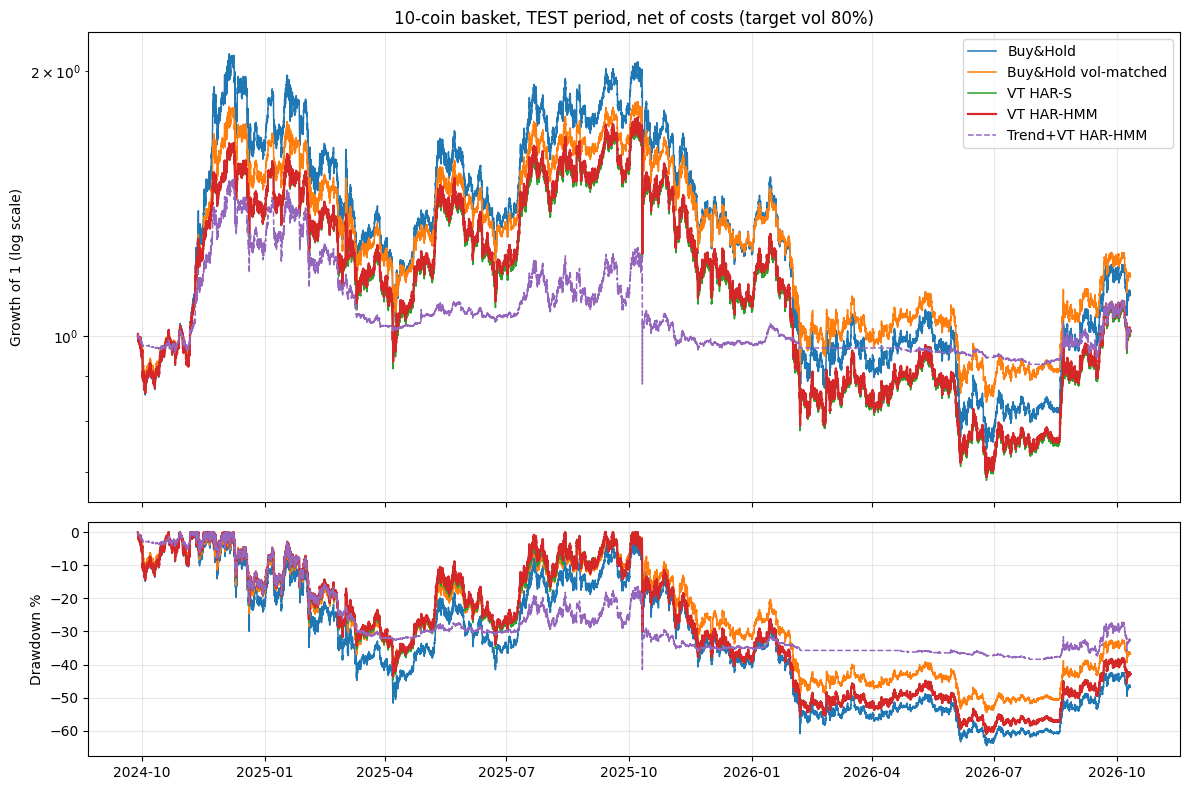


Stage 6 complete. Files are in c:\Users\dell\Downloads\data\backtest\stage6


In [1]:
"""
===============================================================================
STAGE 6 - DOES HAR-HMM VOLATILITY FORECASTING MAKE A BETTER PORTFOLIO?
10-coin basket, volatility-targeted position sizing, walk-forward, after costs
===============================================================================

Question (declared before looking at any result)
------------------------------------------------
Does sizing positions with the HAR-HMM forecast give a better risk/return
profile than (a) buy & hold, (b) simply holding less (vol-matched buy & hold),
and (c) sizing with the HAR-S baseline - AFTER fees, slippage and funding?

How the position is built
-------------------------
  Every day at 00:00 UTC (a bar close) we look at the Stage 5 forecast of the
  next-24h variance for each coin and set

      exposure_coin = min( 1 ,  TARGET_VOL / forecast_vol )        (no leverage)

  Each coin gets 1/10 of the capital, so total exposure is never above 100%.
  The rest sits in cash. If volatility is forecast to be high, exposure shrinks.

Pitfalls handled (each one is a line in the code, search for the tag)
---------------------------------------------------------------------
  [P1] Timing      signal at the close of bar t -> position earns bar t+1 (shift).
  [P2] Leverage    exposure capped at 1x per coin; sigma floored.
  [P3] Costs       fee + slippage on every change of position, plus funding.
  [P4] Turnover    daily decisions + a rebalance band (ignore small changes).
  [P5] Tuning      the target volatility is chosen ONLY on DEV, then frozen.
                   TEST data is not touched until that choice is made.
  [P6] Fair test   the TEST period lies inside every coin's Stage 5 TEST period,
                   so "HAR-HMM is the best model" was never judged on these bars.
  [P7] Benchmarks  buy & hold, vol-matched buy & hold, GARCH, persistence, HAR-S.
  [P8] Stress      slippage that grows with REALISED volatility (same for all models).
  [P9] Cash yield  0% in the main case, 4% as a labelled sensitivity.
  [P10] Noise      block bootstrap on the Sharpe difference (HAR-HMM minus HAR-S).
  [P11] Trend      a trend filter is a SEPARATE edge, so it is reported separately
                   with its own trend-only control.
  [P12] Crashes    the worst weeks are picked by buy & hold only (no cherry-picking).

Inputs : data/processed/{COIN}_30m_features.csv          (Stage 1)
         data/regimes/per_coin_30m_regimes.csv           (Stage 2, for is_oos)
         data/backtest/stage5/cache/{COIN}_forecasts.npz (Stage 5, all 8 forecasts)
Outputs: data/backtest/stage6/*.csv and stage6_portfolio.png
===============================================================================
"""

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# =============================================================================
# CONFIGURATION  (everything here is fixed BEFORE the TEST period is looked at)
# =============================================================================
COINS = ["BTCUSDT", "ETHUSDT", "BNBUSDT", "LTCUSDT", "XMRUSDT",
         "XLMUSDT", "ADAUSDT", "DOGEUSDT", "SOLUSDT", "DOTUSDT"]
INTERVAL = "30m"
BARS_PER_DAY = 48
BARS_PER_YEAR = 48 * 365                 # crypto trades 24/7
DEV_FRAC = 0.60                          # same split rule as Stage 5
STAGE5_MODELS = ["persistence", "EWMA", "GARCH", "GJR-GARCH", "HAR-S", "HMM-own", "HMM-mkt", "HAR-HMM"]

CHAMPION, BASELINE = "HAR-HMM", "HAR-S"  # the real question: CHAMPION vs BASELINE
SIZING_MODELS = ["persistence", "GARCH", "HAR-S", "HAR-HMM"]

# --- position sizing -----------------------------------------------------------
TARGET_GRID = [0.30, 0.40, 0.50, 0.60, 0.80]   # annualised target vol; ONE value is picked on DEV
MAX_EXPOSURE = 1.0                       # [P2] no leverage (no borrowing / funding cost for leverage)
SIGMA_FLOOR = 0.10                       # [P2] never divide by a forecast vol below 10% a year
REBAL_BAND = 0.10                        # [P4] only trade if exposure changes by more than 10 points
TREND_BARS = 200 * 48                    # [P11] 200-day average, fixed in advance (not tuned)

# --- costs ---------------------------------------------------------------------
FEE_BPS = 4.5                            # [P3] taker fee per side (same as Stage 3)
SLIPPAGE_BPS = 1.0                       # [P3] base slippage per side (same as Stage 3)
INCLUDE_FUNDING = True                   # [P3] longs pay funding when rate > 0 (8h rate / 16 bars, as Stage 3)
STRESS_K = 2.0                           # [P8] extra bps per 1% of realised daily vol (3% day -> +6 bps, 10% day -> +20 bps)
CASH_RATE_SENS = 0.04                    # [P9] sensitivity only

# --- statistics & crash windows --------------------------------------------------
N_BOOT, BLOCK_DAYS, SEED = 2000, 10, 42
CRASH_DAYS, N_CRASH = 7, 4

# --- success criteria, written down BEFORE running ------------------------------
#  1 (primary)   champion (pure vol targeting): higher net Sharpe AND shallower max drawdown than buy & hold
#  2 (control)   champion Sharpe above vol-matched buy & hold (otherwise it is just "holding less")
#  3 (secondary) champion Sharpe >= baseline (HAR-S) Sharpe; "indistinguishable" is an honest, acceptable result
#  4 (bonus)     champion net annual return > 0 (depends on the market, not on the model)

BASE_DIR = Path.cwd()
PROCESSED_DIR = BASE_DIR / "data" / "processed"
REGIME_DIR = BASE_DIR / "data" / "regimes"
STAGE5_CACHE = BASE_DIR / "data" / "backtest" / "stage5" / "cache"
OUT_DIR = BASE_DIR / "data" / "backtest" / "stage6"


# =============================================================================
# 1. LOAD DATA  (one table per coin, forecasts from the Stage 5 cache)
# =============================================================================
def load_coin(coin: str) -> pd.DataFrame:
    df = pd.read_csv(PROCESSED_DIR / f"{coin}_{INTERVAL}_features.csv", parse_dates=["open_time"])
    df = df.sort_values("open_time").reset_index(drop=True)
    d = df[["open_time", "close", "log_return"] + (["funding_rate"] if "funding_rate" in df else [])].copy()
    if "funding_rate" not in d:
        d["funding_rate"] = 0.0

    reg = pd.read_csv(REGIME_DIR / f"per_coin_{INTERVAL}_regimes.csv", parse_dates=["open_time"],
                      usecols=["symbol", "open_time", "is_oos"])
    reg = reg[reg["symbol"] == coin][["open_time", "is_oos"]]
    d = d.merge(reg, on="open_time", how="left")                  # left merge keeps the row order
    d["is_oos"] = d["is_oos"].fillna(False).astype(bool)

    cache = STAGE5_CACHE / f"{coin}_forecasts.npz"
    if not cache.exists():
        raise FileNotFoundError(f"{cache} not found - run Stage 5 first (it creates the forecast cache).")
    z = np.load(cache)
    for m in STAGE5_MODELS:
        if len(z[m]) != len(d):
            raise ValueError(f"{coin}: cached forecast length {len(z[m])} != data length {len(d)}. "
                             "Re-run Stage 5 with RECOMPUTE = True.")
        d["f_" + m] = z[m]

    r2 = d["log_return"] ** 2
    d["ret"] = d["close"].pct_change()                            # return earned DURING this bar
    d["rv_past"] = r2.rolling(BARS_PER_DAY).mean()                # last-24h variance, known at t
    d["y_var"] = d["rv_past"].shift(-BARS_PER_DAY)                # Stage 5 "truth" (only used to rebuild the split)
    d["dvol"] = np.sqrt(d["rv_past"] * BARS_PER_DAY)              # realised DAILY vol (fraction), known at t
    d["trend_up"] = d["close"] > d["close"].rolling(TREND_BARS).mean()   # NaN compares as False
    return d


def stage5_cut_time(d: pd.DataFrame) -> pd.Timestamp:
    """Rebuild the exact DEV/TEST cut that Stage 5 used for this coin."""
    ok = d["is_oos"] & d["y_var"].notna()
    for m in STAGE5_MODELS:
        f = d["f_" + m]
        if np.isfinite(f[d["is_oos"]]).mean() > 0.9:
            ok &= f.notna() & (f > 0)
    idx = d.index[ok]
    return d.loc[idx[int(len(idx) * DEV_FRAC)], "open_time"]


def build_panel() -> dict:
    frames, cuts = {}, {}
    for coin in COINS:
        frames[coin] = load_coin(coin)
        cuts[coin] = stage5_cut_time(frames[coin])
        print(f"  {coin}: loaded, Stage 5 TEST starts {cuts[coin]:%Y-%m-%d}")

    # [P6] one common cut = the LATEST Stage 5 cut, so Stage 6 TEST sits inside every coin's Stage 5 TEST
    cut_time = max(cuts.values())

    index = sorted(set().union(*[set(f["open_time"]) for f in frames.values()]))
    index = pd.DatetimeIndex(index)
    valid_all = np.ones(len(index), bool)
    cols = {k: [] for k in ["ret", "fund", "dvol", "trend"]}
    fore = {m: [] for m in SIZING_MODELS}
    for coin in COINS:
        f = frames[coin].set_index("open_time").reindex(index)
        ok = f["is_oos"].fillna(False).astype(bool) & np.isfinite(f["ret"]) & np.isfinite(f["dvol"])
        for m in SIZING_MODELS:
            ok &= np.isfinite(f["f_" + m]) & (f["f_" + m] > 0)
        valid_all &= ok.to_numpy()
        cols["ret"].append(f["ret"].to_numpy(float))
        cols["fund"].append(f["funding_rate"].fillna(0.0).to_numpy(float))
        cols["dvol"].append(f["dvol"].to_numpy(float))
        cols["trend"].append(f["trend_up"].fillna(False).to_numpy(bool))
        for m in SIZING_MODELS:
            fore[m].append(np.sqrt(f["f_" + m].to_numpy(float) * BARS_PER_YEAR))   # annualised forecast vol

    keep = np.where(valid_all)[0]
    times = index[keep]
    gaps = int((np.diff(times.values) != np.timedelta64(30, "m")).sum())
    if gaps:
        print(f"  WARNING: {gaps} gaps in the common window (missing bars are not filled).")

    P = {"times": times.values,
         "ret": np.column_stack(cols["ret"])[keep],
         "fund": np.column_stack(cols["fund"])[keep],
         "dvol": np.column_stack(cols["dvol"])[keep],
         "trend": np.column_stack(cols["trend"])[keep],
         "sigma": {m: np.column_stack(fore[m])[keep] for m in SIZING_MODELS}}
    close_time = pd.DatetimeIndex(times) + pd.Timedelta(minutes=30)
    P["decision"] = np.asarray((close_time.hour == 0) & (close_time.minute == 0))      # [P1] 00:00 UTC closes

    cut_pos = int(np.searchsorted(times.values, np.datetime64(cut_time)))
    if cut_pos < 2000 or cut_pos > len(times) - 2000:
        raise ValueError("DEV or TEST window is too short after aligning all coins.")
    print(f"\n  Common window : {pd.Timestamp(times[0]):%Y-%m-%d} -> {pd.Timestamp(times[-1]):%Y-%m-%d}")
    print(f"  DEV  (pick settings only)   : {pd.Timestamp(times[0]):%Y-%m-%d} -> {pd.Timestamp(times[cut_pos - 1]):%Y-%m-%d}")
    print(f"  TEST (run once, judge here) : {pd.Timestamp(times[cut_pos]):%Y-%m-%d} -> {pd.Timestamp(times[-1]):%Y-%m-%d}")
    return P, cut_pos


def take(P: dict, sl: slice) -> dict:
    """A slice of the panel (used to run DEV without ever touching TEST rows)."""
    return {"times": P["times"][sl], "ret": P["ret"][sl], "fund": P["fund"][sl], "dvol": P["dvol"][sl],
            "trend": P["trend"][sl], "decision": P["decision"][sl],
            "sigma": {m: v[sl] for m, v in P["sigma"].items()}}


# =============================================================================
# 2. POSITIONS  (decision at a 00:00 close -> position held from the NEXT bar)   [P1]
# =============================================================================
def build_exposure(P: dict, model: str = None, target: float = None, use_trend: bool = False) -> np.ndarray:
    """
    Exposure per coin per bar, between 0 and MAX_EXPOSURE.
      model=None  -> fully invested (1.0) unless the trend filter says 0
      model=...   -> min(cap, target / forecast vol)
    """
    T, N = P["ret"].shape
    if model is None:
        desired = np.ones((T, N))
    else:
        sigma = np.maximum(P["sigma"][model], SIGMA_FLOOR)                       # [P2]
        desired = np.minimum(MAX_EXPOSURE, target / sigma)
    if use_trend:
        desired = desired * P["trend"]

    dec = np.where(P["decision"])[0]
    expo = np.zeros((T, N))
    cur = np.zeros(N)
    for k, t in enumerate(dec):
        new = desired[t]
        trade = (np.abs(new - cur) > REBAL_BAND) | ((new == 0) != (cur == 0))   # [P4] band; trend flips always trade
        cur = np.where(trade, new, cur)
        end = dec[k + 1] + 1 if k + 1 < len(dec) else T
        expo[t + 1:end] = cur                                                    # [P1] earns from the NEXT bar on
    return expo


# =============================================================================
# 3. SIMULATION  (returns, costs, funding, cash)
# =============================================================================
def simulate(P: dict, expo: np.ndarray, scale: float, stress: bool = False, cash_rate: float = 0.0) -> dict:
    """
    expo  : (T, n_coins) exposure of each coin;  scale: capital share per coin (1/10 in the basket, 1 alone)
    net   : bar return of the whole account after costs, funding and cash yield
    """
    W = expo * scale
    dW = np.abs(np.diff(W, axis=0, prepend=np.zeros((1, W.shape[1]))))          # trade size per coin
    dvol_known = np.vstack([P["dvol"][:1], P["dvol"][:-1]])                     # realised vol known BEFORE the trade
    bps = FEE_BPS + SLIPPAGE_BPS + (STRESS_K * np.nan_to_num(dvol_known) * 100 if stress else 0.0)   # [P3][P8]
    cost = (dW * bps / 1e4).sum(axis=1)
    funding = (W * P["fund"] / 16).sum(axis=1) if INCLUDE_FUNDING else 0.0      # 8h rate / 16 bars
    gross = W.sum(axis=1)
    net = (W * P["ret"]).sum(axis=1) - cost - funding + (1 - gross) * cash_rate / BARS_PER_YEAR   # [P9]
    return {"net": net, "gross": gross, "turnover": dW.sum(axis=1)}


# =============================================================================
# 4. METRICS, BOOTSTRAP, CRASH WINDOWS
# =============================================================================
def perf(net: np.ndarray, gross: np.ndarray = None, turnover: np.ndarray = None) -> dict:
    eq = np.cumprod(1 + net)
    years = len(net) / BARS_PER_YEAR
    ann = eq[-1] ** (1 / years) - 1
    sd = net.std()
    dd = (eq / np.maximum.accumulate(eq) - 1).min()
    down = np.sqrt(np.mean(np.minimum(net, 0) ** 2))
    out = {"AnnRet_%": ann * 100, "AnnVol_%": sd * np.sqrt(BARS_PER_YEAR) * 100,
           "Sharpe": net.mean() / sd * np.sqrt(BARS_PER_YEAR) if sd > 0 else np.nan,
           "Sortino": net.mean() / down * np.sqrt(BARS_PER_YEAR) if down > 0 else np.nan,
           "MaxDD_%": dd * 100, "Calmar": ann / abs(dd) if dd < 0 else np.nan}
    if gross is not None:
        out["AvgExposure_%"] = gross.mean() * 100
    if turnover is not None:
        out["Turnover_x/yr"] = turnover.sum() / years
    return out


def daily_returns(net: np.ndarray) -> np.ndarray:
    n = len(net) // BARS_PER_DAY
    return (1 + net[:n * BARS_PER_DAY]).reshape(n, BARS_PER_DAY).prod(axis=1) - 1


def bootstrap_sharpe_diff(net_a: np.ndarray, net_b: np.ndarray) -> dict:
    """[P10] Moving-block bootstrap of Sharpe(a) - Sharpe(b) on daily returns (keeps autocorrelation)."""
    a, b = daily_returns(net_a), daily_returns(net_b)
    n, B = len(a), BLOCK_DAYS
    rng = np.random.default_rng(SEED)
    starts = rng.integers(0, n - B + 1, size=(N_BOOT, int(np.ceil(n / B))))
    idx = (starts[:, :, None] + np.arange(B)).reshape(N_BOOT, -1)[:, :n]
    sh = lambda x: x.mean(axis=1) / x.std(axis=1) * np.sqrt(365)
    diff = sh(a[idx]) - sh(b[idx])
    obs = a.mean() / a.std() * np.sqrt(365) - b.mean() / b.std() * np.sqrt(365)
    lo, hi = np.percentile(diff, [2.5, 97.5])
    return {"sharpe_diff": obs, "ci_low": lo, "ci_high": hi, "p_diff<=0": float((diff <= 0).mean())}


def worst_windows(net_bh: np.ndarray, times: np.ndarray) -> list:
    """[P12] Worst non-overlapping CRASH_DAYS windows of BUY & HOLD (chosen without looking at any strategy)."""
    w = CRASH_DAYS * BARS_PER_DAY
    c = np.cumsum(np.log1p(net_bh))
    wret = c[w:] - c[:-w]                                         # window i covers bars i+1 .. i+w
    wret = wret.copy()
    picks = []
    for _ in range(N_CRASH):
        i = int(np.argmin(wret))
        if not np.isfinite(wret[i]):
            break
        picks.append(i + 1)
        wret[max(0, i - w):i + w] = np.inf
    return sorted(picks)


# =============================================================================
# 5. THE FULL RUN
# =============================================================================
def run_stage6() -> None:
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    print("Loading data ...")
    P, cut = build_panel()
    T, N = P["ret"].shape
    scale = 1.0 / N
    dev_sl, test_sl = slice(0, cut), slice(cut, T)

    # -------------------------------------------------------------------------
    # STEP A. choose ONE target volatility on DEV, using the BASELINE (HAR-S)   [P5]
    #         (choosing with the baseline means we do not favour the champion)
    #         Only DEV rows are passed in; TEST rows do not exist for this step.
    # -------------------------------------------------------------------------
    Pdev = take(P, dev_sl)
    grid = {}
    for tv in TARGET_GRID:
        sim = simulate(Pdev, build_exposure(Pdev, BASELINE, tv), scale)
        grid[tv] = perf(sim["net"], sim["gross"], sim["turnover"])
    G = pd.DataFrame(grid).T[["Sharpe", "AnnRet_%", "AnnVol_%", "MaxDD_%", "AvgExposure_%"]]
    target = float(G["Sharpe"].idxmax())
    print("\nSTEP A - choosing the target volatility on DEV only (HAR-S sizing, 10-coin basket)")
    print(G.round(2).to_string())
    print(f"  -> FROZEN target volatility = {target:.0%} a year.  (never changed after this line)")

    # vol-matched buy & hold: a constant fraction of the basket with the same DEV volatility as the champion
    sim_ch = simulate(Pdev, build_exposure(Pdev, CHAMPION, target), scale)
    sim_bh = simulate(Pdev, np.ones((len(Pdev["ret"]), N)), scale)
    c_match = float(min(1.0, sim_ch["net"].std() / sim_bh["net"].std()))
    print(f"  Vol-matched buy & hold holds a constant {c_match:.0%} of the basket (set on DEV, then frozen).")

    # -------------------------------------------------------------------------
    # STEP B. build every strategy on the full window with the frozen settings
    # -------------------------------------------------------------------------
    ones = np.ones((T, N))
    strategies = {"Buy&Hold": ones, "Buy&Hold vol-matched": ones * c_match}
    for m in SIZING_MODELS:
        strategies[f"VT {m}"] = build_exposure(P, m, target)
    strategies["Trend only"] = build_exposure(P, None, None, use_trend=True)                   # [P11]
    for m in ["HAR-S", "HAR-HMM"]:
        strategies[f"Trend+VT {m}"] = build_exposure(P, m, target, use_trend=True)

    CH, BS = f"VT {CHAMPION}", f"VT {BASELINE}"
    sims = {k: simulate(P, v, scale) for k, v in strategies.items()}

    def table(sl: slice, sims_: dict) -> pd.DataFrame:
        return pd.DataFrame({k: perf(s["net"][sl], s["gross"][sl], s["turnover"][sl])
                             for k, s in sims_.items()}).T

    dev_tab, test_tab = table(dev_sl, sims), table(test_sl, sims)
    order = ["AnnRet_%", "AnnVol_%", "Sharpe", "Sortino", "MaxDD_%", "Calmar", "AvgExposure_%", "Turnover_x/yr"]

    print("\n" + "=" * 100)
    print("HEADLINE - 10-coin portfolio, TEST period, net of fees, slippage and funding (cash earns 0%)")
    print("=" * 100)
    print("A) Pure volatility targeting (this isolates the value of the forecast)")
    print(test_tab.loc[["Buy&Hold", "Buy&Hold vol-matched", "VT persistence", "VT GARCH", "VT HAR-S", "VT HAR-HMM"], order].round(2).to_string())
    print("\nB) With a 200-day trend filter (a separate edge; compare with 'Trend only')")
    print(test_tab.loc[["Trend only", "Trend+VT HAR-S", "Trend+VT HAR-HMM"], order].round(2).to_string())
    print("\n(For reference) DEV period, same strategies")
    print(dev_tab[order].round(2).to_string())

    # -------------------------------------------------------------------------
    # STEP C. significance: is HAR-HMM really different from HAR-S?              [P10]
    # -------------------------------------------------------------------------
    net = {k: s["net"][test_sl] for k, s in sims.items()}
    boots = {"HAR-HMM vs HAR-S": bootstrap_sharpe_diff(net[CH], net[BS]),
             "HAR-HMM vs vol-matched B&H": bootstrap_sharpe_diff(net[CH], net["Buy&Hold vol-matched"]),
             "HAR-HMM vs Buy&Hold": bootstrap_sharpe_diff(net[CH], net["Buy&Hold"]),
             "Trend+HAR-HMM vs Trend only": bootstrap_sharpe_diff(net["Trend+VT HAR-HMM"], net["Trend only"])}
    B = pd.DataFrame(boots).T
    print("\nSTEP C - Sharpe difference with 95% block-bootstrap interval (TEST). If the interval contains 0, it is NOT proven.")
    print(B.round(3).to_string())

    # -------------------------------------------------------------------------
    # STEP D. robustness: harsher slippage and cash yield                        [P8][P9]
    # -------------------------------------------------------------------------
    scen = {"base (flat cost, cash 0%)": dict(stress=False, cash_rate=0.0),
            "stress slippage": dict(stress=True, cash_rate=0.0),
            f"cash earns {CASH_RATE_SENS:.0%}": dict(stress=False, cash_rate=CASH_RATE_SENS),
            "stress + cash yield": dict(stress=True, cash_rate=CASH_RATE_SENS)}
    rows = []
    for sname, kw in scen.items():
        for k in ["Buy&Hold", BS, CH, "Trend+VT HAR-HMM"]:
            s = simulate(P, strategies[k], scale, **kw)
            p = perf(s["net"][test_sl])
            rows.append({"scenario": sname, "strategy": k, "AnnRet_%": p["AnnRet_%"], "Sharpe": p["Sharpe"], "MaxDD_%": p["MaxDD_%"]})
    R = pd.DataFrame(rows)
    print("\nSTEP D - ROBUSTNESS (TEST): does the conclusion survive harsher assumptions?")
    print(R.pivot(index="strategy", columns="scenario", values="Sharpe").round(2).to_string())
    print("   (table shows Sharpe; max drawdown and returns are in robustness.csv)")

    # -------------------------------------------------------------------------
    # STEP E. crash windows: worst weeks of buy & hold                           [P12]
    # -------------------------------------------------------------------------
    times_test = P["times"][test_sl]
    w = CRASH_DAYS * BARS_PER_DAY
    crash_rows = []
    for i in worst_windows(net["Buy&Hold"], times_test):
        seg = slice(i, i + w)
        row = {"window": f"{pd.Timestamp(times_test[i]):%Y-%m-%d} -> {pd.Timestamp(times_test[min(i + w, len(times_test)) - 1]):%Y-%m-%d}"}
        for k in ["Buy&Hold", "Buy&Hold vol-matched", BS, CH]:
            row[k + " ret_%"] = ((1 + net[k][seg]).prod() - 1) * 100
        row["HAR-HMM avg exposure_%"] = sims[CH]["gross"][test_sl][seg].mean() * 100
        crash_rows.append(row)
    C = pd.DataFrame(crash_rows)
    print(f"\nSTEP E - THE {N_CRASH} WORST {CRASH_DAYS}-DAY WINDOWS OF BUY & HOLD IN TEST (picked by buy & hold only)")
    print(C.round(1).to_string(index=False))

    # -------------------------------------------------------------------------
    # STEP F. per-coin breakdown (each coin alone, full capital, same frozen settings)
    # -------------------------------------------------------------------------
    pc = []
    for j, coin in enumerate(COINS):
        Pj = {"ret": P["ret"][:, [j]], "fund": P["fund"][:, [j]], "dvol": P["dvol"][:, [j]]}
        res = {}
        for name, expo in [("BH", ones[:, [j]]), ("HS", strategies[BS][:, [j]]), ("HH", strategies[CH][:, [j]])]:
            s = simulate(Pj, expo, 1.0)
            res[name] = perf(s["net"][test_sl], s["gross"][test_sl])
        pc.append({"coin": coin,
                   "BH_ret_%": res["BH"]["AnnRet_%"], "HH_ret_%": res["HH"]["AnnRet_%"],
                   "BH_Sharpe": res["BH"]["Sharpe"], "HS_Sharpe": res["HS"]["Sharpe"], "HH_Sharpe": res["HH"]["Sharpe"],
                   "BH_MaxDD_%": res["BH"]["MaxDD_%"], "HS_MaxDD_%": res["HS"]["MaxDD_%"], "HH_MaxDD_%": res["HH"]["MaxDD_%"],
                   "HH_vol_%": res["HH"]["AnnVol_%"], "HH_avg_exposure_%": res["HH"]["AvgExposure_%"]})
    PC = pd.DataFrame(pc).set_index("coin")
    PC["DD_shallower_than_BH"] = PC["HH_MaxDD_%"] > PC["BH_MaxDD_%"]
    PC["HH_Sharpe_>=_HS"] = PC["HH_Sharpe"] >= PC["HS_Sharpe"]
    print("\nSTEP F - PER-COIN BREAKDOWN (TEST). BH = buy & hold, HS = HAR-S sized, HH = HAR-HMM sized")
    print(PC.round(2).to_string())
    print(f"  HAR-HMM sizing has a shallower max drawdown than buy & hold on {int(PC['DD_shallower_than_BH'].sum())}/{N} coins "
          f"and a Sharpe >= HAR-S on {int(PC['HH_Sharpe_>=_HS'].sum())}/{N} coins.")
    print(f"  Realised vol of the sized coins averages {PC['HH_vol_%'].mean():.0f}% vs a {target:.0%} target "
          "(a large gap would mean the forecast scale is biased).")

    # -------------------------------------------------------------------------
    # STEP G. verdict against the criteria written at the top
    # -------------------------------------------------------------------------
    t = test_tab
    c1 = (t.loc[CH, "Sharpe"] > t.loc["Buy&Hold", "Sharpe"]) and (t.loc[CH, "MaxDD_%"] > t.loc["Buy&Hold", "MaxDD_%"])
    c2 = t.loc[CH, "Sharpe"] > t.loc["Buy&Hold vol-matched", "Sharpe"]
    c3 = t.loc[CH, "Sharpe"] >= t.loc[BS, "Sharpe"]
    c4 = t.loc[CH, "AnnRet_%"] > 0
    sig = B.loc["HAR-HMM vs HAR-S"]
    proven = sig["ci_low"] > 0
    print("\n" + "=" * 100)
    print("VERDICT (criteria were fixed before the run)")
    print("=" * 100)
    yes = lambda b: "PASS" if b else "FAIL"
    print(f"  1. Higher Sharpe AND shallower max drawdown than buy & hold ..... {yes(c1)}")
    print(f"  2. Sharpe above vol-matched buy & hold (not just 'holding less') . {yes(c2)}")
    print(f"  3. Sharpe >= HAR-S sizing ........................................ {yes(c3)}"
          f"   ({'statistically proven' if proven else 'NOT statistically proven: 95% interval includes 0'})")
    print(f"  4. Positive net annual return .................................... {yes(c4)}")

    # -------------------------------------------------------------------------
    # STEP H. chart + files
    # -------------------------------------------------------------------------
    tt = pd.to_datetime(times_test)
    show = ["Buy&Hold", "Buy&Hold vol-matched", BS, CH, "Trend+VT HAR-HMM"]
    fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
    for k in show:
        eq = np.cumprod(1 + net[k])
        ls = "--" if k.startswith("Trend") else "-"
        ax[0].plot(tt, eq, ls, label=k, lw=1.6 if k == CH else 1.1)
        ax[1].plot(tt, (eq / np.maximum.accumulate(eq) - 1) * 100, ls, lw=1.6 if k == CH else 1.1)
    ax[0].set_yscale("log"); ax[0].set_ylabel("Growth of 1 (log scale)")
    ax[0].set_title(f"10-coin basket, TEST period, net of costs (target vol {target:.0%})")
    ax[0].legend(); ax[0].grid(alpha=0.3)
    ax[1].set_ylabel("Drawdown %"); ax[1].grid(alpha=0.3)
    plt.tight_layout()
    fig.savefig(OUT_DIR / "stage6_portfolio.png", dpi=130)
    plt.show()

    test_tab[order].to_csv(OUT_DIR / "portfolio_test_metrics.csv")
    dev_tab[order].to_csv(OUT_DIR / "portfolio_dev_metrics.csv")
    B.to_csv(OUT_DIR / "bootstrap_sharpe_diff.csv")
    R.to_csv(OUT_DIR / "robustness.csv", index=False)
    C.to_csv(OUT_DIR / "crash_windows.csv", index=False)
    PC.to_csv(OUT_DIR / "per_coin_test.csv")
    pd.DataFrame({k: v for k, v in net.items()}, index=tt).to_csv(OUT_DIR / "test_bar_returns.csv")
    print(f"\nStage 6 complete. Files are in {OUT_DIR}")


if __name__ == "__main__":
    run_stage6()

Loading data ...
  BTCUSDT: 1,858 out-of-sample days, Stage 5 TEST starts 2024-09-28
  ETHUSDT: 1,858 out-of-sample days, Stage 5 TEST starts 2024-09-28
  BNBUSDT: 1,858 out-of-sample days, Stage 5 TEST starts 2024-09-28
  LTCUSDT: 1,858 out-of-sample days, Stage 5 TEST starts 2024-09-28
  XMRUSDT: 1,858 out-of-sample days, Stage 5 TEST starts 2024-09-28
  XLMUSDT: 1,858 out-of-sample days, Stage 5 TEST starts 2024-09-28
  ADAUSDT: 1,858 out-of-sample days, Stage 5 TEST starts 2024-09-28
  DOGEUSDT: 1,858 out-of-sample days, Stage 5 TEST starts 2024-09-28
  SOLUSDT: 1,858 out-of-sample days, Stage 5 TEST starts 2024-09-28
  DOTUSDT: 1,857 out-of-sample days, Stage 5 TEST starts 2024-09-27

  DEV  (choose + calibrate) : 2021-09-10 -> 2024-09-28  (11,150 coin-days)
  TEST (run once, judge here): 2024-09-29 -> 2026-10-11  (7,429 coin-days)
  Expected 99% VaR breaches on TEST: about 74

STEP A - choosing the tail shape on DEV only (HAR-S forecasts; fit on early DEV, judged on late DEV)
   

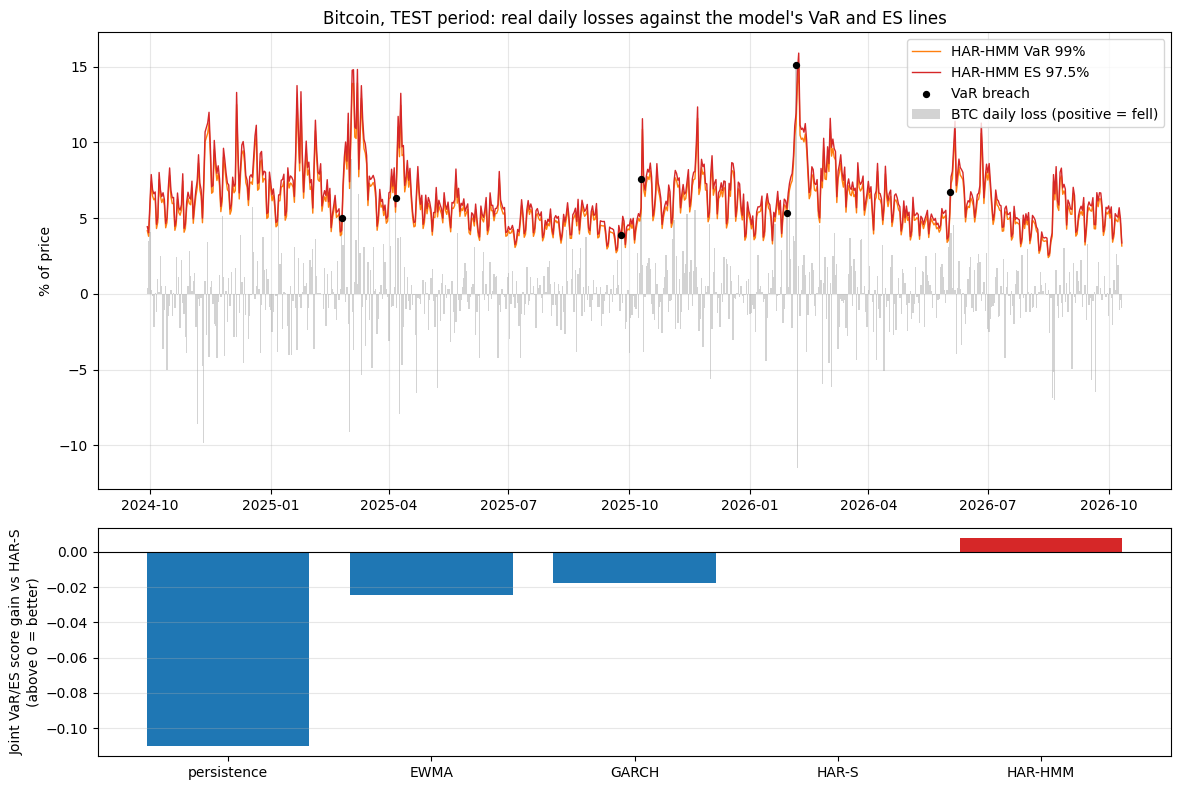


Stage 7 complete. Files are in c:\Users\dell\Downloads\data\backtest\stage7


In [2]:
"""
===============================================================================
STAGE 7 - TAIL RISK: VALUE-AT-RISK AND EXPECTED SHORTFALL BACKTEST
Does a better volatility forecast (HAR-HMM) give better tail-risk numbers?
===============================================================================

Plain-words glossary
--------------------
  VaR 99%   "On a bad day (1 in 100) we expect to lose AT LEAST this much."
  ES 97.5%  "On the worst 2.5% of days, the AVERAGE loss is this much."
            ES tells you how bad it gets once the VaR line is crossed.
  Breach    a day when the real loss was bigger than the VaR number.

How the numbers are made (the same recipe for every model)
----------------------------------------------------------
  1. Every day at 00:00 UTC the model gives a forecast of tomorrow's volatility (sigma).
  2. A "tail shape" turns sigma into a VaR and an ES:
         VaR = sigma x (tail multiplier for 99%)      ES = sigma x (tail multiplier for 97.5%)
     Tail shape candidates: Normal bell curve, Student-t (fatter tails), or the
     model's own past standardised returns ("empirical").
  3. The next day's real loss is compared with these numbers.

Pitfalls handled (search the tag in the code)
---------------------------------------------
  [P1] Timing      forecast made at the 00:00 close; it is judged on the NEXT 24h return only.
  [P2] No overlap  one observation per coin per day (no overlapping windows).
  [P3] Split       same rule as Stage 6: TEST starts at the latest Stage 5 cut, so it
                   lies inside every coin's Stage 5 TEST period.
  [P4] Tail shape  chosen on DEV only, using the BASELINE (HAR-S) so the champion is not
                   favoured; it is fitted on the first part of DEV and judged on the last
                   part of DEV, then refitted on all of DEV and FROZEN.
  [P5] Scale       each model's tail multipliers are calibrated on DEV (a model that is
                   biased high or low is not punished for a pure scale error).
  [P6] Few events  the 99% VaR has few breaches per coin, so results are POOLED over the
                   10 coins, and per-coin tests are shown only as a breakdown.
  [P7] Honest test ES is scored with a proper joint VaR/ES loss (Fissler-Ziegel "FZ0"),
                   compared with a Diebold-Mariano test and a Holm correction.
  [P8] Clustering  coins crash together, so pooled p-values are optimistic; we also count
                   days where several coins breach at once.
  [P9] Declared    success criteria are written below BEFORE running.

Inputs : data/processed/{COIN}_30m_features.csv          (Stage 1)
         data/regimes/per_coin_30m_regimes.csv           (Stage 2, for is_oos)
         data/backtest/stage5/cache/{COIN}_forecasts.npz (Stage 5 forecasts)
Outputs: data/backtest/stage7/*.csv and stage7_tail_risk.png
===============================================================================
"""

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import xlogy
from scipy.stats import binom, chi2, norm, t as student_t

# =============================================================================
# CONFIGURATION  (fixed before looking at TEST results)
# =============================================================================
COINS = ["BTCUSDT", "ETHUSDT", "BNBUSDT", "LTCUSDT", "XMRUSDT",
         "XLMUSDT", "ADAUSDT", "DOGEUSDT", "SOLUSDT", "DOTUSDT"]
INTERVAL = "30m"
BARS_PER_DAY = 48
DEV_FRAC = 0.60                                    # same split rule as Stages 5 and 6
STAGE5_MODELS = ["persistence", "EWMA", "GARCH", "GJR-GARCH", "HAR-S", "HMM-own", "HMM-mkt", "HAR-HMM"]

MODELS = ["persistence", "EWMA", "GARCH", "HAR-S", "HAR-HMM"]    # models compared here
CHAMPION, BASELINE = "HAR-HMM", "HAR-S"

VAR_LEVEL = 0.99                                   # VaR confidence level  (tail probability 1%)
ES_LEVEL = 0.975                                   # ES confidence level   (tail probability 2.5%)
TAIL_SHAPES = ["normal", "student_t", "empirical"]
SELECT_FRAC = 0.60                                 # inside DEV: first 60% fits shapes, last 40% judges them

DM_LAG = 5                                         # Newey-West lag (days) for the Diebold-Mariano test
ALPHA = 0.05
N_BOOT, BLOCK_DAYS, SEED = 2000, 5, 42
MIN_CLUSTER = 3                                    # "many coins breach together" = at least 3 on one day

# --- success criteria, written down BEFORE running --------------------------------
#  C1 VaR coverage    : champion's pooled 99% breach rate is not significantly different from 1% (Kupiec p >= 0.05)
#  C2 ES calibration  : realised average tail loss / predicted ES (97.5%) has a 95% interval that contains 1.0
#  C3 Tail accuracy   : champion's FZ0 loss is lower than the baseline's (HAR-S)          [point estimate]
#  C4 ... and proven  : the improvement over HAR-S is significant after Holm correction    [bonus, may well fail]

BASE_DIR = Path.cwd()
PROCESSED_DIR = BASE_DIR / "data" / "processed"
REGIME_DIR = BASE_DIR / "data" / "regimes"
STAGE5_CACHE = BASE_DIR / "data" / "backtest" / "stage5" / "cache"
OUT_DIR = BASE_DIR / "data" / "backtest" / "stage7"


# =============================================================================
# 1. LOAD: one row per coin per DAY (00:00 UTC close)
# =============================================================================
def load_coin_daily(coin: str):
    """Returns (daily table, Stage 5 cut time) for one coin."""
    df = pd.read_csv(PROCESSED_DIR / f"{coin}_{INTERVAL}_features.csv", parse_dates=["open_time"])
    df = df.sort_values("open_time").reset_index(drop=True)
    d = df[["open_time", "close", "log_return"]].copy()
    reg = pd.read_csv(REGIME_DIR / f"per_coin_{INTERVAL}_regimes.csv", parse_dates=["open_time"],
                      usecols=["symbol", "open_time", "is_oos"])
    reg = reg[reg["symbol"] == coin][["open_time", "is_oos"]]
    d = d.merge(reg, on="open_time", how="left")
    d["is_oos"] = d["is_oos"].fillna(False).astype(bool)

    cache = STAGE5_CACHE / f"{coin}_forecasts.npz"
    if not cache.exists():
        raise FileNotFoundError(f"{cache} not found - run Stage 5 first.")
    z = np.load(cache)
    for m in STAGE5_MODELS:
        if len(z[m]) != len(d):
            raise ValueError(f"{coin}: forecast length differs from data length. Re-run Stage 5 with RECOMPUTE = True.")
        d["f_" + m] = z[m]

    # --- rebuild the exact Stage 5 DEV/TEST cut for this coin (same rules as Stage 5) --------
    r2 = d["log_return"] ** 2
    y_var = r2.rolling(BARS_PER_DAY).mean().shift(-BARS_PER_DAY)
    ok = d["is_oos"] & y_var.notna()
    for m in STAGE5_MODELS:
        f = d["f_" + m]
        if np.isfinite(f[d["is_oos"]]).mean() > 0.9:
            ok &= f.notna() & (f > 0)
    idx = d.index[ok]
    cut_time = d.loc[idx[int(len(idx) * DEV_FRAC)], "open_time"]

    # --- daily table: decision at each 00:00 UTC close  [P1][P2] ------------------------------
    close_time = d["open_time"] + pd.Timedelta(minutes=30)
    dec = d[(close_time.dt.hour == 0) & (close_time.dt.minute == 0)].copy()
    dec["next_close"] = dec["close"].shift(-1)
    dec["next_open_time"] = dec["open_time"].shift(-1)
    dec = dec[(dec["next_open_time"] - dec["open_time"]) == pd.Timedelta(days=1)]        # drop days with gaps
    out = pd.DataFrame({"coin": coin, "date": dec["open_time"] + pd.Timedelta(minutes=30),
                        "r": np.log(dec["next_close"] / dec["close"]),                   # NEXT 24h log return
                        "is_oos": dec["is_oos"]})
    for m in MODELS:
        out["sig_" + m] = np.sqrt(dec["f_" + m] * BARS_PER_DAY)                          # daily volatility forecast
    out = out[out["is_oos"]].drop(columns="is_oos")
    ok = np.isfinite(out["r"])
    for m in MODELS:
        ok &= np.isfinite(out["sig_" + m]) & (out["sig_" + m] > 0)
    return out[ok].reset_index(drop=True), cut_time


# =============================================================================
# 2. TAIL SHAPES: how many "sigmas" is the 99% VaR / 97.5% ES?
#    Work with standardised LOSS  lz = -r / sigma  (positive = loss)
# =============================================================================
class TailShape:
    """Fitted on standardised returns z = r/sigma. Gives (VaR, ES) in units of sigma for a tail probability."""

    def __init__(self, kind: str, z: np.ndarray):
        self.kind = kind
        if kind == "normal":
            self.scale = float(np.sqrt(np.mean(z ** 2)))                      # [P5] scale learned on DEV
        elif kind == "student_t":
            df, _, scale = student_t.fit(z, floc=0.0)
            self.df, self.scale = float(np.clip(df, 2.1, 200.0)), float(scale)
        elif kind == "empirical":
            self.loss = np.sort(-z)                                           # standardised losses
        else:
            raise ValueError(kind)

    def risk(self, tau: float):
        """(VaR, ES) for tail probability tau, both in sigma units."""
        if self.kind == "normal":
            q = norm.ppf(1 - tau)
            return self.scale * q, self.scale * norm.pdf(q) / tau
        if self.kind == "student_t":
            q = student_t.ppf(1 - tau, self.df)
            es = student_t.pdf(q, self.df) / tau * (self.df + q * q) / (self.df - 1)
            return self.scale * q, self.scale * es
        var = np.quantile(self.loss, 1 - tau)
        return float(var), float(self.loss[self.loss >= var].mean())

    def describe(self) -> str:
        if self.kind == "normal":
            return f"normal (scale {self.scale:.2f})"
        if self.kind == "student_t":
            return f"student_t (df {self.df:.1f}, scale {self.scale:.2f})"
        return f"empirical ({len(self.loss):,} DEV days)"


def risk_numbers(sig: np.ndarray, shape: TailShape) -> dict:
    """Daily VaR99, VaR97.5 and ES97.5 (positive = loss, in return units)."""
    v99, _ = shape.risk(1 - VAR_LEVEL)
    v975, e975 = shape.risk(1 - ES_LEVEL)
    return {"var99": sig * v99, "var975": sig * v975, "es975": sig * e975}


# =============================================================================
# 3. SCORING AND TESTS
# =============================================================================
def fz0(loss: np.ndarray, var: np.ndarray, es: np.ndarray, tau: float) -> np.ndarray:
    """
    Fissler-Ziegel FZ0 loss for a (VaR, ES) pair - the standard way to score both together. Lower = better.
    It is minimised only by the TRUE VaR and ES, so a model cannot win by being too cautious or too bold.
    """
    return (loss >= var) * (loss - var) / (tau * es) + var / es + np.log(es) - 1.0


def kupiec(n: int, x: int, p: float) -> float:
    """Kupiec test: is the breach count x out of n consistent with probability p?  Returns the p-value."""
    if n == 0:
        return np.nan
    ph = x / n
    ll0 = xlogy(n - x, 1 - p) + xlogy(x, p)
    ll1 = xlogy(n - x, 1 - ph) + xlogy(x, ph)
    return float(1 - chi2.cdf(max(2 * (ll1 - ll0), 0.0), 1))


def christoffersen(hits: np.ndarray, p: float):
    """Independence and conditional-coverage p-values (are breaches clustered in time?)."""
    h = hits.astype(int)
    a, b = h[:-1], h[1:]
    n00, n01 = int(((a == 0) & (b == 0)).sum()), int(((a == 0) & (b == 1)).sum())
    n10, n11 = int(((a == 1) & (b == 0)).sum()), int(((a == 1) & (b == 1)).sum())
    if n01 + n11 == 0 or (n00 + n01) == 0:
        return np.nan, np.nan
    pi01 = n01 / max(n00 + n01, 1)
    pi11 = n11 / max(n10 + n11, 1)
    pi = (n01 + n11) / (n00 + n01 + n10 + n11)
    ll_ind = xlogy(n00 + n10, 1 - pi) + xlogy(n01 + n11, pi)
    ll_mkv = xlogy(n00, 1 - pi01) + xlogy(n01, pi01) + xlogy(n10, 1 - pi11) + xlogy(n11, pi11)
    lr_ind = max(2 * (ll_mkv - ll_ind), 0.0)
    x, n = int(h.sum()), len(h)
    lr_uc = max(2 * ((xlogy(n - x, 1 - x / n) + xlogy(x, x / n)) - (xlogy(n - x, 1 - p) + xlogy(x, p))), 0.0)
    return float(1 - chi2.cdf(lr_ind, 1)), float(1 - chi2.cdf(lr_uc + lr_ind, 2))


def dm_test(loss_rival: np.ndarray, loss_model: np.ndarray, lag: int = DM_LAG):
    """Diebold-Mariano, one-sided. H1: 'model' has LOWER loss than 'rival'. Newey-West errors."""
    d = loss_rival - loss_model
    n = len(d)
    dm = d - d.mean()
    var = (dm @ dm) / n
    for k in range(1, lag + 1):
        var += 2 * (1 - k / (lag + 1)) * (dm[k:] @ dm[:-k]) / n
    tstat = d.mean() / np.sqrt(var / n)
    return float(tstat), float(1 - norm.cdf(tstat))


def holm(p) -> np.ndarray:
    p = np.asarray(p, float)
    order = np.argsort(p)
    adj, run, m = np.empty_like(p), 0.0, len(p)
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i])
        adj[i] = min(run, 1.0)
    return adj


def es_ratio_bootstrap(day_idx: np.ndarray, loss: np.ndarray, var: np.ndarray, es: np.ndarray, n_days: int):
    """
    ES calibration: (average real loss on breach days) / (average predicted ES on those days).
    1.0 = right.  Above 1 = ES too small (risk underestimated).  Below 1 = ES too big.
    The 95% interval comes from resampling blocks of DAYS (keeps coins that crash together together).
    """
    hit = loss >= var
    if hit.sum() == 0:
        return np.nan, np.nan, np.nan
    obs = loss[hit].sum() / es[hit].sum()
    sum_loss = np.bincount(day_idx[hit], weights=loss[hit], minlength=n_days)
    sum_es = np.bincount(day_idx[hit], weights=es[hit], minlength=n_days)
    rng = np.random.default_rng(SEED)
    B = BLOCK_DAYS
    starts = rng.integers(0, n_days - B + 1, size=(N_BOOT, int(np.ceil(n_days / B))))
    idx = (starts[:, :, None] + np.arange(B)).reshape(N_BOOT, -1)[:, :n_days]
    num, den = sum_loss[idx].sum(axis=1), sum_es[idx].sum(axis=1)
    ratio = num[den > 0] / den[den > 0]
    lo, hi = np.percentile(ratio, [2.5, 97.5])
    return float(obs), float(lo), float(hi)


# =============================================================================
# 4. THE FULL RUN
# =============================================================================
def run_stage7() -> None:
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    print("Loading data ...")
    daily, cuts = {}, {}
    for coin in COINS:
        daily[coin], cuts[coin] = load_coin_daily(coin)
        print(f"  {coin}: {len(daily[coin]):,} out-of-sample days, Stage 5 TEST starts {cuts[coin]:%Y-%m-%d}")
    cut_time = max(cuts.values())                                              # [P3]
    D = pd.concat(daily.values(), ignore_index=True)
    dev = D[D["date"] <= cut_time].reset_index(drop=True)
    test = D[D["date"] > cut_time].reset_index(drop=True)
    print(f"\n  DEV  (choose + calibrate) : {dev['date'].min():%Y-%m-%d} -> {dev['date'].max():%Y-%m-%d}  ({len(dev):,} coin-days)")
    print(f"  TEST (run once, judge here): {test['date'].min():%Y-%m-%d} -> {test['date'].max():%Y-%m-%d}  ({len(test):,} coin-days)")
    print(f"  Expected {VAR_LEVEL:.0%} VaR breaches on TEST: about {len(test) * (1 - VAR_LEVEL):.0f}")

    tau_v, tau_e = 1 - VAR_LEVEL, 1 - ES_LEVEL

    # -------------------------------------------------------------------------
    # STEP A. choose the tail shape on DEV, with the BASELINE only            [P4]
    #         fit on the early part of DEV, judge on the late part of DEV
    # -------------------------------------------------------------------------
    split2 = dev["date"].quantile(SELECT_FRAC)
    fit_part, sel_part = dev[dev["date"] <= split2], dev[dev["date"] > split2]
    z_fit = (fit_part["r"] / fit_part["sig_" + BASELINE]).to_numpy()
    rows = []
    for kind in TAIL_SHAPES:
        shape = TailShape(kind, z_fit)
        rk = risk_numbers(sel_part["sig_" + BASELINE].to_numpy(), shape)
        loss = -sel_part["r"].to_numpy()
        rows.append({"tail_shape": kind, "FZ0_loss": fz0(loss, rk["var975"], rk["es975"], tau_e).mean(),
                     "VaR99_breach_%": (loss >= rk["var99"]).mean() * 100,
                     "ES_ratio": loss[loss >= rk["var975"]].sum() / rk["es975"][loss >= rk["var975"]].sum(),
                     "fitted": shape.describe()})
    S = pd.DataFrame(rows).set_index("tail_shape")
    best_kind = S["FZ0_loss"].idxmin()
    print("\nSTEP A - choosing the tail shape on DEV only (HAR-S forecasts; fit on early DEV, judged on late DEV)")
    print(S.round(3).to_string())
    print(f"  -> FROZEN tail shape = '{best_kind}'  (refitted on ALL of DEV for every model; never changed after this line)")

    shapes = {m: TailShape(best_kind, (dev["r"] / dev["sig_" + m]).to_numpy()) for m in MODELS}
    print("  Calibrated on DEV:", "; ".join(f"{m}: {shapes[m].describe()}" for m in MODELS))

    # -------------------------------------------------------------------------
    # STEP B. VaR / ES for every model on TEST
    # -------------------------------------------------------------------------
    test = test.sort_values(["date", "coin"]).reset_index(drop=True)
    loss = -test["r"].to_numpy()
    dates = np.array(sorted(test["date"].unique()))
    day_idx = np.searchsorted(dates, test["date"].to_numpy())
    n_days = len(dates)
    R = {m: risk_numbers(test["sig_" + m].to_numpy(), shapes[m]) for m in MODELS}
    FZ = {m: fz0(loss, R[m]["var975"], R[m]["es975"], tau_e) for m in MODELS}

    # -------------------------------------------------------------------------
    # STEP C. is the 99% VaR right? (breach counts)                          [P6][P8]
    # -------------------------------------------------------------------------
    rows = []
    for m in MODELS:
        hit = loss >= R[m]["var99"]
        n, x = len(hit), int(hit.sum())
        per_coin_ok, per_coin_ind = 0, 0
        for coin in COINS:
            hc = hit[(test["coin"] == coin).to_numpy()]
            if len(hc) > 50:
                per_coin_ok += int(kupiec(len(hc), int(hc.sum()), tau_v) >= ALPHA)
                p_ind, _ = christoffersen(hc, tau_v)
                per_coin_ind += int(np.isnan(p_ind) or p_ind >= ALPHA)
        by_day = pd.Series(hit).groupby(day_idx).sum()
        rows.append({"model": m, "breach_%": x / n * 100, "breaches": x, "expected": n * tau_v,
                     "Kupiec_p": kupiec(n, x, tau_v), "coins_ok_Kupiec": f"{per_coin_ok}/{len(COINS)}",
                     "coins_not_clustered": f"{per_coin_ind}/{len(COINS)}",
                     f"days_with_>={MIN_CLUSTER}_breaches": int((by_day >= MIN_CLUSTER).sum())})
    V = pd.DataFrame(rows).set_index("model")
    p_cluster = 1 - binom.cdf(MIN_CLUSTER - 1, len(COINS), tau_v)
    print("\n" + "=" * 100)
    print(f"STEP C - {VAR_LEVEL:.0%} VaR on TEST: are the breaches the right number? (target {tau_v:.1%}; Kupiec p >= {ALPHA} = consistent)")
    print("=" * 100)
    print(V.round(3).to_string())
    print(f"  If coins crashed independently, only about {n_days * p_cluster:.2f} days would have >= {MIN_CLUSTER} simultaneous breaches. "
          "More than that means the coins crash together, and pooled p-values above are optimistic.")

    # -------------------------------------------------------------------------
    # STEP D. is the ES right? how bad is it beyond VaR?                        [P7]
    # -------------------------------------------------------------------------
    rows = []
    for m in MODELS:
        ratio, lo, hi = es_ratio_bootstrap(day_idx, loss, R[m]["var975"], R[m]["es975"], n_days)
        hit = loss >= R[m]["var975"]
        rows.append({"model": m, f"breach_{ES_LEVEL:.1%}_%": hit.mean() * 100,
                     "avg_loss_when_breach_%": loss[hit].mean() * 100, "avg_predicted_ES_%": R[m]["es975"][hit].mean() * 100,
                     "ES_ratio": ratio, "ratio_95%_low": lo, "ratio_95%_high": hi,
                     "ES_ok": bool(lo <= 1 <= hi)})
    E = pd.DataFrame(rows).set_index("model")
    print("\n" + "=" * 100)
    print(f"STEP D - EXPECTED SHORTFALL {ES_LEVEL:.1%} on TEST: real average loss on bad days / predicted ES  (1.00 = perfect, >1 = risk underestimated)")
    print("=" * 100)
    print(E.round(3).to_string())

    # -------------------------------------------------------------------------
    # STEP E. joint VaR+ES score and the head-to-head tests                     [P7]
    # -------------------------------------------------------------------------
    daily_fz = {m: pd.Series(FZ[m]).groupby(day_idx).mean().to_numpy() for m in MODELS}      # average over coins per day
    rivals = [m for m in MODELS if m != CHAMPION]
    p_raw = [dm_test(daily_fz[m], daily_fz[CHAMPION])[1] for m in rivals]
    p_holm = holm(p_raw)
    P = pd.DataFrame({"champion_better_than": rivals, "p_raw": p_raw, "p_holm": p_holm,
                      "significant": p_holm < ALPHA}).set_index("champion_better_than")
    F = pd.DataFrame({"FZ0_loss": {m: FZ[m].mean() for m in MODELS}})
    F["gain_vs_HAR-S"] = F.loc[BASELINE, "FZ0_loss"] - F["FZ0_loss"]      # FZ0 can be negative, so use a plain difference
    print("\n" + "=" * 100)
    print("STEP E - JOINT VaR + ES SCORE (FZ0 loss, lower = better; gain_vs_HAR-S: POSITIVE = better than HAR-S)")
    print("=" * 100)
    print(F.round(4).to_string())
    print(f"\n  Is {CHAMPION} significantly better than each rival? (one-sided Diebold-Mariano, Holm-corrected across rivals)")
    print(P.round(4).to_string())

    # -------------------------------------------------------------------------
    # STEP F. per-coin breakdown: HAR-HMM vs HAR-S
    # -------------------------------------------------------------------------
    rows = []
    for coin in COINS:
        mk = (test["coin"] == coin).to_numpy()
        row = {"coin": coin, "days": int(mk.sum())}
        for m, tag in [(CHAMPION, "HH"), (BASELINE, "HS")]:
            hit = loss[mk] >= R[m]["var99"][mk]
            row[f"{tag}_breaches99"] = int(hit.sum())
            h975 = loss[mk] >= R[m]["var975"][mk]
            row[f"{tag}_ES_ratio"] = loss[mk][h975].sum() / R[m]["es975"][mk][h975].sum() if h975.any() else np.nan
            row[f"{tag}_FZ0"] = FZ[m][mk].mean()
        row["FZ0_gain_vs_HS"] = row["HS_FZ0"] - row["HH_FZ0"]            # positive = HAR-HMM better
        row["expected_breaches"] = mk.sum() * tau_v
        rows.append(row)
    C = pd.DataFrame(rows).set_index("coin")
    print("\nSTEP F - PER-COIN BREAKDOWN (HH = HAR-HMM, HS = HAR-S). Per-coin counts are small, read them as a guide only.")
    print(C.round(3).to_string())
    print(f"  HAR-HMM has a lower FZ0 loss than HAR-S on {int((C['FZ0_gain_vs_HS'] > 0).sum())}/{len(COINS)} coins.")

    # -------------------------------------------------------------------------
    # STEP G. verdict against the criteria written at the top                   [P9]
    # -------------------------------------------------------------------------
    c1 = V.loc[CHAMPION, "Kupiec_p"] >= ALPHA
    c2 = bool(E.loc[CHAMPION, "ES_ok"])
    c3 = F.loc[CHAMPION, "FZ0_loss"] < F.loc[BASELINE, "FZ0_loss"]
    c4 = bool(P.loc[BASELINE, "significant"])
    yes = lambda b: "PASS" if b else "FAIL"
    print("\n" + "=" * 100)
    print("VERDICT (criteria were fixed before the run)")
    print("=" * 100)
    print(f"  C1. 99% VaR breach rate consistent with 1% (Kupiec) ........... {yes(c1)}   "
          f"(breach rate {V.loc[CHAMPION, 'breach_%']:.2f}%, p = {V.loc[CHAMPION, 'Kupiec_p']:.3f})")
    print(f"  C2. ES calibrated (ratio interval contains 1.0) ................ {yes(c2)}   "
          f"(ratio {E.loc[CHAMPION, 'ES_ratio']:.2f}, 95% [{E.loc[CHAMPION, 'ratio_95%_low']:.2f}, {E.loc[CHAMPION, 'ratio_95%_high']:.2f}])")
    print(f"  C3. Lower joint VaR/ES loss than HAR-S ......................... {yes(c3)}   "
          f"(gain {F.loc[CHAMPION, 'gain_vs_HAR-S']:+.4f}; positive = better)")
    print(f"  C4. ...and statistically proven vs HAR-S (Holm) ................ {yes(c4)}   "
          f"(p_holm = {P.loc[BASELINE, 'p_holm']:.3f})")

    # -------------------------------------------------------------------------
    # STEP H. chart + files
    # -------------------------------------------------------------------------
    fig, ax = plt.subplots(2, 1, figsize=(12, 8), gridspec_kw={"height_ratios": [2, 1]})
    mk = (test["coin"] == "BTCUSDT").to_numpy()
    td = pd.to_datetime(test.loc[mk, "date"])
    ax[0].bar(td, loss[mk] * 100, color="lightgray", width=1.0, label="BTC daily loss (positive = fell)")
    ax[0].plot(td, R[CHAMPION]["var99"][mk] * 100, color="tab:orange", lw=1, label=f"{CHAMPION} VaR {VAR_LEVEL:.0%}")
    ax[0].plot(td, R[CHAMPION]["es975"][mk] * 100, color="tab:red", lw=1, label=f"{CHAMPION} ES {ES_LEVEL:.1%}")
    hb = loss[mk] >= R[CHAMPION]["var99"][mk]
    ax[0].scatter(td[hb], loss[mk][hb] * 100, color="black", s=18, zorder=3, label="VaR breach")
    ax[0].set_ylabel("% of price"); ax[0].set_title("Bitcoin, TEST period: real daily losses against the model's VaR and ES lines")
    ax[0].legend(loc="upper right"); ax[0].grid(alpha=0.3)
    colors = ["tab:red" if m == CHAMPION else "tab:blue" for m in MODELS]
    ax[1].bar(MODELS, F.loc[MODELS, "gain_vs_HAR-S"], color=colors)
    ax[1].axhline(0, color="black", lw=0.8)
    ax[1].set_ylabel("Joint VaR/ES score gain vs HAR-S\n(above 0 = better)"); ax[1].grid(alpha=0.3, axis="y")
    plt.tight_layout()
    fig.savefig(OUT_DIR / "stage7_tail_risk.png", dpi=130)
    plt.show()

    S.to_csv(OUT_DIR / "tail_shape_selection.csv")
    V.to_csv(OUT_DIR / "var_coverage.csv")
    E.to_csv(OUT_DIR / "es_calibration.csv")
    F.to_csv(OUT_DIR / "fz0_scores.csv")
    P.to_csv(OUT_DIR / "dm_tests.csv")
    C.to_csv(OUT_DIR / "per_coin_breakdown.csv")
    out = test[["coin", "date", "r"]].copy()
    for m in MODELS:
        out[f"{m}_VaR99"], out[f"{m}_ES975"] = R[m]["var99"], R[m]["es975"]
    out.to_csv(OUT_DIR / "test_daily_var_es.csv", index=False)
    print(f"\nStage 7 complete. Files are in {OUT_DIR}")


if __name__ == "__main__":
    run_stage7()